In [1]:
from google.colab import drive
# ============================================================
# MOUNT DRIVE
# ============================================================

drive.mount(
    "/content/drive",
    force_remount=False
)

Mounted at /content/drive


# TS pcaHL95 CROSS-SESSION GOODNESS-OF-FIT FIGURE


LOADING TS PERMUTATION FILE
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/perm_single_voxel_TS_pcaHL95_raw_4ori_4sf_grid5_OLS_N1000.pkl

Permutation metadata:
subjects            : [1, 2, 3, 4, 5, 6, 7, 8]
rois                : ['V1', 'V2', 'V3', 'hV4']
nsessions           : 30
nperms              : 1000
pca_type            : pcaHL
pca_pct_var         : 95
ridge               : 0
which_prf_grid      : 5

Subjects: [1, 2, 3, 4, 5, 6, 7, 8]
ROIs: ['V1', 'V2', 'V3', 'hV4']
Permutations: 1000

Permutation matrix shape: (8, 4, 1000, 30, 30)

LOADING OBSERVED FAST CROSS-SESSION FILES
S01 V1 : 1350/1350 voxels retained
S02 V1 : 1102/1102 voxels retained
S03 V1 : 1254/1254 voxels retained
S04 V1 : 877/877 voxels retained
S05 V1 : 1113/1113 voxels retained
S06 V1 : 1121/1127 voxels retained
S07 V1 : 1142/1142 voxels retained
S08 V1 : 1074/1074 voxels retained

HDF5 ↔ PERMUTATION OBSERVED-MATRIX CHECK
V1 : max absolute difference = 2.980232239e-08

Computing V1 permutation correlati

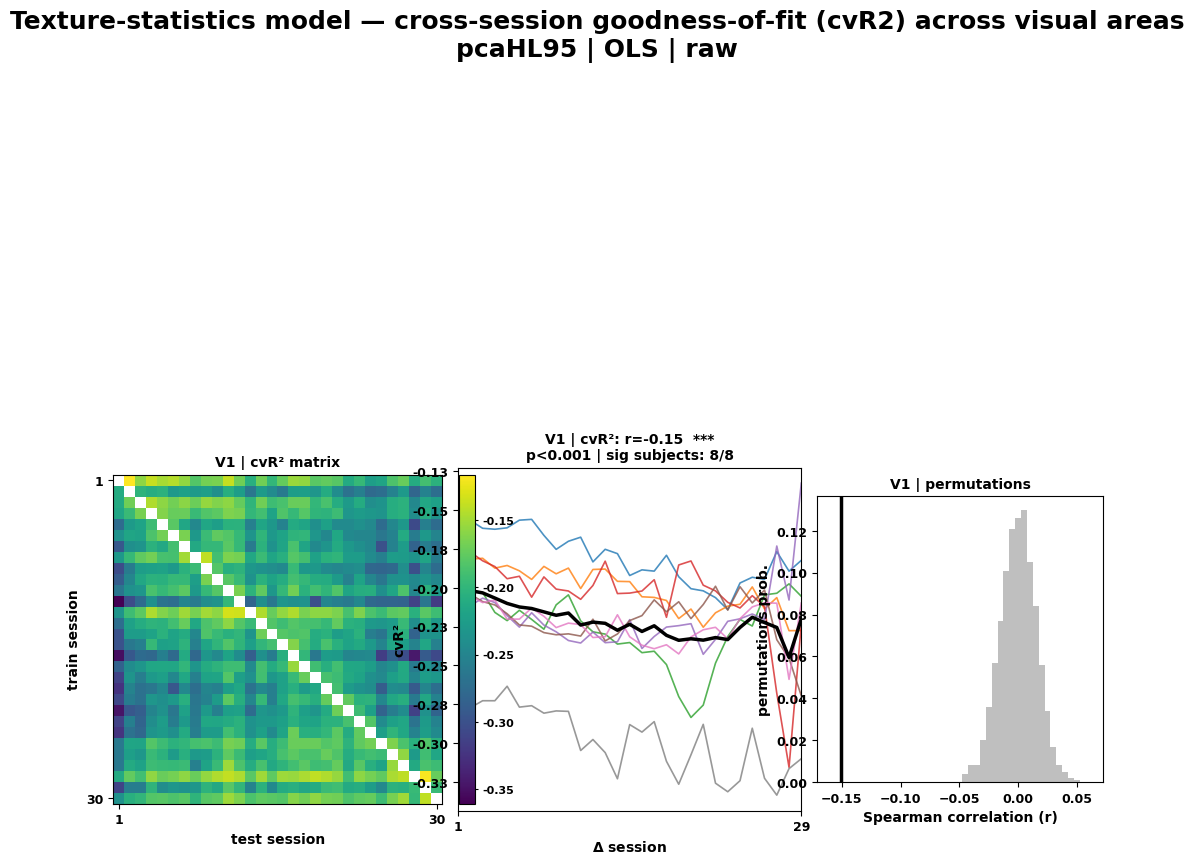


DONE
Saved figure to:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/single_voxel_figures/TS_pcaHL95_allSubjects_V1-V2-V3-hV4_cvR2_spearman_cross_session.png


In [ ]:
# ============================================================
# TS pcaHL95 CROSS-SESSION GOODNESS-OF-FIT FIGURE
#
# Figure structure:
#   LEFT   = mean 30x30 train × test GOF matrix
#   MIDDLE = each subject's GOF as a function of session lag
#   RIGHT  = permutation null distribution of lag correlation
#
# Observed data:
#   FAST_CROSS_SESSION HDF5 files
#
# Permutation data:
#   perm_TS_pcaHL95_4ori_4sf_grid5_OLS_N1000.pkl
#
# Current configuration:
#   pcaHL95
#   raw features/betas
#   OLS
#   Pearson prediction accuracy
#   Spearman correlation with session lag
# ============================================================

import os
import pickle
import h5py
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import pearsonr, spearmanr
from matplotlib.ticker import FormatStrFormatter, FuncFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ============================================================
# USER SETTINGS
# ============================================================
PCA_TYPE = "pcaHL"
PCA_PCT = 95


ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel"
)

FIT_ROOT = (
    ROOT
    / "model_fits"
)

DRIFT_DIR = (
    ROOT
    / "drift_results"
)

PERM_FILE = (
    DRIFT_DIR
    / (
        f"perm_single_voxel_TS_"
        f"{PCA_TYPE}{PCA_PCT}_raw_"
        f"4ori_4sf_grid5_OLS_N1000.pkl"
    )
)

OUT_DIR = (
    DRIFT_DIR
    / "single_voxel_figures"
)

SUMMARY_DIR = (
    DRIFT_DIR
    / "drift_summaries"
)


# ------------------------------------------------------------
# Main analysis settings
# ------------------------------------------------------------

SUBJECTS_TO_USE = [
    1, 2, 3, 4,
    5, 6, 7, 8
]

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4"
]

NSESSIONS = 30



# ------------------------------------------------------------
# Prediction metric shown in heatmap / middle plot
#
# "pearson" = prediction Pearson r
# "cvR2"    = cross-validated R²
# ------------------------------------------------------------

GOF_METRIC = "cvR2"

# ------------------------------------------------------------
# How GOF is related to session lag
#
# "spearman" recommended for your current analysis
# "pearson" also supported
# ------------------------------------------------------------

CORR_METHOD = "spearman"

# ------------------------------------------------------------
# Which drift statistic is used for significance / histogram
#
# "corr"  = correlation between GOF and session lag
# "slope" = OLS slope of GOF ~ session lag
# ------------------------------------------------------------

DRIFT_METRIC = "corr"   # "corr" or "slope"
# ============================================================
# DISPLAY SETTINGS
# ============================================================

FIG_W = 11
FIG_H = 12

WSPACE = 0.05
HSPACE = 0.55

TOP = 0.9
BOTTOM = 0.04

HIST_BINS = 20

TITLE_FS = 18
SUBTITLE_FS = 10
LABEL_FS = 10
TICK_FS = 9
CBAR_FS = 8

LINEWIDTH_MEAN = 2.5
LINEWIDTH_SUBJ = 1.2
ALPHA_SUBJ = 0.8

plt.rcParams["font.weight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["axes.titleweight"] = "bold"


# ============================================================
# OUTPUT NAME
# ============================================================

OUT_FIG = (
    OUT_DIR
    / (
        f"TS_{PCA_TYPE}{PCA_PCT}_"
        f"allSubjects_V1-V2-V3-hV4_"
        f"{GOF_METRIC}_"
        f"{CORR_METHOD}_"
        f"{DRIFT_METRIC}_"
        f"cross_session.png"
    )
)


# ============================================================
# FILE HELPER
# ============================================================

def get_ts_fit_file(
    subject,
    roi
):

    s = f"S{subject:02d}"

    return (
        FIT_ROOT
        / s
        / "FAST_CROSS_SESSION"
        / (
            f"{s}_{roi}_"
            f"texture_pyramid_OLS_4ori_4sf_"
            f"{PCA_TYPE}_{roi}_pca{PCA_PCT}_"
            f"use_nsd_grid5_pRFs_"
            f"30x30_cross_session.h5py"
        )
    )


# ============================================================
# CORRELATION HELPER
# ============================================================

def safe_corr(
    x,
    y,
    method=CORR_METHOD
):

    x = np.asarray(
        x,
        dtype=float
    ).ravel()

    y = np.asarray(
        y,
        dtype=float
    ).ravel()

    keep = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    if np.sum(keep) < 3:
        return np.nan

    x = x[keep]
    y = y[keep]

    if method == "pearson":

        return pearsonr(
            x,
            y
        )[0]

    elif method == "spearman":

        return spearmanr(
            x,
            y
        )[0]

    else:

        raise ValueError(
            f"Unknown CORR_METHOD: {method}"
        )

# ============================================================
# SLOPE HELPER
# ============================================================

def safe_slope_ols(x, y):

    x = np.asarray(
        x,
        dtype=float
    ).ravel()

    y = np.asarray(
        y,
        dtype=float
    ).ravel()

    keep = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    if np.sum(keep) < 3:
        return np.nan

    x = x[keep]
    y = y[keep]

    X = np.column_stack(
        [
            np.ones_like(x),
            x
        ]
    )

    beta, *_ = np.linalg.lstsq(
        X,
        y,
        rcond=None
    )

    return float(
        beta[1]
    )


# ============================================================
# PERMUTATION P-VALUE FORMAT
# ============================================================

def format_perm_p(
    p,
    nperms
):

    min_p = 1.0 / nperms

    if p <= 0:
        return f"p<{min_p:.3f}"

    return f"p={p:.3f}"


def significance_text(p):

    if p < 0.001:
        return "***"

    elif p < 0.01:
        return "**"

    elif p < 0.05:
        return "*"

    return "n.s."


# ============================================================
# SESSION DISTANCE MATRIX
# ============================================================

sessions = np.arange(
    1,
    NSESSIONS + 1
)

session_dist = np.abs(
    sessions[:, None]
    -
    sessions[None, :]
)

offdiag_mask = (
    session_dist > 0
)

dists_offdiag = (
    session_dist[
        offdiag_mask
    ]
)


# ============================================================
# LOAD SAVED PERMUTATIONS
# ============================================================

if not PERM_FILE.exists():

    raise FileNotFoundError(
        f"Permutation file not found:\n"
        f"{PERM_FILE}"
    )


print("=" * 100)
print("LOADING TS PERMUTATION FILE")
print("=" * 100)

print(PERM_FILE)

with open(
    PERM_FILE,
    "rb"
) as f:

    PERM = pickle.load(f)


print("\nPermutation metadata:")

for key in [
    "subjects",
    "rois",
    "nsessions",
    "nperms",
    "pca_type",
    "pca_pct_var",
    "ridge",
    "which_prf_grid",
]:

    if key in PERM:
        print(
            f"{key:20s}:",
            PERM[key]
        )


# ============================================================
# BASIC PERMUTATION FILE VALIDATION
# ============================================================

perm_subjects = list(
    PERM["subjects"]
)

perm_rois = list(
    PERM["rois"]
)

NPERMS = int(
    PERM["nperms"]
)

assert int(
    PERM["nsessions"]
) == NSESSIONS

assert int(
    PERM["pca_pct_var"]
) == PCA_PCT

assert str(
    PERM["pca_type"]
) == PCA_TYPE


print(
    "\nSubjects:",
    perm_subjects
)

print(
    "ROIs:",
    perm_rois
)

print(
    "Permutations:",
    NPERMS
)


# ============================================================
# CHOOSE PERMUTATION ARRAY
# ============================================================

if GOF_METRIC == "pearson":

    PERM_MATS = np.asarray(
        PERM["pearsonPerm"],
        dtype=float
    )

    PERM_OBSERVED = np.asarray(
        PERM["pearsonR"],
        dtype=float
    )

    H5_DATASET = "val_cc"

    METRIC_LABEL = "Pearson r"

elif GOF_METRIC == "cvR2":

    PERM_MATS = np.asarray(
        PERM["r2perm"],
        dtype=float
    )

    PERM_OBSERVED = np.asarray(
        PERM["r2split"],
        dtype=float
    )

    H5_DATASET = "val_r2"

    METRIC_LABEL = "cvR²"

else:

    raise ValueError(
        "GOF_METRIC must be "
        "'pearson' or 'cvR2'"
    )


print(
    "\nPermutation matrix shape:",
    PERM_MATS.shape
)

# expected:
# subjects × ROI × permutation × train × test
assert PERM_MATS.shape == (
    len(perm_subjects),
    len(perm_rois),
    NPERMS,
    NSESSIONS,
    NSESSIONS
)


# ============================================================
# LOAD OBSERVED CROSS-SESSION DATA DIRECTLY FROM HDF5 FILES
#
# We use exactly the same fixed-voxel rule used when the
# permutation file was generated:
#
# voxel retained only if BOTH R2 and Pearson are finite for
# every 30 × 30 train/test combination.
# ============================================================

observed_mats = {}

valid_voxel_counts = {}


print("\n" + "=" * 100)
print("LOADING OBSERVED FAST CROSS-SESSION FILES")
print("=" * 100)


for roi in ROIS:

    observed_mats[roi] = []

    valid_voxel_counts[roi] = []

    for subject in SUBJECTS_TO_USE:

        fn = get_ts_fit_file(
            subject,
            roi
        )

        if not fn.exists():

            raise FileNotFoundError(
                f"Missing:\n{fn}"
            )

        with h5py.File(
            fn,
            "r"
        ) as f:

            r2 = np.asarray(
                f["val_r2"],
                dtype=float
            )[..., 0]

            cc = np.asarray(
                f["val_cc"],
                dtype=float
            )[..., 0]

            completed = np.asarray(
                f["completed_train_sessions"],
                dtype=bool
            )

        if completed.sum() != NSESSIONS:

            raise RuntimeError(
                f"S{subject:02d} {roi}: "
                f"only {completed.sum()}/30 "
                f"training sessions complete"
            )

        assert r2.shape[:2] == (
            NSESSIONS,
            NSESSIONS
        )

        assert cc.shape == r2.shape


        # ----------------------------------------------------
        # SAME fixed voxel population as permutation pipeline
        # ----------------------------------------------------

        valid_vox = (
            np.all(
                np.isfinite(r2),
                axis=(0, 1)
            )
            &
            np.all(
                np.isfinite(cc),
                axis=(0, 1)
            )
        )

        n_valid = int(
            valid_vox.sum()
        )

        if n_valid == 0:

            raise RuntimeError(
                f"S{subject:02d} {roi}: "
                f"no valid voxels"
            )


        # ----------------------------------------------------
        # Median across voxels
        #
        # This matches the TS permutation creation code.
        # ----------------------------------------------------

        if GOF_METRIC == "pearson":

            M = np.nanmedian(
                cc[
                    :,
                    :,
                    valid_vox
                ],
                axis=2
            )

        else:

            M = np.nanmedian(
                r2[
                    :,
                    :,
                    valid_vox
                ],
                axis=2
            )


        observed_mats[
            roi
        ].append(
            M
        )

        valid_voxel_counts[
            roi
        ].append(
            n_valid
        )


        print(
            f"S{subject:02d} {roi:3s}: "
            f"{n_valid}/{r2.shape[2]} "
            f"voxels retained"
        )


    observed_mats[
        roi
    ] = np.stack(
        observed_mats[roi],
        axis=0
    )


# ============================================================
# CROSS-CHECK HDF5 OBSERVED MATRICES AGAINST THE MATRICES
# SAVED WHEN PERMUTATIONS WERE GENERATED
# ============================================================

print("\n" + "=" * 100)
print("HDF5 ↔ PERMUTATION OBSERVED-MATRIX CHECK")
print("=" * 100)


for roi in ROIS:

    roi_idx = perm_rois.index(
        roi
    )

    subject_inds = [
        perm_subjects.index(s)
        for s in SUBJECTS_TO_USE
    ]

    saved_obs = (
        PERM_OBSERVED[
            subject_inds,
            roi_idx,
            :,
            :
        ]
    )

    diff = np.nanmax(
        np.abs(
            observed_mats[roi]
            -
            saved_obs
        )
    )

    print(
        f"{roi:3s}: "
        f"max absolute difference = "
        f"{diff:.10g}"
    )


# ============================================================
# ANALYZE ONE ROI
# ============================================================

def compute_roi_stats(
    roi
):

    roi_idx = perm_rois.index(
        roi
    )

    subject_inds = np.asarray(
        [
            perm_subjects.index(s)
            for s in SUBJECTS_TO_USE
        ],
        dtype=int
    )

    # --------------------------------------------------------
    # OBSERVED matrices:
    # subject × train × test
    # --------------------------------------------------------

    data_split = np.asarray(
        observed_mats[roi],
        dtype=float
    )

    nsub = data_split.shape[0]


    # --------------------------------------------------------
    # PERMUTED matrices:
    # subject × permutation × train × test
    # --------------------------------------------------------

    data_perm = (
        PERM_MATS[
            subject_inds,
            roi_idx,
            :,
            :,
            :
        ]
    )

    assert data_perm.shape == (
        nsub,
        NPERMS,
        NSESSIONS,
        NSESSIONS
    )


    # --------------------------------------------------------
    # SUBJECT-LEVEL REAL DRIFT METRICS
    #
    # Both are calculated from ALL off-diagonal
    # train × test values, exactly as in SP:
    #
    # correlation:
    #   corr(session lag, GOF)
    #
    # slope:
    #   GOF ~ session lag
    # --------------------------------------------------------

    sub_r = np.full(
        nsub,
        np.nan,
        dtype=float
    )

    sub_slope = np.full(
        nsub,
        np.nan,
        dtype=float
    )


    for si in range(nsub):

        M = data_split[si]

        y = M[
            offdiag_mask
        ]

        sub_r[si] = safe_corr(
            dists_offdiag,
            y
        )

        sub_slope[si] = safe_slope_ols(
            dists_offdiag,
            y
        )


    # --------------------------------------------------------
    # LAG CURVES FOR EACH SUBJECT
    #
    # Lag 1 ... 29
    # --------------------------------------------------------

    sub_curve = np.full(
        (
            nsub,
            NSESSIONS - 1
        ),
        np.nan,
        dtype=float
    )

    for si in range(nsub):

        M = data_split[si]

        for lag in range(
            1,
            NSESSIONS
        ):

            sub_curve[
                si,
                lag - 1
            ] = np.nanmean(
                M[
                    session_dist == lag
                ]
            )


    curve_mean = np.nanmean(
        sub_curve,
        axis=0
    )


    # --------------------------------------------------------
    # SUBJECT-LEVEL PERMUTATION DRIFT METRICS
    # --------------------------------------------------------

    sub_rperm = np.full(
        (
            nsub,
            NPERMS
        ),
        np.nan,
        dtype=float
    )

    sub_slope_perm = np.full(
        (
            nsub,
            NPERMS
        ),
        np.nan,
        dtype=float
    )


    print(
        f"\nComputing {roi} permutation "
        f"correlations + slopes..."
    )


    for si in range(nsub):

        for iperm in range(NPERMS):

            Mp = data_perm[
                si,
                iperm
            ]

            y_perm = Mp[
                offdiag_mask
            ]

            sub_rperm[
                si,
                iperm
            ] = safe_corr(
                dists_offdiag,
                y_perm
            )

            sub_slope_perm[
                si,
                iperm
            ] = safe_slope_ols(
                dists_offdiag,
                y_perm
            )


    # --------------------------------------------------------
    # GROUP STATISTICS
    # --------------------------------------------------------

    r_real = float(
        np.nanmean(
            sub_r
        )
    )

    r_perm = np.nanmean(
        sub_rperm,
        axis=0
    )


    slope_real = float(
        np.nanmean(
            sub_slope
        )
    )

    slope_perm = np.nanmean(
        sub_slope_perm,
        axis=0
    )


    # --------------------------------------------------------
    # Select which drift statistic is used for the
    # permutation significance test and histogram
    # --------------------------------------------------------

    if DRIFT_METRIC == "corr":

        drift_sub = sub_r
        drift_perm_sub = sub_rperm

        drift_real = r_real
        drift_perm = r_perm

        drift_label = (
            f"{CORR_METHOD.capitalize()} correlation (r)"
        )

    elif DRIFT_METRIC == "slope":

        drift_sub = sub_slope
        drift_perm_sub = sub_slope_perm

        drift_real = slope_real
        drift_perm = slope_perm

        drift_label = (
            f"Slope ({METRIC_LABEL} ~ session lag)"
        )

    else:

        raise ValueError(
            "DRIFT_METRIC must be 'corr' or 'slope'"
        )


    # --------------------------------------------------------
    # One-sided permutation test
    #
    # Drift = more negative than null
    # --------------------------------------------------------

    p_perm = float(
        np.mean(
            drift_perm
            <=
            drift_real
        )
    )


    # --------------------------------------------------------
    # Subject-specific permutation significance
    # --------------------------------------------------------

    sub_p = np.asarray(
        [
            np.mean(
                drift_perm_sub[si]
                <=
                drift_sub[si]
            )
            for si in range(nsub)
        ]
    )

    sub_sig = (
        sub_p < 0.05
    )

    n_sig_subjects = int(
        sub_sig.sum()
    )


    # --------------------------------------------------------
    # GROUP HEATMAP
    #
    # Average matrices across subjects.
    # Diagonal hidden because it is an in-sample
    # same-session value, not cross-session generalization.
    # --------------------------------------------------------

    M_group = np.nanmean(
        data_split,
        axis=0
    )

    M_group = M_group.copy()

    np.fill_diagonal(
        M_group,
        np.nan
    )


    return {

      "matrix": M_group,

      "curve_sub": sub_curve,
      "curve_mean": curve_mean,

      # correlation
      "sub_r": sub_r,
      "sub_rperm": sub_rperm,
      "r_real": r_real,
      "r_perm": r_perm,

      # slope
      "sub_slope": sub_slope,
      "sub_slope_perm": sub_slope_perm,
      "slope_real": slope_real,
      "slope_perm": slope_perm,

      # selected drift metric
      "drift_sub": drift_sub,
      "drift_real": drift_real,
      "drift_perm": drift_perm,
      "drift_label": drift_label,

      # significance for selected metric
      "p_perm": p_perm,
      "sub_p": sub_p,
      "sub_sig": sub_sig,
      "n_sig_subjects": n_sig_subjects,

      "nsub": nsub,
      "nperms": NPERMS,
  }


# ============================================================
# COMPUTE ALL FOUR ROIS
# ============================================================

all_stats = {}

for roi in ROIS:

    all_stats[
        roi
    ] = compute_roi_stats(
        roi
    )


# ============================================================
# PRINT NUMERICAL RESULTS
# ============================================================

print("\n" + "=" * 100)
print(f"TS {PCA_TYPE}{PCA_PCT} DRIFT SUMMARY")
print("=" * 100)


for roi in ROIS:

    s = all_stats[roi]

    if DRIFT_METRIC == "corr":

        if CORR_METHOD == "spearman":
            stat_text = f"Spearman ρ={s['drift_real']:.4f}"
        else:
            stat_text = f"Pearson r={s['drift_real']:.4f}"

    else:

        stat_text = f"slope={s['drift_real']:.6f}"

    print(
        f"{roi:3s} | "
        f"{GOF_METRIC:7s} | "
        f"{stat_text} | "
        f"p={s['p_perm']:.4f} | "
        f"sig subjects="
        f"{s['n_sig_subjects']}/"
        f"{s['nsub']}"
    )

# ============================================================
# SAVE SUMMARY PKL FILES
# ============================================================

for roi in ROIS:

    s = all_stats[
        roi
    ]

    summary = {

        "model": "texture_pyramid",
        "pca_type": PCA_TYPE,
        "pca_pct_var": PCA_PCT,
        "ridge": 0,

        "metric": GOF_METRIC,
        "corr_method": CORR_METHOD,
        "subjects": SUBJECTS_TO_USE,

        # correlation-based drift
        "subject_corr": s["sub_r"],
        "group_corr": s["r_real"],
        "group_corr_perm": s["r_perm"],

        # slope-based drift
        "subject_slope": s["sub_slope"],
        "group_slope": s["slope_real"],
        "group_slope_perm": s["slope_perm"],

        # currently selected statistic
        "drift_metric": DRIFT_METRIC,
        "group_drift": s["drift_real"],
        "group_drift_perm": s["drift_perm"],
        "group_drift_p": s["p_perm"],

        "subject_p": s["sub_p"],
        "subject_sig": s["sub_sig"],

        "curve_sub": s["curve_sub"],
        "curve_mean": s["curve_mean"],

        "valid_voxel_counts": valid_voxel_counts[roi],
    }


    fn = (
        SUMMARY_DIR
        / (
            f"TS_{PCA_TYPE}{PCA_PCT}_"
            f"{roi}_"
            f"{GOF_METRIC}_"
            f"{CORR_METHOD}.pkl"
        )
    )

    with open(
        fn,
        "wb"
    ) as f:

        pickle.dump(
            summary,
            f
        )

    print(
        "Saved summary:",
        fn
    )


# ============================================================
# SHARED AXIS LIMITS
# ============================================================

all_mats = [
    all_stats[
        roi
    ]["matrix"]
    for roi in ROIS
]

global_vmin = np.nanmin(
    [
        np.nanmin(M)
        for M in all_mats
    ]
)

global_vmax = np.nanmax(
    [
        np.nanmax(M)
        for M in all_mats
    ]
)


# ------------------------------------------------------------
# Shared middle-panel Y axis
# ------------------------------------------------------------

all_curve_values = np.concatenate(
    [
        all_stats[
            roi
        ]["curve_sub"].ravel()
        for roi in ROIS
    ]
)

all_curve_values = (
    all_curve_values[
        np.isfinite(
            all_curve_values
        )
    ]
)

curve_range = (
    np.max(all_curve_values)
    -
    np.min(all_curve_values)
)

curve_pad = max(
    0.01,
    0.05 * curve_range
)

curve_ymin = (
    np.min(all_curve_values)
    -
    curve_pad
)

curve_ymax = (
    np.max(all_curve_values)
    +
    curve_pad
)


# ------------------------------------------------------------
# Shared histogram X axis
# ------------------------------------------------------------

all_perm_values = np.concatenate(
    [
        all_stats[roi]["drift_perm"]
        for roi in ROIS
    ]
)

all_real_values = np.asarray(
    [
        all_stats[roi]["drift_real"]
        for roi in ROIS
    ]
)

hist_values = np.concatenate(
    [
        all_perm_values[
            np.isfinite(
                all_perm_values
            )
        ],

        all_real_values[
            np.isfinite(
                all_real_values
            )
        ],
    ]
)

hist_range = (
    np.max(hist_values)
    -
    np.min(hist_values)
)

hist_pad = max(
    0.02,
    0.08 * hist_range
)

hist_xmin = (
    np.min(hist_values)
    -
    hist_pad
)

hist_xmax = (
    np.max(hist_values)
    +
    hist_pad
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig = plt.figure(
    figsize=(
        FIG_W,
        FIG_H
    ),
    constrained_layout=False
)

gs = fig.add_gridspec(
    nrows=len(ROIS),
    ncols=3,

    width_ratios=[
        1.15,
        1.20,
        1.00
    ],

    wspace=WSPACE,
    hspace=HSPACE
)


for row, roi in enumerate(
    ROIS
):

    stats = all_stats[
        roi
    ]

    # --------------------------------------------------------
    # Axes
    # --------------------------------------------------------

    ax_mat = fig.add_subplot(
        gs[
            row,
            0
        ]
    )

    ax_curve = fig.add_subplot(
        gs[
            row,
            1
        ]
    )

    ax_hist = fig.add_subplot(
        gs[
            row,
            2
        ]
    )

    ax_mat.set_box_aspect(1)
    ax_curve.set_box_aspect(1)
    ax_hist.set_box_aspect(1)


    # ========================================================
    # LEFT: TRAIN × TEST MATRIX
    # ========================================================

    # Transpose TS heatmap only so its visual orientation matches SP
    M = stats[
        "matrix"
    ].T

    im = ax_mat.imshow(
        M,

        origin="upper",

        aspect="auto",

        vmin=global_vmin,
        vmax=global_vmax
    )


    ax_mat.set_title(
        f"{roi} | "
        f"{METRIC_LABEL} matrix",

        fontsize=SUBTITLE_FS,
        fontweight="bold"
    )

    ax_mat.set_xlabel(
        "test session",

        fontsize=LABEL_FS,
        fontweight="bold"
    )

    ax_mat.set_ylabel(
        "train session",

        fontsize=LABEL_FS,
        fontweight="bold"
    )

    ax_mat.set_xticks(
        [
            0,
            NSESSIONS - 1
        ]
    )

    ax_mat.set_xticklabels(
        [
            1,
            NSESSIONS
        ],

        fontsize=TICK_FS,
        fontweight="bold"
    )

    ax_mat.set_yticks(
        [
            0,
            NSESSIONS - 1
        ]
    )

    ax_mat.set_yticklabels(
        [
            1,
            NSESSIONS
        ],

        fontsize=TICK_FS,
        fontweight="bold"
    )


    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------

    ax_cbar = inset_axes(
        ax_mat,

        width="5%",
        height="100%",

        loc="lower left",

        bbox_to_anchor=(
            1.05,
            0,
            1,
            1
        ),

        bbox_transform=ax_mat.transAxes,

        borderpad=0
    )

    cbar = fig.colorbar(
        im,
        cax=ax_cbar,
        format="%.2f"
    )

    cbar.ax.tick_params(
        labelsize=CBAR_FS,
        length=2
    )

    for tick in (
        cbar.ax.get_yticklabels()
    ):

        tick.set_fontweight(
            "bold"
        )


    # ========================================================
    # MIDDLE: GOF AS FUNCTION OF SESSION LAG
    # ========================================================

    lag_x = np.arange(
        1,
        NSESSIONS
    )


    # individual subjects
    for si in range(
        stats[
            "curve_sub"
        ].shape[0]
    ):

        ax_curve.plot(
            lag_x,

            stats[
                "curve_sub"
            ][si],

            linewidth=LINEWIDTH_SUBJ,
            alpha=ALPHA_SUBJ
        )


    # group mean
    ax_curve.plot(
        lag_x,

        stats[
            "curve_mean"
        ],

        color="black",
        linewidth=LINEWIDTH_MEAN
    )


    p_text = format_perm_p(
        stats[
            "p_perm"
        ],

        stats[
            "nperms"
        ]
    )

    sig_text = significance_text(
        stats[
            "p_perm"
        ]
    )


    if DRIFT_METRIC == "corr":

        if CORR_METHOD == "spearman":
            drift_text = (
                f"ρ={stats['drift_real']:.2f}"
            )
        else:
            drift_text = (
                f"r={stats['drift_real']:.2f}"
            )

    else:

        drift_text = (
            f"slope={stats['drift_real']:.4f}"
        )


    ax_curve.set_title(
        f"{roi} | {METRIC_LABEL}: "
        f"{drift_text}  "
        f"{sig_text}\n"
        f"{p_text} | "
        f"sig subjects: "
        f"{stats['n_sig_subjects']}/"
        f"{stats['nsub']}",

        fontsize=SUBTITLE_FS,
        fontweight="bold"
    )

    ax_curve.set_xlabel(
        r"$\Delta$ session",

        fontsize=LABEL_FS,
        fontweight="bold"
    )

    ax_curve.set_ylabel(
        METRIC_LABEL,

        fontsize=LABEL_FS,
        fontweight="bold"
    )


    ax_curve.set_xlim(
        1,
        NSESSIONS - 1
    )

    # SAME y axis for all four rows
    ax_curve.set_ylim(
        curve_ymin,
        curve_ymax
    )


    ax_curve.set_xticks(
        [
            1,
            NSESSIONS - 1
        ]
    )

    ax_curve.set_xticklabels(
        [
            1,
            NSESSIONS - 1
        ],

        fontsize=TICK_FS,
        fontweight="bold"
    )


    ax_curve.yaxis.set_major_formatter(
        FuncFormatter(
            lambda value, pos:
            f"{0.0 if abs(value) < 0.005 else value:.2f}"
        )
    )

    ax_curve.tick_params(
        axis="y",
        labelsize=TICK_FS
    )

    for tick in (
        ax_curve.get_yticklabels()
    ):

        tick.set_fontweight(
            "bold"
        )


    # ========================================================
    # RIGHT: PERMUTATION NULL DISTRIBUTION
    # ========================================================

    perm_values = (
        stats[
            "drift_perm"
        ]
    )

    perm_values = (
        perm_values[
            np.isfinite(
                perm_values
            )
        ]
    )


    counts, edges = np.histogram(
        perm_values,
        bins=HIST_BINS
    )

    probabilities = (
        counts
        /
        counts.sum()
    )


    ax_hist.bar(
        edges[:-1],

        probabilities,

        width=np.diff(
            edges
        ),

        align="edge",

        color=[
            0.75,
            0.75,
            0.75
        ],

        edgecolor="none"
    )


    # observed group drift statistic
    ax_hist.axvline(
        stats[
            "drift_real"
        ],

        color="black",
        linewidth=LINEWIDTH_MEAN
    )


    ax_hist.set_title(
        f"{roi} | permutations",

        fontsize=SUBTITLE_FS,
        fontweight="bold"
    )


    ax_hist.set_xlabel(
        stats["drift_label"],
        fontsize=LABEL_FS,
        fontweight="bold"
    )


    ax_hist.set_ylabel(
        "permutations prob.",

        fontsize=LABEL_FS,
        fontweight="bold"
    )


    # SAME x axis for all four rows
    ax_hist.set_xlim(
        hist_xmin,
        hist_xmax
    )


    ax_hist.yaxis.set_major_formatter(
        FormatStrFormatter(
            "%.2f"
        )
    )


    ax_hist.tick_params(
        axis="both",
        labelsize=TICK_FS
    )


    for tick in (
        ax_hist.get_xticklabels()
        +
        ax_hist.get_yticklabels()
    ):

        tick.set_fontweight(
            "bold"
        )


# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    f"Texture-statistics model — "
    f"cross-session goodness-of-fit "
    f"({GOF_METRIC}) across visual areas\n"
    f"{PCA_TYPE}{PCA_PCT} | OLS | raw",

    y=0.995,

    fontsize=TITLE_FS,
    fontweight="bold"
)


# ============================================================
# LAYOUT / SAVE
# ============================================================

fig.subplots_adjust(
    left=0.06,
    right=0.96,

    bottom=BOTTOM,
    top=TOP,

    wspace=WSPACE
)


plt.savefig(
    OUT_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\n" + "=" * 100)
print("DONE")
print("=" * 100)

print(
    "Saved figure to:"
)

print(
    OUT_FIG
)

# PREDICTION MAGNITUDE DIAGNOSTIC — TS vs SP

In [ ]:
# ============================================================
# PREDICTION MAGNITUDE DIAGNOSTIC — TS
#
# Assumes:
#   voxSessResp shape = [session_model, voxel, image]
#
# Goal:
#   inspect the magnitude/distribution of predicted responses
#   themselves, not the regression weights.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 100)
print("TS PREDICTION MAGNITUDE DIAGNOSTIC")
print("=" * 100)

print("voxSessResp shape:", voxSessResp.shape)

pred = np.asarray(voxSessResp, dtype=np.float64)

if pred.ndim != 3:
    raise ValueError(
        f"Expected voxSessResp to have shape "
        f"[session, voxel, image], got {pred.shape}"
    )

n_sessions, n_voxels, n_images = pred.shape

print("Sessions:", n_sessions)
print("Voxels:", n_voxels)
print("Images:", n_images)


# ============================================================
# SESSION × VOXEL SUMMARY
# ============================================================

rows = []

for ss in range(n_sessions):

    for vv in range(n_voxels):

        yhat = pred[
            ss,
            vv,
            :
        ]

        yhat = yhat[
            np.isfinite(yhat)
        ]

        if len(yhat) == 0:
            continue

        abs_yhat = np.abs(yhat)

        rows.append({

            "session":
                ss + 1,

            "voxel":
                vv,

            "n_predictions":
                len(yhat),

            "mean_prediction":
                np.mean(yhat),

            "median_prediction":
                np.median(yhat),

            "sd_prediction":
                np.std(
                    yhat,
                    ddof=0
                ),

            "min_prediction":
                np.min(yhat),

            "max_prediction":
                np.max(yhat),

            "p01_prediction":
                np.percentile(
                    yhat,
                    1
                ),

            "p99_prediction":
                np.percentile(
                    yhat,
                    99
                ),

            "median_abs_prediction":
                np.median(
                    abs_yhat
                ),

            "p95_abs_prediction":
                np.percentile(
                    abs_yhat,
                    95
                ),

            "p99_abs_prediction":
                np.percentile(
                    abs_yhat,
                    99
                ),

            "max_abs_prediction":
                np.max(
                    abs_yhat
                ),

            "fraction_abs_gt_1":
                np.mean(
                    abs_yhat > 1
                ),

            "fraction_abs_gt_5":
                np.mean(
                    abs_yhat > 5
                ),

            "fraction_abs_gt_10":
                np.mean(
                    abs_yhat > 10
                ),

            "fraction_abs_gt_50":
                np.mean(
                    abs_yhat > 50
                ),

            "fraction_abs_gt_100":
                np.mean(
                    abs_yhat > 100
                ),
        })


pred_summary = pd.DataFrame(
    rows
)


print("\n" + "=" * 100)
print("SESSION × VOXEL SUMMARY")
print("=" * 100)

display(
    pred_summary.head()
)


# ============================================================
# OVERALL SUMMARY
# ============================================================

print("\n" + "=" * 100)
print("OVERALL PREDICTION MAGNITUDE")
print("=" * 100)

overall_summary = pd.DataFrame({

    "metric": [
        "Median SD(prediction)",
        "P95 SD(prediction)",
        "Median P99 |prediction|",
        "P95 P99 |prediction|",
        "Median max |prediction|",
        "P95 max |prediction|",
        "P99 max |prediction|",
        "Maximum |prediction| across all session×voxels",
    ],

    "value": [
        np.nanmedian(
            pred_summary[
                "sd_prediction"
            ]
        ),

        np.nanpercentile(
            pred_summary[
                "sd_prediction"
            ],
            95
        ),

        np.nanmedian(
            pred_summary[
                "p99_abs_prediction"
            ]
        ),

        np.nanpercentile(
            pred_summary[
                "p99_abs_prediction"
            ],
            95
        ),

        np.nanmedian(
            pred_summary[
                "max_abs_prediction"
            ]
        ),

        np.nanpercentile(
            pred_summary[
                "max_abs_prediction"
            ],
            95
        ),

        np.nanpercentile(
            pred_summary[
                "max_abs_prediction"
            ],
            99
        ),

        np.nanmax(
            pred_summary[
                "max_abs_prediction"
            ]
        ),
    ]
})

display(
    overall_summary
)


# ============================================================
# TOP EXTREME SESSION × VOXEL CASES
# ============================================================

print("\n" + "=" * 100)
print("TOP EXTREME PREDICTION CASES")
print("=" * 100)

display(
    pred_summary
    .sort_values(
        "max_abs_prediction",
        ascending=False
    )
    .head(50)
)


# ============================================================
# FIGURE 1:
# DISTRIBUTION OF MAX |PREDICTION|
# ============================================================

plt.figure(
    figsize=(7, 5)
)

vals = pred_summary[
    "max_abs_prediction"
].to_numpy()

vals = vals[
    np.isfinite(vals)
]

plt.hist(
    vals,
    bins=80
)

plt.xlabel(
    "Maximum |predicted response| per session × voxel"
)

plt.ylabel(
    "Count"
)

plt.title(
    "TS prediction magnitude distribution"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2:
# LOG SCALE — USEFUL IF THERE IS A LONG TAIL
# ============================================================

positive_vals = vals[
    vals > 0
]

plt.figure(
    figsize=(7, 5)
)

plt.hist(
    np.log10(
        positive_vals
    ),
    bins=80
)

plt.xlabel(
    "log10 maximum |predicted response|"
)

plt.ylabel(
    "Count"
)

plt.title(
    "TS prediction magnitude distribution — log scale"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3:
# MAX |PREDICTION| BY FITTED SESSION
# ============================================================

session_summary = (
    pred_summary
    .groupby(
        "session"
    )
    .agg(

        median_max_abs_prediction=(
            "max_abs_prediction",
            "median"
        ),

        p95_max_abs_prediction=(
            "max_abs_prediction",
            lambda x:
                np.percentile(
                    x,
                    95
                )
        ),

        max_abs_prediction=(
            "max_abs_prediction",
            "max"
        ),

        median_p99_abs_prediction=(
            "p99_abs_prediction",
            "median"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 100)
print("SUMMARY BY FITTED SESSION")
print("=" * 100)

display(
    session_summary
)


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    session_summary[
        "session"
    ],
    session_summary[
        "median_max_abs_prediction"
    ],
    marker="o",
    label="median across voxels"
)

plt.plot(
    session_summary[
        "session"
    ],
    session_summary[
        "p95_max_abs_prediction"
    ],
    marker="o",
    label="95th percentile across voxels"
)

plt.plot(
    session_summary[
        "session"
    ],
    session_summary[
        "max_abs_prediction"
    ],
    marker="o",
    label="maximum voxel"
)

plt.xlabel(
    "Fitted session"
)

plt.ylabel(
    "Maximum |predicted response|"
)

plt.title(
    "TS prediction magnitude by fitted session"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# SAVE
# ============================================================

try:
    OUT_DIR
except NameError:
    from pathlib import Path

    OUT_DIR = Path(
        "/content/drive/MyDrive/V2_drift/texturemodel/"
        "drift_results/prediction_magnitude"
    )

OUT_DIR = Path(OUT_DIR)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


pred_summary_file = (
    OUT_DIR
    / "TS_prediction_magnitude_session_voxel.csv"
)

session_summary_file = (
    OUT_DIR
    / "TS_prediction_magnitude_by_session.csv"
)

overall_summary_file = (
    OUT_DIR
    / "TS_prediction_magnitude_overall.csv"
)


pred_summary.to_csv(
    pred_summary_file,
    index=False
)

session_summary.to_csv(
    session_summary_file,
    index=False
)

overall_summary.to_csv(
    overall_summary_file,
    index=False
)


print("\nSaved:")
print(pred_summary_file)
print(session_summary_file)
print(overall_summary_file)

print("\nDONE.")

# Single-Voxel Drift Comparison: SP4 vs. Texture Statistics

TS V1: [-0.2154 -0.1992 -0.1609 -0.1422 -0.0947 -0.0832 -0.1275 -0.1837]
TS V2: [-0.1869 -0.2254 -0.1536 -0.1299 -0.1905 -0.1361 -0.2423 -0.1848]
TS V3: [-0.2678 -0.2915 -0.1539 -0.1821 -0.208  -0.1154 -0.1612 -0.23  ]
TS hV4: [-0.3001 -0.247  -0.157  -0.1247 -0.2707 -0.1394 -0.0962 -0.1792]
SP V1: [-0.2959 -0.2749 -0.1946 -0.2168 -0.1433 -0.1192 -0.1618 -0.3316]
SP V2: [-0.2984 -0.3629 -0.2711 -0.2064 -0.2931 -0.192  -0.3141 -0.3312]
SP V3: [-0.453  -0.4006 -0.28   -0.2949 -0.3674 -0.1748 -0.236  -0.3936]
SP hV4: [-0.4478 -0.339  -0.274  -0.1724 -0.4158 -0.1731 -0.1255 -0.301 ]

SUBJECT-LEVEL SP4 vs TS DRIFT


,subject,roi,SP4_rho,TS_rho,delta_rho_TS_minus_SP4
0,1,V1,-0.295877,-0.215417,0.080460
1,2,V1,-0.274933,-0.199194,0.075739
2,3,V1,-0.194631,-0.160875,0.033756
3,4,V1,-0.216757,-0.142182,0.074575
4,5,V1,-0.143267,-0.094733,0.048534
5,6,V1,-0.119229,-0.083228,0.036002
6,7,V1,-0.161776,-0.127543,0.034233
7,8,V1,-0.331552,-0.183689,0.147863
8,1,V2,-0.298377,-0.186874,0.111504
9,2,V2,-0.362928,-0.225407,0.137521



ROI SUMMARY


,roi,SP4_mean_rho,SP4_sd,TS_mean_rho,TS_sd,mean_delta_TS_minus_SP4,sd_delta,subjects_TS_less_negative,subjects_TS_more_negative,wilcoxon_W,p_value
0,V1,-0.217253,0.076761,-0.150858,0.047847,0.066395,0.038418,8,0,0.0,0.007812
1,V2,-0.283636,0.058934,-0.181188,0.040081,0.102448,0.032195,8,0,0.0,0.007812
2,V3,-0.325035,0.094129,-0.201220,0.059790,0.123815,0.043933,8,0,0.0,0.007812
3,hV4,-0.281071,0.117970,-0.189291,0.074378,0.091779,0.048865,8,0,0.0,0.007812


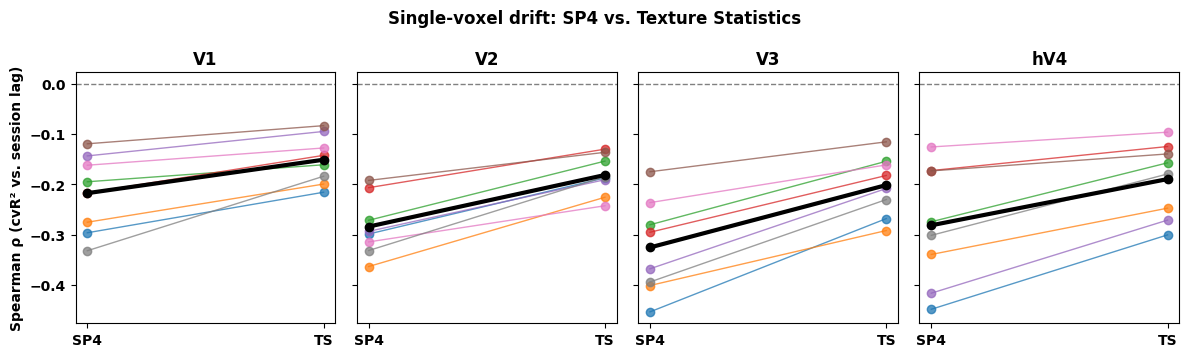

In [ ]:
# ============================================================
# DIRECT SINGLE-VOXEL DRIFT COMPARISON:
# SP4 vs TS pcaHL95
#
# Drift metric:
#   Spearman correlation between cross-session cvR²
#   and absolute session lag
#
# One value per subject × ROI
# ============================================================

from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# ============================================================
# SETTINGS
# ============================================================

SUBJECTS = list(range(1, 9))
ROIS = ["V1", "V2", "V3", "hV4"]

# TS summaries created by TS_Plots notebook
TS_SUMMARY_DIR = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/drift_summaries"
)

# SP summaries created by SP drift notebook
SP_SUMMARY_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/plots/drift_summaries"
)

# We want the cvR²-based drift comparison
TS_METRIC = "cvR2"
TS_CORR_METHOD = "spearman"


# ============================================================
# LOAD TS SUBJECT-LEVEL DRIFT
# ============================================================

ts_rows = []

for roi in ROIS:

    fn = (
        TS_SUMMARY_DIR
        / f"TS_pcaHL95_{roi}_{TS_METRIC}_{TS_CORR_METHOD}.pkl"
    )

    if not fn.exists():
        raise FileNotFoundError(
            f"Missing TS summary:\n{fn}"
        )

    with open(fn, "rb") as f:
        ts = pickle.load(f)

    subject_corr = np.asarray(
        ts["subject_corr"],
        dtype=float
    )

    subjects_saved = list(
        ts.get("subjects", SUBJECTS)
    )

    if len(subject_corr) != 8:
        raise ValueError(
            f"{roi}: expected 8 TS subject correlations, "
            f"got {len(subject_corr)}"
        )

    print(
        f"TS {roi}:",
        np.round(subject_corr, 4)
    )

    for subject, rho in zip(
        subjects_saved,
        subject_corr
    ):
        ts_rows.append({
            "subject": int(subject),
            "roi": roi,
            "TS_rho": rho
        })


ts_df = pd.DataFrame(ts_rows)


# ============================================================
# LOAD SP4 SUBJECT-LEVEL DRIFT
# ============================================================

sp_rows = []

for roi in ROIS:

    fn = (
        SP_SUMMARY_DIR
        / f"{roi}_cvR2_spearman_corr_and_slope.pkl"
    )

    if not fn.exists():
        raise FileNotFoundError(
            f"Missing SP summary:\n{fn}"
        )

    with open(fn, "rb") as f:
        sp = pickle.load(f)

    # This is the exact subject-level Spearman drift metric
    sp_corr = np.asarray(
        sp["subject_corr_metric"],
        dtype=float
    ).squeeze()

    if len(sp_corr) != 8:
        raise ValueError(
            f"{roi}: expected 8 SP subject correlations, "
            f"got {len(sp_corr)}"
        )

    print(
        f"SP {roi}:",
        np.round(sp_corr, 4)
    )

    for subject, rho in zip(
        SUBJECTS,
        sp_corr
    ):
        sp_rows.append({
            "subject": subject,
            "roi": roi,
            "SP4_rho": rho
        })

sp_df = pd.DataFrame(sp_rows)


# ============================================================
# MERGE SP + TS
# ============================================================

drift_compare_df = pd.merge(
    sp_df,
    ts_df,
    on=["subject", "roi"],
    how="inner",
    validate="one_to_one"
)

drift_compare_df[
    "delta_rho_TS_minus_SP4"
] = (
    drift_compare_df["TS_rho"]
    -
    drift_compare_df["SP4_rho"]
)

print("\n" + "=" * 100)
print("SUBJECT-LEVEL SP4 vs TS DRIFT")
print("=" * 100)

display(
    drift_compare_df
)


# ============================================================
# ROI SUMMARY + PAIRED TEST
# ============================================================

summary_rows = []

for roi in ROIS:

    d = (
        drift_compare_df[
            drift_compare_df["roi"] == roi
        ]
        .sort_values("subject")
    )

    sp_rho = d["SP4_rho"].to_numpy()
    ts_rho = d["TS_rho"].to_numpy()
    delta = d[
        "delta_rho_TS_minus_SP4"
    ].to_numpy()

    # Paired subject-level comparison
    W, p = wilcoxon(
        ts_rho,
        sp_rho,
        alternative="two-sided"
    )

    summary_rows.append({

        "roi": roi,

        "SP4_mean_rho":
            np.mean(sp_rho),

        "SP4_sd":
            np.std(sp_rho, ddof=1),

        "TS_mean_rho":
            np.mean(ts_rho),

        "TS_sd":
            np.std(ts_rho, ddof=1),

        "mean_delta_TS_minus_SP4":
            np.mean(delta),

        "sd_delta":
            np.std(delta, ddof=1),

        # TS > SP means TS is less negative
        # i.e. weaker drift estimate
        "subjects_TS_less_negative":
            np.sum(ts_rho > sp_rho),

        "subjects_TS_more_negative":
            np.sum(ts_rho < sp_rho),

        "wilcoxon_W":
            W,

        "p_value":
            p,
    })


drift_model_comparison_summary = pd.DataFrame(
    summary_rows
)

print("\n" + "=" * 100)
print("ROI SUMMARY")
print("=" * 100)

display(
    drift_model_comparison_summary
)


# ============================================================
# PLOT: PAIRED SUBJECT VALUES
# ============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(12, 3.6),
    sharey=True
)

for ax, roi in zip(
    axes,
    ROIS
):

    d = (
        drift_compare_df[
            drift_compare_df["roi"] == roi
        ]
        .sort_values("subject")
    )

    for _, row in d.iterrows():

        ax.plot(
            [0, 1],
            [
                row["SP4_rho"],
                row["TS_rho"]
            ],
            marker="o",
            linewidth=1,
            alpha=0.75
        )

    # Group mean
    ax.plot(
        [0, 1],
        [
            d["SP4_rho"].mean(),
            d["TS_rho"].mean()
        ],
        marker="o",
        linewidth=3,
        color="black"
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
        color="gray"
    )

    ax.set_xticks(
        [0, 1]
    )

    ax.set_xticklabels(
        ["SP4", "TS"]
    )

    ax.set_title(
        roi,
        fontweight="bold"
    )

axes[0].set_ylabel(
    "Spearman ρ (cvR² vs. session lag)",
    fontweight="bold"
)

fig.suptitle(
    "Single-voxel drift: SP4 vs. Texture Statistics",
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MODEL × ROI REPEATED-MEASURES ANALYSIS
# Single-voxel drift: SP4 vs TS
# ============================================================

import numpy as np
import pandas as pd
from statsmodels.stats.anova import AnovaRM
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations


# ============================================================
# 1. Convert to LONG format
# ============================================================

drift_long_df = pd.melt(
    drift_compare_df,
    id_vars=["subject", "roi"],
    value_vars=["SP4_rho", "TS_rho"],
    var_name="model",
    value_name="rho"
)

drift_long_df["model"] = (
    drift_long_df["model"]
    .replace({
        "SP4_rho": "SP4",
        "TS_rho": "TS"
    })
)

# Make ROI order explicit
drift_long_df["roi"] = pd.Categorical(
    drift_long_df["roi"],
    categories=["V1", "V2", "V3", "hV4"],
    ordered=True
)

print("=" * 100)
print("LONG-FORM DATA")
print("=" * 100)

display(
    drift_long_df.sort_values(
        ["subject", "roi", "model"]
    )
)


# ============================================================
# 2. 2 × 4 REPEATED-MEASURES ANOVA
#
# Factors:
#   model = SP4, TS
#   roi   = V1, V2, V3, hV4
# ============================================================

rm_anova = AnovaRM(
    data=drift_long_df,
    depvar="rho",
    subject="subject",
    within=["model", "roi"]
).fit()

print("\n" + "=" * 100)
print("2 × 4 REPEATED-MEASURES ANOVA")
print("=" * 100)

print(rm_anova)


# ============================================================
# 3. MODEL DIFFERENCE PER SUBJECT × ROI
#
# Positive delta:
# TS rho > SP4 rho
# = TS drift is less negative / weaker
# ============================================================

delta_df = (
    drift_compare_df[
        ["subject", "roi", "delta_rho_TS_minus_SP4"]
    ]
    .copy()
)

delta_wide = delta_df.pivot(
    index="subject",
    columns="roi",
    values="delta_rho_TS_minus_SP4"
)

# enforce ROI order
delta_wide = delta_wide[
    ["V1", "V2", "V3", "hV4"]
]

print("\n" + "=" * 100)
print("MODEL DIFFERENCE: TS − SP4")
print("=" * 100)

display(delta_wide)


# ============================================================
# 4. NON-PARAMETRIC TEST OF WHETHER THE MODEL DIFFERENCE
#    CHANGES ACROSS ROIs
#
# This is the non-parametric analogue of asking about
# the model × ROI interaction.
# ============================================================

friedman_stat, friedman_p = friedmanchisquare(
    delta_wide["V1"],
    delta_wide["V2"],
    delta_wide["V3"],
    delta_wide["hV4"]
)

print("\n" + "=" * 100)
print("FRIEDMAN TEST ON Δrho = TS − SP4 ACROSS ROIs")
print("=" * 100)

print(f"Friedman χ² = {friedman_stat:.4f}")
print(f"p = {friedman_p:.6f}")


# ============================================================
# 5. PAIRWISE ROI COMPARISONS OF Δrho
#
# Only especially important if the interaction / Friedman
# test indicates that model difference varies across ROI.
# ============================================================

pairwise_rows = []

roi_pairs = list(
    combinations(
        ["V1", "V2", "V3", "hV4"],
        2
    )
)

for roi1, roi2 in roi_pairs:

    x = delta_wide[roi1].to_numpy()
    y = delta_wide[roi2].to_numpy()

    W, p = wilcoxon(
        x,
        y,
        alternative="two-sided"
    )

    pairwise_rows.append({
        "ROI_1": roi1,
        "ROI_2": roi2,
        f"mean_delta_{roi1}":
            np.mean(x),
        f"mean_delta_{roi2}":
            np.mean(y),
        "mean_difference":
            np.mean(x - y),
        "W":
            W,
        "p_uncorrected":
            p
    })


pairwise_delta_df = pd.DataFrame(
    pairwise_rows
)

# Bonferroni correction for 6 ROI pairs
pairwise_delta_df["p_bonferroni"] = np.minimum(
    pairwise_delta_df["p_uncorrected"] * len(roi_pairs),
    1.0
)

print("\n" + "=" * 100)
print("PAIRWISE COMPARISONS OF MODEL DIFFERENCE ACROSS ROIs")
print("=" * 100)

display(pairwise_delta_df)


# ============================================================
# 6. SIMPLE EFFECT OF MODEL WITHIN EACH ROI
#
# SP4 vs TS paired Wilcoxon
# ============================================================

model_effect_rows = []

for roi in ["V1", "V2", "V3", "hV4"]:

    d = (
        drift_compare_df[
            drift_compare_df["roi"] == roi
        ]
        .sort_values("subject")
    )

    sp = d["SP4_rho"].to_numpy()
    ts = d["TS_rho"].to_numpy()

    W, p = wilcoxon(
        ts,
        sp,
        alternative="two-sided"
    )

    model_effect_rows.append({
        "roi": roi,
        "SP4_mean_rho": np.mean(sp),
        "TS_mean_rho": np.mean(ts),
        "mean_delta_TS_minus_SP4":
            np.mean(ts - sp),
        "W": W,
        "p_uncorrected": p
    })


model_effect_df = pd.DataFrame(
    model_effect_rows
)

# Correction for testing model effect in 4 ROIs
model_effect_df["p_bonferroni"] = np.minimum(
    model_effect_df["p_uncorrected"] * 4,
    1.0
)

print("\n" + "=" * 100)
print("SP4 vs TS WITHIN EACH ROI")
print("=" * 100)

display(model_effect_df)

LONG-FORM DATA


,subject,roi,model,rho
0,1,V1,SP4,-0.295877
32,1,V1,TS,-0.215417
8,1,V2,SP4,-0.298377
40,1,V2,TS,-0.186874
16,1,V3,SP4,-0.452956
...,...,...,...,...
47,8,V2,TS,-0.184798
23,8,V3,SP4,-0.393609
55,8,V3,TS,-0.229953
31,8,hV4,SP4,-0.301013



2 × 4 REPEATED-MEASURES ANOVA
                 Anova
          F Value Num DF  Den DF Pr > F
---------------------------------------
model     59.3757 1.0000  7.0000 0.0001
roi        3.7503 3.0000 21.0000 0.0266
model:roi  7.3840 3.0000 21.0000 0.0015


MODEL DIFFERENCE: TS − SP4


roi,V1,V2,V3,hV4
subject,,,,
1,0.080460,0.111504,0.185176,0.147695
2,0.075739,0.137521,0.109174,0.091928
3,0.033756,0.117497,0.126122,0.116931
4,0.074575,0.076510,0.112722,0.047776
5,0.048534,0.102579,0.159427,0.145068
6,0.036002,0.055820,0.059405,0.033722
7,0.034233,0.071779,0.074838,0.029286
8,0.147863,0.146373,0.163656,0.121831



FRIEDMAN TEST ON Δrho = TS − SP4 ACROSS ROIs
Friedman χ² = 15.7500
p = 0.001276

PAIRWISE COMPARISONS OF MODEL DIFFERENCE ACROSS ROIs


,ROI_1,ROI_2,mean_delta_V1,mean_delta_V2,mean_difference,W,p_uncorrected,mean_delta_V3,mean_delta_hV4,p_bonferroni
0,V1,V2,0.066395,0.102448,-0.036053,1.0,0.015625,NaN,NaN,0.093750
1,V1,V3,0.066395,NaN,-0.057420,0.0,0.007812,0.123815,NaN,0.046875
2,V1,hV4,0.066395,NaN,-0.025384,12.0,0.460938,NaN,0.091779,1.000000
3,V2,V3,NaN,0.102448,-0.021367,5.0,0.078125,0.123815,NaN,0.468750
4,V2,hV4,NaN,0.102448,0.010669,11.0,0.382812,NaN,0.091779,1.000000
5,V3,hV4,NaN,NaN,0.032036,0.0,0.007812,0.123815,0.091779,0.046875



SP4 vs TS WITHIN EACH ROI


,roi,SP4_mean_rho,TS_mean_rho,mean_delta_TS_minus_SP4,W,p_uncorrected,p_bonferroni
0,V1,-0.217253,-0.150858,0.066395,0.0,0.007812,0.03125
1,V2,-0.283636,-0.181188,0.102448,0.0,0.007812,0.03125
2,V3,-0.325035,-0.201220,0.123815,0.0,0.007812,0.03125
3,hV4,-0.281071,-0.189291,0.091779,0.0,0.007812,0.03125


# TS Drift between ROIS

SP V1: [-0.29587661 -0.27493288 -0.19463125 -0.21675724 -0.14326655 -0.11922929
 -0.1617761  -0.33155218]
SP V2: [-0.29837722 -0.36292782 -0.27112217 -0.2063718  -0.2930973  -0.19195025
 -0.3140677  -0.33117164]
SP V3: [-0.45295591 -0.40063283 -0.28002365 -0.29486559 -0.36742776 -0.17476555
 -0.23600219 -0.39360887]
SP hV4: [-0.44778821 -0.338968   -0.27396758 -0.17243345 -0.41581747 -0.17308499
 -0.12549356 -0.30101265]
TS V1: [-0.21541695 -0.1991942  -0.16087511 -0.14218196 -0.09473276 -0.08322768
 -0.12754331 -0.18368925]
TS V2: [-0.18687355 -0.22540724 -0.15362503 -0.12986136 -0.19051831 -0.13613014
 -0.24228843 -0.18479822]
TS V3: [-0.26777991 -0.29145844 -0.15390134 -0.1821432  -0.20800085 -0.11536018
 -0.16116369 -0.22995312]
TS hV4: [-0.30009316 -0.24704009 -0.15703691 -0.12465738 -0.27074995 -0.1393634
 -0.09620762 -0.17918192]

Subject counts:
V1: SP=8, TS=8
V2: SP=8, TS=8
V3: SP=8, TS=8
hV4: SP=8, TS=8

ROI DRIFT — SP


,ROI,mean,sem,p_raw,p_fdr,stars
0,V1,-0.217253,0.027139,0.004,0.004,**
1,V2,-0.283636,0.020836,0.004,0.004,**
2,V3,-0.325035,0.033280,0.004,0.004,**
3,hV4,-0.281071,0.041709,0.004,0.004,**



ROI DRIFT — TS


,ROI,mean,sem,p_raw,p_fdr,stars
0,V1,-0.150858,0.016916,0.004,0.004,**
1,V2,-0.181188,0.014171,0.004,0.004,**
2,V3,-0.201220,0.021139,0.004,0.004,**
3,hV4,-0.189291,0.026297,0.004,0.004,**



ROI DIFFERENCES — SP


...

,ROI_A,ROI_B,W,p_raw,n,p_fdr,stars
0,V1,V2,10.0,0.312500,8,0.574219,
1,V1,V3,1.0,0.015625,8,0.093750,
2,V1,hV4,10.0,0.312500,8,0.574219,
3,V2,V3,11.0,0.382812,8,0.574219,
4,V2,hV4,15.0,0.742188,8,0.742188,
5,V3,hV4,13.0,0.546875,8,0.656250,



Significant SP ROI differences:


,ROI_A,ROI_B,W,p_raw,n,p_fdr,stars
1,V1,V3,0.0,0.007812,8,0.046875,*



Significant TS ROI differences:


,ROI_A,ROI_B,W,p_raw,n,p_fdr,stars


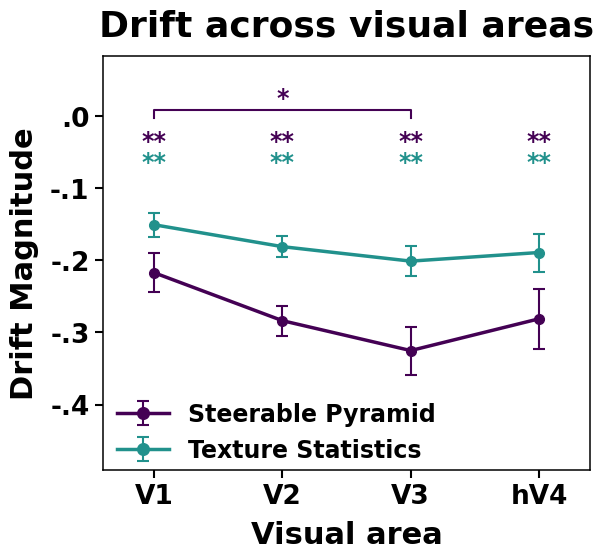


Saved: /content/drive/MyDrive/V1_Drift/plots/Gonda_Conf_figures/SP_vs_TS_pcaHL95_drift_across_visual_areas_spearman_stats.png


In [2]:
# ============================================================
# SP vs TS pcaHL95
# Spearman drift across visual areas
#
# Statistics reproduce the original ROI analysis:
#
# 1. ROI drift:
#    one-sided sign-flip permutation test, H1: drift < 0
#    FDR-BH across 4 ROIs
#
# 2. ROI differences:
#    paired Wilcoxon signed-rank tests
#    FDR-BH across 6 ROI pairs
#
# Statistics are performed separately for SP and TS.
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from matplotlib.ticker import FuncFormatter

# ============================================================
# SETTINGS
# ============================================================

ROIS = ["V1", "V2", "V3", "hV4"]

METRIC = "cvR2"
CORR_METHOD = "spearman"

N_PERM = 1000
SEED = 1


# ------------------------------------------------------------
# SP
# ------------------------------------------------------------

SP_SUMMARY_DIR = (
    "/content/drive/MyDrive/V1_Drift/plots/drift_summaries"
)


# ------------------------------------------------------------
# TS pcaHL95
# ------------------------------------------------------------

TS_SUMMARY_DIR = (
    "/content/drive/MyDrive/V2_drift/"
    "texturemodel/drift_results/drift_summaries"
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/V1_Drift/"
    "plots/Gonda_Conf_figures"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ============================================================
# HELPERS
# ============================================================

def p_to_stars(p):

    if not np.isfinite(p):
        return ""

    if p < 0.001:
        return "***"

    elif p < 0.01:
        return "**"

    elif p < 0.05:
        return "*"

    return ""


# ------------------------------------------------------------
# SAME sign-flip test as original code
# ------------------------------------------------------------

def signflip_p_negative(
    x,
    n_perm=10000,
    seed=1
):

    """
    One-sided sign-flip permutation test.

    H1: mean(x) < 0
    """

    x = np.asarray(
        x,
        dtype=float
    )

    x = x[
        np.isfinite(x)
    ]


    if len(x) < 3:
        return np.nan


    rng = np.random.default_rng(
        seed
    )


    real_mean = np.mean(
        x
    )


    perm_means = np.zeros(
        n_perm
    )


    for i in range(n_perm):

        signs = rng.choice(
            [-1, 1],
            size=len(x)
        )

        perm_means[i] = np.mean(
            x * signs
        )


    return float(
        np.mean(
            perm_means <= real_mean
        )
    )


def mean_sem(x):

    x = np.asarray(
        x,
        dtype=float
    )

    x = x[
        np.isfinite(x)
    ]


    mean = np.mean(
        x
    )


    sem = stats.sem(
        x
    )


    return mean, sem



def no_leading_zero(x, pos):

    s = f"{x:.1f}"

    if s.startswith("-0."):
        s = "-." + s[3:]

    elif s.startswith("0."):
        s = "." + s[2:]

    elif s == "-0.0":
        s = ".0"

    return s
# ============================================================
# LOAD SP
# ============================================================

sp_subject = {}


for roi in ROIS:

    fn = os.path.join(

        SP_SUMMARY_DIR,

        f"{roi}_{METRIC}_"
        f"{CORR_METHOD}_corr_and_slope.pkl"
    )


    if not os.path.exists(fn):

        raise FileNotFoundError(
            f"Missing SP summary:\n{fn}"
        )


    with open(fn, "rb") as f:
        d = pickle.load(f)


    sp_subject[roi] = np.asarray(

        d["subject_corr_metric"],

        dtype=float
    )


    print(
        f"SP {roi}:",
        sp_subject[roi]
    )


# ============================================================
# LOAD TS
# ============================================================

ts_subject = {}


for roi in ROIS:

    fn = os.path.join(

        TS_SUMMARY_DIR,

        f"TS_pcaHL95_{roi}_"
        f"{METRIC}_{CORR_METHOD}.pkl"
    )


    if not os.path.exists(fn):

        raise FileNotFoundError(
            f"Missing TS summary:\n{fn}"
        )


    with open(fn, "rb") as f:
        d = pickle.load(f)


    ts_subject[roi] = np.asarray(

        d["subject_corr"],

        dtype=float
    )


    print(
        f"TS {roi}:",
        ts_subject[roi]
    )


# ============================================================
# CHECK SUBJECT COUNTS
# ============================================================

print("\nSubject counts:")


for roi in ROIS:

    print(

        f"{roi}: "

        f"SP={len(sp_subject[roi])}, "

        f"TS={len(ts_subject[roi])}"
    )


# ============================================================
# MEAN ± SEM
# ============================================================

sp_mean = []
sp_sem = []

ts_mean = []
ts_sem = []


for roi in ROIS:

    m, se = mean_sem(
        sp_subject[roi]
    )

    sp_mean.append(m)
    sp_sem.append(se)


    m, se = mean_sem(
        ts_subject[roi]
    )

    ts_mean.append(m)
    ts_sem.append(se)


sp_mean = np.asarray(
    sp_mean
)

sp_sem = np.asarray(
    sp_sem
)

ts_mean = np.asarray(
    ts_mean
)

ts_sem = np.asarray(
    ts_sem
)


# ============================================================
# ROI DRIFT SIGNIFICANCE
#
# Same as original:
# one-sided sign-flip test, H1 mean drift < 0
# FDR-BH across the four ROIs
# ============================================================

def roi_drift_tests(
    subject_dict
):

    rows = []


    for roi in ROIS:

        vals = np.asarray(
            subject_dict[roi],
            dtype=float
        )

        vals = vals[
            np.isfinite(vals)
        ]


        p = signflip_p_negative(

            vals,

            n_perm=N_PERM,

            seed=SEED
        )


        rows.append({

            "ROI": roi,

            "mean": np.mean(vals),

            "sem": stats.sem(vals),

            "p_raw": p
        })


    df = pd.DataFrame(
        rows
    )


    # FDR-BH across 4 ROI tests
    df["p_fdr"] = multipletests(

        df["p_raw"].values,

        alpha=0.05,

        method="fdr_bh"

    )[1]


    df["stars"] = (
        df["p_fdr"]
        .apply(p_to_stars)
    )


    return df


sp_roi_sig = roi_drift_tests(
    sp_subject
)

ts_roi_sig = roi_drift_tests(
    ts_subject
)


# ============================================================
# ROI DIFFERENCES
#
# Same as original:
# paired Wilcoxon for all 6 ROI pairs
# FDR-BH across the six tests
# ============================================================

def roi_pairwise_tests(
    subject_dict
):

    rows = []


    for roi_a, roi_b in combinations(
        ROIS,
        2
    ):

        x = np.asarray(
            subject_dict[roi_a],
            dtype=float
        )

        y = np.asarray(
            subject_dict[roi_b],
            dtype=float
        )


        valid = (
            np.isfinite(x)
            &
            np.isfinite(y)
        )


        x = x[valid]
        y = y[valid]


        try:

            w_stat, p = stats.wilcoxon(
                x,
                y
            )

        except ValueError:

            w_stat = np.nan
            p = np.nan


        rows.append({

            "ROI_A": roi_a,

            "ROI_B": roi_b,

            "W": w_stat,

            "p_raw": p,

            "n": len(x)
        })


    df = pd.DataFrame(
        rows
    )


    # FDR-BH across the six ROI comparisons
    df["p_fdr"] = multipletests(

        df["p_raw"].values,

        alpha=0.05,

        method="fdr_bh"

    )[1]


    df["stars"] = (
        df["p_fdr"]
        .apply(p_to_stars)
    )


    return df


sp_pairwise = roi_pairwise_tests(
    sp_subject
)

ts_pairwise = roi_pairwise_tests(
    ts_subject
)


# ============================================================
# PRINT RESULTS
# ============================================================

print(
    "\n"
    + "=" * 70
)

print(
    "ROI DRIFT — SP"
)

print(
    "=" * 70
)

display(
    sp_roi_sig
)


print(
    "\n"
    + "=" * 70
)

print(
    "ROI DRIFT — TS"
)

print(
    "=" * 70
)

display(
    ts_roi_sig
)


print(
    "\n"
    + "=" * 70
)

print(
    "ROI DIFFERENCES — SP"
)

print(
    "=" * 70
)

display(
    sp_pairwise
)


print(
    "\n"
    + "=" * 70
)

print(
    "ROI DIFFERENCES — TS"
)

print(
    "=" * 70
)

display(
    ts_pairwise
)


# ============================================================
# SIGNIFICANT PAIRS ONLY
# ============================================================

sp_sig_pairs = sp_pairwise[
    sp_pairwise["p_fdr"] < 0.05
].copy()


ts_sig_pairs = ts_pairwise[
    ts_pairwise["p_fdr"] < 0.05
].copy()


print("\nSignificant SP ROI differences:")

display(
    sp_sig_pairs
)


print("\nSignificant TS ROI differences:")

display(
    ts_sig_pairs
)


# ============================================================
# PLOT
# ============================================================

xpos = np.arange(
    len(ROIS)
)

roi_x = {
    roi: i
    for i, roi in enumerate(ROIS)
}


fig, ax = plt.subplots(
    figsize=(6.5, 6.0)
)

# Exact same plotting-box position in both figures
ax.set_position([
    0.21,   # left
    0.15,   # bottom
    0.75,   # width
    0.75    # height
])


# ============================================================
# POSTER COLORS
# ============================================================

SP_COLOR = "#440154"   # purple
TS_COLOR = "#21918c"   # teal

# ============================================================
# SP LINE
# ============================================================

sp_plot = ax.errorbar(

    xpos,

    sp_mean,

    yerr=sp_sem,

    marker="o",

    markersize=7,

    linewidth=2.5,

    capsize=4,

    capthick=1.5,

    elinewidth=1.5,

    color=SP_COLOR,

    label="Steerable Pyramid",

    zorder=4
)


# ============================================================
# TS LINE
# ============================================================

ts_plot = ax.errorbar(

    xpos,

    ts_mean,

    yerr=ts_sem,

    marker="o",

    markersize=7,

    linewidth=2.5,

    capsize=4,

    capthick=1.5,

    elinewidth=1.5,

    color=TS_COLOR,

    label="Texture Statistics",

    zorder=4
)


# Get automatically assigned colors
sp_color = (
    sp_plot.lines[0].get_color()
)

ts_color = (
    ts_plot.lines[0].get_color()
)


# ============================================================
# DETERMINE Y RANGE
# ============================================================

all_values = np.concatenate([

    np.concatenate(
        [
            sp_subject[roi]
            for roi in ROIS
        ]
    ),

    np.concatenate(
        [
            ts_subject[roi]
            for roi in ROIS
        ]
    )
])


ymin = np.nanmin(
    all_values
)

ymax = np.nanmax(
    all_values
)


yrange = (
    ymax - ymin
)


if yrange == 0:

    yrange = (
        abs(ymax)
        if ymax != 0
        else 1
    )


# ============================================================
# ANNOTATION SPACE
# ============================================================

n_sp_pairs = len(
    sp_sig_pairs
)

n_ts_pairs = len(
    ts_sig_pairs
)

n_total_pairs = (
    n_sp_pairs
    +
    n_ts_pairs
)


extra_top = (
    0.45 * yrange
    +
    max(
        n_total_pairs - 1,
        0
    )
    * 0.10
    * yrange
)


extra_bottom = (
    0.10 * yrange
)


ax.set_ylim(

    ymin - extra_bottom,

    ymax + extra_top
)


ylim = ax.get_ylim()

yrange_plot = (
    ylim[1]
    -
    ylim[0]
)


# ============================================================
# ROI DRIFT STARS
#
# Separate vertical rows:
#   SP = upper row
#   TS = lower row
# ============================================================

sp_star_y = (
    ymax
    + 0.055 * yrange_plot
)

ts_star_y = (
    ymax
    + 0.005 * yrange_plot
)


for i, roi in enumerate(ROIS):

    # --------------------------------------------------------
    # SP
    # --------------------------------------------------------

    stars = sp_roi_sig.loc[
        sp_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            sp_star_y,
            stars,
            ha="center",
            va="bottom",
            fontsize=17,
            fontweight="bold",
            color=sp_color
        )


    # --------------------------------------------------------
    # TS
    # --------------------------------------------------------

    stars = ts_roi_sig.loc[
        ts_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            ts_star_y,
            stars,
            ha="center",
            va="bottom",
            fontsize=17,
            fontweight="bold",
            color=ts_color
        )

# ============================================================
# BRACKET FUNCTION
# ============================================================

def draw_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    stars,
    color
):

    ax.plot(

        [
            x1,
            x1,
            x2,
            x2
        ],

        [
            y,
            y + h,
            y + h,
            y
        ],

        color=color,

        linewidth=1.5,

        clip_on=False
    )


    ax.text(

        (x1 + x2) / 2,

        y + h,

        stars,

        ha="center",

        va="bottom",

        fontsize=17,

        fontweight="bold",

        color=color
    )


# ============================================================
# ROI DIFFERENCE BRACKETS
# ============================================================

bracket_base = (
    ymax
    +
    0.14
    * yrange_plot
)

bracket_step = (
    0.09
    * yrange_plot
)

bracket_h = (
    0.018
    * yrange_plot
)


bracket_number = 0


# ------------------------------------------------------------
# SP brackets
# ------------------------------------------------------------

for _, row in sp_sig_pairs.iterrows():

    x1 = roi_x[row["ROI_A"]]

    x2 = roi_x[row["ROI_B"]]



    y = (
        bracket_base
        +
        bracket_number
        * bracket_step
    )


    draw_bracket(

        ax,

        x1,

        x2,

        y,

        bracket_h,

        row["stars"],

        sp_color
    )


    bracket_number += 1


# ------------------------------------------------------------
# TS brackets
# ------------------------------------------------------------

for _, row in ts_sig_pairs.iterrows():

    x1 = roi_x[row["ROI_A"]]

    x2 = roi_x[row["ROI_B"]]

    y = (
        bracket_base
        +
        bracket_number
        * bracket_step
    )


    draw_bracket(

        ax,

        x1,

        x2,

        y,

        bracket_h,

        row["stars"],

        ts_color
    )


    bracket_number += 1


# ============================================================
# AXES
# ============================================================

ax.set_xticks(xpos)

ax.set_xticklabels(
    ROIS,
    fontsize=20,
    fontweight="bold"
)

ax.set_xlim(
    -0.4,
    len(ROIS) - 0.6
)

ax.set_xlabel(
    "Visual area",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_ylabel(
    "Drift Magnitude",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_title(
    "Drift across visual areas",
    fontsize=26,
    fontweight="bold",
    pad=14
)

ax.yaxis.set_major_formatter(
    FuncFormatter(no_leading_zero)
)


# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="both",
    labelsize=19,
    width=1.5,
    length=6
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")


# ============================================================
# MODEL LEGEND
# ============================================================

legend = ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.01, -0.005),
    frameon=False,
    fontsize=17,
    borderaxespad=0,
    handlelength=2.2,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ============================================================
# SPINES
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        1.1
    )


# ============================================================
# LAYOUT
# ============================================================

fig.subplots_adjust(

    top=0.84,

    bottom=0.15,

    left=0.21,

    right=0.96
)


# ============================================================
# SAVE
# ============================================================

fig_path = os.path.join(

    OUT_DIR,

    "SP_vs_TS_pcaHL95_"
    "drift_across_visual_areas_"
    "spearman_stats.png"
)


fig.savefig(

    fig_path,

    dpi=300,

    pad_inches=0.20
)


plt.show()


print(
    "\nSaved:",
    fig_path
)

V1  | shape=(8, 29) | mean lag1=-0.177636 | mean lag29=-0.220139
V2  | shape=(8, 29) | mean lag1=-0.204833 | mean lag29=-0.265961
V3  | shape=(8, 29) | mean lag1=-0.219651 | mean lag29=-0.295131
hV4 | shape=(8, 29) | mean lag1=-0.224892 | mean lag29=-0.286045


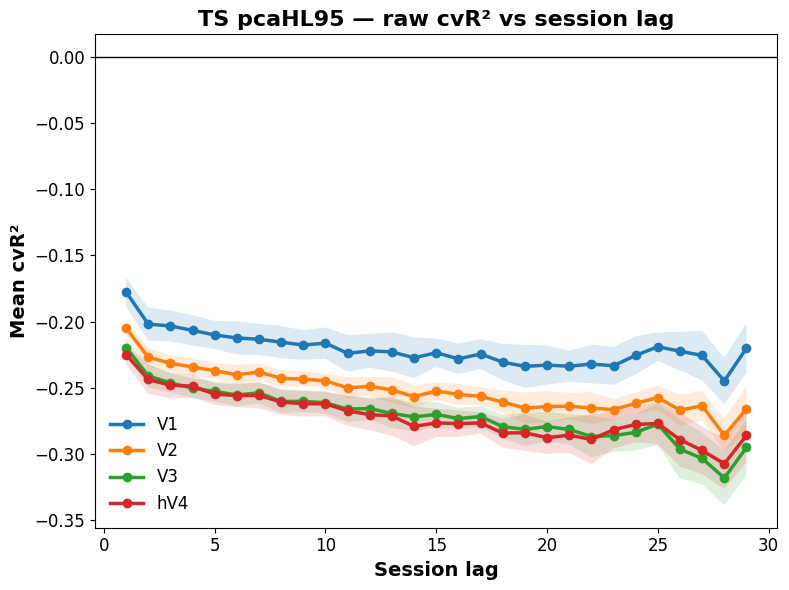

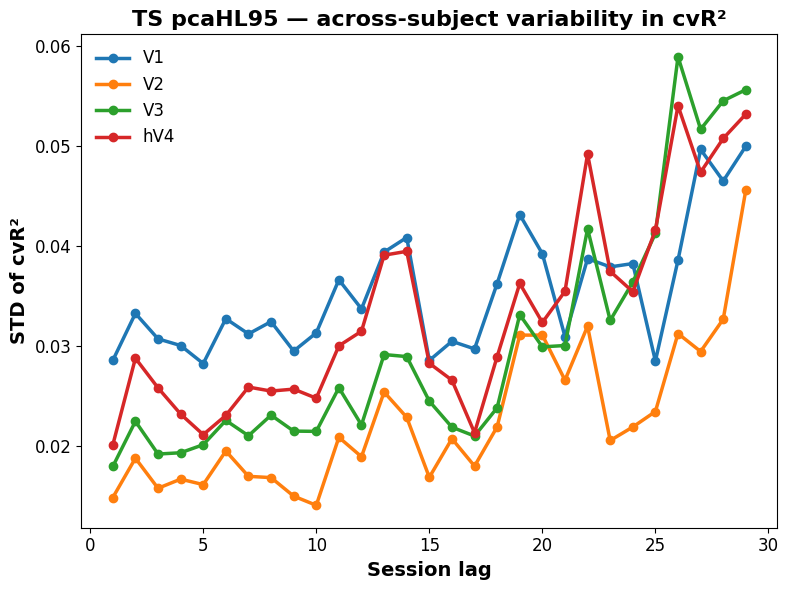

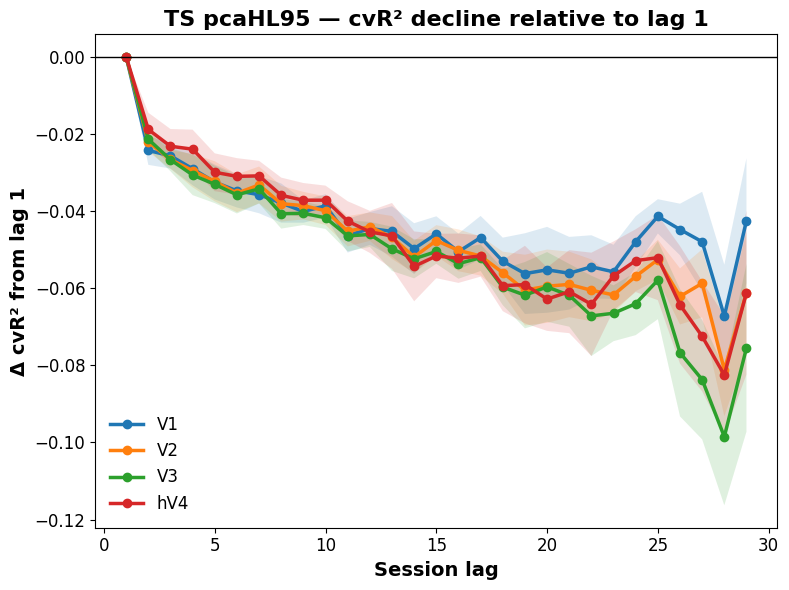

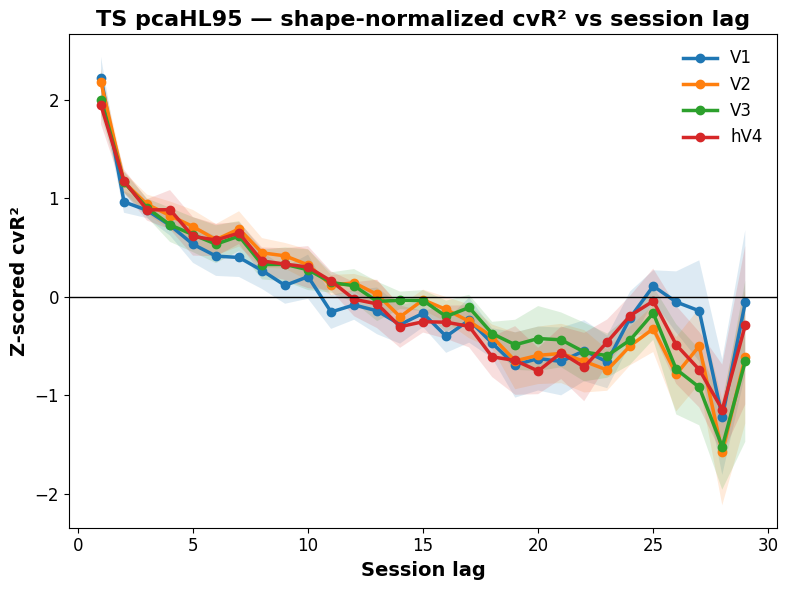


Subject-level curve summary:


,subject,ROI,lag1,last_lag,absolute_decline_last_minus_lag1,mean_curve,std_curve,corr_lag_curve,slope_lag_curve
0,S01,V1,-0.140789,-0.182403,-0.041614,-0.179660,0.017345,-0.817241,-0.001680
1,S02,V1,-0.155179,-0.227575,-0.072396,-0.200038,0.016188,-0.890640,-0.001678
2,S03,V1,-0.162581,-0.205523,-0.042941,-0.225195,0.024789,-0.253202,-0.000899
3,S04,V1,-0.170424,-0.223379,-0.052955,-0.204593,0.027356,-0.702463,-0.002027
4,S05,V1,-0.189632,-0.132681,0.056951,-0.218300,0.021598,0.020690,0.000543
5,S06,V1,-0.174269,-0.269595,-0.095327,-0.218740,0.016870,-0.101970,-0.000563
6,S07,V1,-0.186025,-0.209842,-0.023817,-0.222735,0.013969,-0.343350,-0.000670
7,S08,V1,-0.242185,-0.310110,-0.067925,-0.296845,0.022802,-0.825123,-0.002190
8,S01,V2,-0.196474,-0.255560,-0.059086,-0.234232,0.017540,-0.899015,-0.001856
9,S02,V2,-0.205407,-0.266199,-0.060791,-0.248413,0.017225,-0.941872,-0.001889



ROI-level curve summary:


lag1            last_lag           absolute_decline_last_minus_lag1  \
         mean       sem      mean       sem                             mean   
ROI                                                                            
V1  -0.177636  0.010801 -0.220139  0.018898                        -0.042503   
V2  -0.204833  0.005616 -0.265961  0.017244                        -0.061128   
V3  -0.219651  0.006791 -0.295131  0.021034                        -0.075480   
hV4 -0.224892  0.007607 -0.286045  0.020109                        -0.061153   

              mean_curve           std_curve           corr_lag_curve  \
          sem       mean       sem      mean       sem           mean   
ROI                                                                     
V1   0.016191  -0.220763  0.012103  0.020115  0.001664      -0.489163   
V2   0.015677  -0.251845  0.006699  0.022009  0.001350      -0.673214   
V3   0.021748  -0.270995  0.009365  0.027338  0.003263      -0.639840   
hV4  0.021237  -0.271828  0.010714  0.025319  0.003056      -0.589532   

              slope_lag_curve            
          sem            mean       sem  
ROI                                      
V1   0.127755       -0.001145  0.000325  
V2   0.105841       -0.001712  0.000209  
V3   0.123648       -0.002228  0.000485  
hV4  0.099228       -0.001935  0.000429

In [3]:
# ============================================================
# TS pcaHL95 — inspect actual cvR²-vs-lag curves across ROIs
# Same diagnostic plots as SP
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy import stats


# ============================================================
# SETTINGS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel"
)

SUMMARY_DIR = (
    ROOT
    / "drift_results"
    / "drift_summaries"
)

FIG_DIR = (
    ROOT
    / "drift_results"
    / "single_voxel_figures"
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)


PCA_TYPE = "pcaHL"
PCA_PCT = 95

ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4"
]

CORR_METHOD = "spearman"

SAVE_FIG = True

metric_name = "cvR²"


# ============================================================
# LOAD SUBJECT-LEVEL LAG CURVES
# ============================================================

curves_by_roi = {}

valid_voxel_counts = {}


for roi in ROIS:

    fn = (
        SUMMARY_DIR
        / (
            f"TS_{PCA_TYPE}{PCA_PCT}_"
            f"{roi}_cvR2_"
            f"{CORR_METHOD}.pkl"
        )
    )

    if not fn.exists():

        raise FileNotFoundError(
            f"Missing summary:\n{fn}"
        )


    with open(fn, "rb") as f:

        d = pickle.load(f)


    curves = np.asarray(
        d["curve_sub"],
        dtype=float
    )


    curves_by_roi[roi] = curves


    valid_voxel_counts[roi] = (
        d.get(
            "valid_voxel_counts",
            None
        )
    )


    print(
        f"{roi:3s} | "
        f"shape={curves.shape} | "
        f"mean lag1={np.nanmean(curves[:, 0]):.6f} | "
        f"mean lag29={np.nanmean(curves[:, -1]):.6f}"
    )


# ============================================================
# PLOT 1 — RAW cvR² LAG CURVES
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for roi in ROIS:

    curves = curves_by_roi[roi]

    lags = np.arange(
        1,
        curves.shape[1] + 1
    )


    mean_curve = np.nanmean(
        curves,
        axis=0
    )

    sem_curve = stats.sem(
        curves,
        axis=0,
        nan_policy="omit"
    )


    ax.plot(
        lags,
        mean_curve,
        marker="o",
        linewidth=2.5,
        label=roi
    )


    ax.fill_between(
        lags,
        mean_curve - sem_curve,
        mean_curve + sem_curve,
        alpha=0.15
    )


ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Session lag",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Mean cvR²",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "TS pcaHL95 — raw cvR² vs session lag",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()


if SAVE_FIG:

    fig.savefig(
        FIG_DIR
        / "TS_pcaHL95_raw_cvR2_vs_session_lag.png",
        dpi=300,
        bbox_inches="tight"
    )


plt.show()


# ============================================================
# PLOT 2 — STD ACROSS SUBJECTS
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for roi in ROIS:

    curves = curves_by_roi[roi]

    lags = np.arange(
        1,
        curves.shape[1] + 1
    )


    std_curve = np.nanstd(
        curves,
        axis=0
    )


    ax.plot(
        lags,
        std_curve,
        marker="o",
        linewidth=2.5,
        label=roi
    )


ax.set_xlabel(
    "Session lag",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "STD of cvR²",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "TS pcaHL95 — across-subject variability in cvR²",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()


if SAVE_FIG:

    fig.savefig(
        FIG_DIR
        / "TS_pcaHL95_std_cvR2_vs_session_lag.png",
        dpi=300,
        bbox_inches="tight"
    )


plt.show()


# ============================================================
# PLOT 3 — Δ cvR² RELATIVE TO LAG 1
# ============================================================
#
# This is the TS equivalent of the figure you just showed.
#
# For every subject separately:
#
#     Δ(lag) = cvR²(lag) - cvR²(lag=1)
#
# Then mean ± SEM across subjects.
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for roi in ROIS:

    curves = curves_by_roi[roi]

    lags = np.arange(
        1,
        curves.shape[1] + 1
    )


    # ----------------------------------------
    # subtract EACH SUBJECT'S own lag-1 value
    # ----------------------------------------

    curves_delta = (
        curves
        -
        curves[:, [0]]
    )


    mean_curve = np.nanmean(
        curves_delta,
        axis=0
    )

    sem_curve = stats.sem(
        curves_delta,
        axis=0,
        nan_policy="omit"
    )


    ax.plot(
        lags,
        mean_curve,
        marker="o",
        linewidth=2.5,
        label=roi
    )


    ax.fill_between(
        lags,
        mean_curve - sem_curve,
        mean_curve + sem_curve,
        alpha=0.15
    )


ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Session lag",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Δ cvR² from lag 1",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "TS pcaHL95 — cvR² decline relative to lag 1",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()


if SAVE_FIG:

    fig.savefig(
        FIG_DIR
        / "TS_pcaHL95_delta_cvR2_relative_to_lag1.png",
        dpi=300,
        bbox_inches="tight"
    )


plt.show()


# ============================================================
# PLOT 4 — Z-SCORE EACH SUBJECT CURVE ACROSS LAGS
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for roi in ROIS:

    curves = curves_by_roi[roi]

    lags = np.arange(
        1,
        curves.shape[1] + 1
    )


    curves_z = np.full_like(
        curves,
        np.nan
    )


    for si in range(
        curves.shape[0]
    ):

        y = curves[si]

        m = np.nanmean(y)

        s = np.nanstd(y)


        if (
            np.isfinite(s)
            and
            s > 0
        ):

            curves_z[si] = (
                y - m
            ) / s


    mean_curve = np.nanmean(
        curves_z,
        axis=0
    )

    sem_curve = stats.sem(
        curves_z,
        axis=0,
        nan_policy="omit"
    )


    ax.plot(
        lags,
        mean_curve,
        marker="o",
        linewidth=2.5,
        label=roi
    )


    ax.fill_between(
        lags,
        mean_curve - sem_curve,
        mean_curve + sem_curve,
        alpha=0.15
    )


ax.axhline(
    0,
    color="black",
    linewidth=1
)

ax.set_xlabel(
    "Session lag",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel(
    "Z-scored cvR²",
    fontsize=14,
    fontweight="bold"
)

ax.set_title(
    "TS pcaHL95 — shape-normalized cvR² vs session lag",
    fontsize=16,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()


if SAVE_FIG:

    fig.savefig(
        FIG_DIR
        / "TS_pcaHL95_shape_normalized_cvR2_vs_session_lag.png",
        dpi=300,
        bbox_inches="tight"
    )


plt.show()


# ============================================================
# SUBJECT-LEVEL SUMMARY TABLE
# ============================================================

summary_rows = []


for roi in ROIS:

    curves = curves_by_roi[roi]

    lags = np.arange(
        1,
        curves.shape[1] + 1
    )


    for si in range(
        curves.shape[0]
    ):

        y = curves[si]

        valid = (
            np.isfinite(lags)
            &
            np.isfinite(y)
        )


        if valid.sum() >= 3:

            corr_val, corr_p = stats.spearmanr(
                lags[valid],
                y[valid]
            )


            slope_val, _, _, _, _ = (
                stats.linregress(
                    lags[valid],
                    y[valid]
                )
            )

        else:

            corr_val = np.nan
            slope_val = np.nan


        summary_rows.append(
            {
                "subject": f"S{si+1:02d}",
                "ROI": roi,

                "lag1": y[0],

                "last_lag": y[-1],

                "absolute_decline_last_minus_lag1":
                    y[-1] - y[0],

                "mean_curve":
                    np.nanmean(y),

                "std_curve":
                    np.nanstd(y),

                "corr_lag_curve":
                    corr_val,

                "slope_lag_curve":
                    slope_val,
            }
        )


curve_summary_df = pd.DataFrame(
    summary_rows
)


print(
    "\nSubject-level curve summary:"
)

display(
    curve_summary_df
)


print(
    "\nROI-level curve summary:"
)


roi_curve_summary = (
    curve_summary_df
    .groupby("ROI")
    .agg(
        {
            "lag1":
                ["mean", "sem"],

            "last_lag":
                ["mean", "sem"],

            "absolute_decline_last_minus_lag1":
                ["mean", "sem"],

            "mean_curve":
                ["mean", "sem"],

            "std_curve":
                ["mean", "sem"],

            "corr_lag_curve":
                ["mean", "sem"],

            "slope_lag_curve":
                ["mean", "sem"],
        }
    )
)


display(
    roi_curve_summary
)

# relative to lag 1


LOADING STEERABLE PYRAMID
SP file:
/content/drive/MyDrive/V1_Drift/repDrift_expand/perm_roi1_2_3_41000.pkl
Subjects: [1, 2, 3, 4, 5, 6, 7, 8]
Common sessions: 30
SP V1: (8, 29)
SP V2: (8, 29)
SP V3: (8, 29)
SP hV4: (8, 29)

LOADING TEXTURE STATISTICS
TS V1: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/drift_summaries/TS_pcaHL95_V1_cvR2_spearman.pkl
   shape = (8, 29)
TS V2: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/drift_summaries/TS_pcaHL95_V2_cvR2_spearman.pkl
   shape = (8, 29)
TS V3: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/drift_summaries/TS_pcaHL95_V3_cvR2_spearman.pkl
   shape = (8, 29)
TS hV4: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/drift_summaries/TS_pcaHL95_hV4_cvR2_spearman.pkl
   shape = (8, 29)

CHECK
V1  | SP lag1=0.000000 | TS lag1=0.000000
V2  | SP lag1=0.000000 | TS lag1=0.000000
V3  | SP lag1=0.000000 | TS lag1=0.000000
hV4 | SP lag1=0.000000 | TS lag1=0.000000


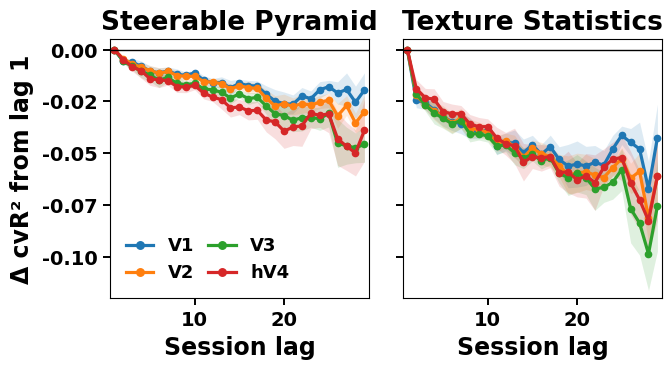

In [22]:
# ============================================================
# STANDALONE POSTER FIGURE
# SP vs TS — Δ cvR² relative to lag 1
#
# Loads saved results directly.
# NO previous analysis cells required.
# ============================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from matplotlib.ticker import FormatStrFormatter

# ============================================================
# SETTINGS
# ============================================================

ROIS = ["V1", "V2", "V3", "hV4"]


# ------------------------------------------------------------
# SP SETTINGS
# ------------------------------------------------------------

# IMPORTANT:
# This must be the folder containing:
# perm_roi1_2_3_4_1000.pkl
#
# Change ONLY this path if necessary.

SP_SAVE_DIR = (
    "/content/drive/MyDrive/V1_Drift/repDrift_expand"
)

SP_NPERMS = 1000

# Your current analysis uses no z-score suffix
SP_Z_SUFFIX = ""

SP_FILENAME = (
    f"perm_roi1_2_3_4{SP_NPERMS}"
    f"{SP_Z_SUFFIX}.pkl"
)

SP_FILE = os.path.join(
    SP_SAVE_DIR,
    SP_FILENAME
)


# ------------------------------------------------------------
# TS SETTINGS
# ------------------------------------------------------------

TS_ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel"
)

TS_SUMMARY_DIR = (
    TS_ROOT
    / "drift_results"
    / "drift_summaries"
)

TS_PCA_TYPE = "pcaHL"
TS_PCA_PCT = 95
TS_CORR_METHOD = "spearman"


# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------

OUT_DIR = Path(
    "/content/drive/MyDrive/V1_Drift/plots//"
    "single_voxels_figures"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# HELPER
# Convert session × session matrix to lag curve
# ============================================================

def lag_curve_from_matrix(M):

    M = np.asarray(
        M,
        dtype=float
    )

    S = M.shape[0]

    lags = np.arange(
        1,
        S
    )

    curve = np.full(
        S - 1,
        np.nan
    )

    for i, lag in enumerate(lags):

        upper = np.diag(
            M,
            k=lag
        )

        lower = np.diag(
            M,
            k=-lag
        )

        values = np.concatenate(
            [upper, lower]
        )

        curve[i] = np.nanmean(
            values
        )

    return curve


# ============================================================
# LOAD SP
# ============================================================

print("\n==============================")
print("LOADING STEERABLE PYRAMID")
print("==============================")

print("SP file:")
print(SP_FILE)


if not os.path.exists(SP_FILE):

    raise FileNotFoundError(
        "\nSP file not found:\n"
        f"{SP_FILE}\n\n"
        "Change SP_SAVE_DIR above to the folder containing "
        "perm_roi1_2_3_4_1000.pkl"
    )


with open(SP_FILE, "rb") as f:

    sp_perm = pickle.load(f)


# ------------------------------------------------------------
# Determine common number of sessions
# ------------------------------------------------------------

subSessions = np.asarray(
    sp_perm["subSessions"]
)

S = int(
    np.min(
        np.sum(
            subSessions,
            axis=1
        )
    )
)

print(
    f"Subjects: {sp_perm['subjects']}"
)

print(
    f"Common sessions: {S}"
)


# ------------------------------------------------------------
# Extract subject-level lag curves
# ------------------------------------------------------------

sp_curves = {}


for roi_idx, roi_name in enumerate(ROIS):

    # shape:
    # subjects × sessions × sessions

    sim_data = np.asarray(
        sp_perm["r2oriSplit"][roi_idx]
    )

    # Restrict to common session count
    sim_data = sim_data[
        :,
        :S,
        :S
    ]

    n_subjects = sim_data.shape[0]

    curves = np.full(
        (
            n_subjects,
            S - 1
        ),
        np.nan
    )

    for subject_idx in range(n_subjects):

        curves[subject_idx] = (
            lag_curve_from_matrix(
                sim_data[subject_idx]
            )
        )

    sp_curves[roi_name] = curves

    print(
        f"SP {roi_name}: "
        f"{curves.shape}"
    )


# ============================================================
# LOAD TS
# ============================================================

print("\n==============================")
print("LOADING TEXTURE STATISTICS")
print("==============================")


ts_curves = {}


for roi_name in ROIS:

    ts_file = (
        TS_SUMMARY_DIR
        / (
            f"TS_{TS_PCA_TYPE}{TS_PCA_PCT}_"
            f"{roi_name}_cvR2_"
            f"{TS_CORR_METHOD}.pkl"
        )
    )

    print(
        f"TS {roi_name}: {ts_file}"
    )

    if not ts_file.exists():

        raise FileNotFoundError(
            f"\nMissing TS file:\n{ts_file}"
        )

    with open(ts_file, "rb") as f:

        d = pickle.load(f)

    curves = np.asarray(
        d["curve_sub"],
        dtype=float
    )

    ts_curves[roi_name] = curves

    print(
        f"   shape = {curves.shape}"
    )


# ============================================================
# CONVERT EACH SUBJECT TO Δ FROM LAG 1
# ============================================================

def relative_to_lag1(curves):

    curves = np.asarray(
        curves,
        dtype=float
    )

    return (
        curves
        -
        curves[:, [0]]
    )


# ============================================================
# QUICK CHECK
# ============================================================

print("\n==============================")
print("CHECK")
print("==============================")


for roi in ROIS:

    sp_delta = relative_to_lag1(
        sp_curves[roi]
    )

    ts_delta = relative_to_lag1(
        ts_curves[roi]
    )

    print(
        f"{roi:3s} | "
        f"SP lag1={np.nanmean(sp_delta[:, 0]):.6f} | "
        f"TS lag1={np.nanmean(ts_delta[:, 0]):.6f}"
    )


# ============================================================
# POSTER FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.6, 3.7),
    sharex=True,
    sharey=True
)

MODELS = [
    ("Steerable Pyramid", sp_curves),
    ("Texture Statistics", ts_curves)
]


for ax, (model_name, model_curves) in zip(axes, MODELS):

    for roi in ROIS:

        curves = model_curves[roi]

        delta = relative_to_lag1(curves)

        mean_curve = np.nanmean(
            delta,
            axis=0
        )

        sem_curve = stats.sem(
            delta,
            axis=0,
            nan_policy="omit"
        )

        lags = np.arange(
            1,
            delta.shape[1] + 1
        )

        line, = ax.plot(
            lags,
            mean_curve,
            marker="o",
            markersize=4.5,
            linewidth=2.3,
            label=roi
        )

        ax.fill_between(
            lags,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            color=line.get_color(),
            alpha=0.15,
            linewidth=0
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1.0
    )

    # PANEL TITLE
    ax.set_title(
        model_name,
        fontsize=19,
        fontweight="bold",
        pad=7
    )

    # X AXIS TITLE
    ax.set_xlabel(
        "Session lag",
        fontsize=17,
        fontweight="bold",
        labelpad=5
    )

    # TICK LABELS
    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.4,
        length=5
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.set_box_aspect(1)

    ax.set_xlim(
        0.5,
        29.5
    )


# ============================================================
# Y AXIS
# ============================================================

axes[0].set_ylabel(
    "Δ cvR² from lag 1",
    fontsize=17,
    fontweight="bold",
    labelpad=6
)

axes[0].set_ylim(
    -0.12,
    0.005
)

# Show Y ticks with 2 decimal places
axes[0].yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)


# ============================================================
# LEGEND
# ============================================================

legend = axes[0].legend(
    frameon=False,
    fontsize=13,
    loc="lower left",
    ncol=2,
    handlelength=1.5,
    columnspacing=0.8,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ============================================================
# COMPACT LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.14,
    right=0.995,
    bottom=0.21,
    top=0.91,
    wspace=0.08
)

# ============================================================
# SAVE
# ============================================================

png_path = (
    OUT_DIR /
    "SP_vs_TS_delta_cvR2_relative_to_lag1_COMPACT.png"
)

pdf_path = (
    OUT_DIR /
    "SP_vs_TS_delta_cvR2_relative_to_lag1_COMPACT.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()

# population

## GOF

In [75]:
import numpy as np
import os

# ============================================================
# TS S01 V1 — EUCLIDEAN SCALE DIAGNOSTIC
# ============================================================

SIM_FILE = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_simulations/"
    "sim_population_TS_pcaHL95_raw_S01_V1_Nimg100.npz"
)

PERM_FILE = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_permutations/"
    "permPop_TS_pcaHL95_raw_N1000_S01_V1_"
    "rdmEuclidean_cmpRMSE.npz"
)


# ------------------------------------------------------------
# 1. RAW SIMULATED RESPONSES
# ------------------------------------------------------------

d = np.load(SIM_FILE, allow_pickle=True)

X = np.asarray(
    d["voxSessResp"],
    dtype=float
)

print("=" * 70)
print("RAW TS RESPONSES")
print("=" * 70)

print("shape:", X.shape)
print("finite:", np.isfinite(X).mean())

print("min:", np.nanmin(X))
print("max:", np.nanmax(X))

print("mean:", np.nanmean(X))
print("std:", np.nanstd(X))

print("median |response|:",
      np.nanmedian(np.abs(X)))

print("95th percentile |response|:",
      np.nanpercentile(np.abs(X), 95))

print("99th percentile |response|:",
      np.nanpercentile(np.abs(X), 99))


# ------------------------------------------------------------
# 2. EUCLIDEAN RDM FOR SESSION 1
# ------------------------------------------------------------

from scipy.spatial.distance import pdist, squareform

# voxSessResp = voxel × session × image
#
# For one session:
# voxel × image
#
# transpose ->
# image × voxel

M1 = X[:, 0, :].T

rdm1_vec = pdist(
    M1,
    metric="euclidean"
)

print("\n" + "=" * 70)
print("SESSION 1 EUCLIDEAN RDM")
print("=" * 70)

print("number of RDM entries:",
      len(rdm1_vec))

print("min:", np.min(rdm1_vec))
print("max:", np.max(rdm1_vec))
print("mean:", np.mean(rdm1_vec))
print("median:", np.median(rdm1_vec))


# ------------------------------------------------------------
# 3. SESSION 30 EUCLIDEAN RDM
# ------------------------------------------------------------

M30 = X[:, 29, :].T

rdm30_vec = pdist(
    M30,
    metric="euclidean"
)

print("\n" + "=" * 70)
print("SESSION 30 EUCLIDEAN RDM")
print("=" * 70)

print("min:", np.min(rdm30_vec))
print("max:", np.max(rdm30_vec))
print("mean:", np.mean(rdm30_vec))
print("median:", np.median(rdm30_vec))


# ------------------------------------------------------------
# 4. DIRECT RMSE BETWEEN SESSION 1 AND 30
# ------------------------------------------------------------

rmse_1_30 = np.sqrt(
    np.mean(
        (rdm1_vec - rdm30_vec) ** 2
    )
)

print("\n" + "=" * 70)
print("DIRECT RDM RMSE: SESSION 1 vs 30")
print("=" * 70)

print("RMSE:", rmse_1_30)


# ------------------------------------------------------------
# 5. CHECK SAVED PERMUTATION FILE
# ------------------------------------------------------------

p = np.load(
    PERM_FILE,
    allow_pickle=True
)

saved_matrix = np.asarray(
    p["betweenSessCorr"],
    dtype=float
)

saved_curve = np.asarray(
    p["betweenSessDist"],
    dtype=float
)

print("\n" + "=" * 70)
print("SAVED EUCLIDEAN + RMSE RESULTS")
print("=" * 70)

print("matrix shape:",
      saved_matrix.shape)

print("matrix min:",
      np.nanmin(saved_matrix))

print("matrix max:",
      np.nanmax(saved_matrix))

print("matrix mean:",
      np.nanmean(saved_matrix))

print("\nlag curve:")
print(saved_curve)

print("\nsaved S1-S30 RMSE:",
      saved_matrix[0, 29])

print("direct S1-S30 RMSE:",
      rmse_1_30)

print(
    "\nabsolute difference:",
    abs(
        saved_matrix[0, 29]
        - rmse_1_30
    )
)

print(
    "\nMATCH:",
    np.isclose(
        saved_matrix[0, 29],
        rmse_1_30
    )
)

Exception ignored in: <function NpzFile.__del__ at 0x7899fe3f93a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 228, in __del__
    self.close()
  File "/usr/local/lib/python3.13/dist-packages/numpy/lib/_npyio_impl.py", line 223, in close
    self.fid.close()
OSError: [Errno 107] Transport endpoint is not connected


RAW TS RESPONSES
shape: (1350, 30, 100)
finite: 1.0
min: -14056076.0
max: 6630867.0
mean: 603.7146794877824
std: 28000.744254825568
median |response|: 508.9612121582031
95th percentile |response|: 2107.9229980468745
99th percentile |response|: 3651.575781249998

SESSION 1 EUCLIDEAN RDM
number of RDM entries: 4950
min: 8074.250860636152
max: 16391861.068996899
mean: 351010.0645491877
median: 15931.259917975254

SESSION 30 EUCLIDEAN RDM
min: 8335.622941608373
max: 5308758.122833775
mean: 126302.8889337268
median: 16168.3056335332

DIRECT RDM RMSE: SESSION 1 vs 30
RMSE: 1567368.9146783098

SAVED EUCLIDEAN + RMSE RESULTS
matrix shape: (30, 30)
matrix min: 0.0
matrix max: 3055300.783654229
matrix mean: 808666.0057493433

lag curve:
[ 761689.25209811  827328.33074657  884971.96087279  903935.98116115
  848243.34802813  752340.43161427  827870.10258671  819219.70996016
  811607.72663525  814357.33530037  859285.39930349  762922.4743993
  761021.82437819  694538.09712383  863632.98499214  9971

## COMPRE DRIFT BETWEEN REGIONS

In [3]:
!pip install -q \
    numpy==2.1.3 \
    pandas==2.2.3 \
    matplotlib==3.10.0 \
    pingouin==0.5.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.4/204.4 kB 6.6 MB/s eta 0:00:00


Drift metric:
Spearman correlation of population similarity with session lag

SP
V1  | n=8 | mean=-0.210546 | SD=0.096384
V2  | n=8 | mean=-0.243236 | SD=0.079962
V3  | n=8 | mean=-0.227656 | SD=0.099783
hV4 | n=8 | mean=-0.170592 | SD=0.111263

TS
V1  | n=8 | mean=-0.182107 | SD=0.084324
V2  | n=8 | mean=-0.223343 | SD=0.067231
V3  | n=8 | mean=-0.216166 | SD=0.098794
hV4 | n=8 | mean=-0.149799 | SD=0.099761

All SP and TS population data loaded successfully.

LONG DATAFRAME


,subject,Model,ROI,drift
0,S01,SP,V1,-0.298335
1,S02,SP,V1,-0.143449
2,S03,SP,V1,-0.243499
3,S04,SP,V1,-0.294743
4,S05,SP,V1,-0.076159
...,...,...,...,...
59,S04,TS,hV4,-0.223311
60,S05,TS,hV4,-0.111262
61,S06,TS,hV4,-0.054434
62,S07,TS,hV4,-0.269882



Counts per Model × ROI:


Model  ROI
SP     V1     8
       V2     8
       V3     8
       hV4    8
TS     V1     8
       V2     8
       V3     8
       hV4    8
dtype: int64


Expected observations: 64
Actual observations:   64

No NaN drift values.

SUBJECT × MODEL × ROI


...

,ROI_A,ROI_B,t,p,n,p_fdr,stars
0,V1,V2,1.246690,0.252608,8,0.303130,
1,V1,V3,1.389123,0.207382,8,0.303130,
2,V1,hV4,-1.574216,0.159438,8,0.303130,
3,V2,V3,-0.266539,0.797505,8,0.797505,
4,V2,hV4,-2.581934,0.036370,8,0.109109,
5,V3,hV4,-3.093108,0.017491,8,0.104943,



Significant SP pairs:


,ROI_A,ROI_B,t,p,n,p_fdr,stars



Significant TS pairs:


,ROI_A,ROI_B,t,p,n,p_fdr,stars


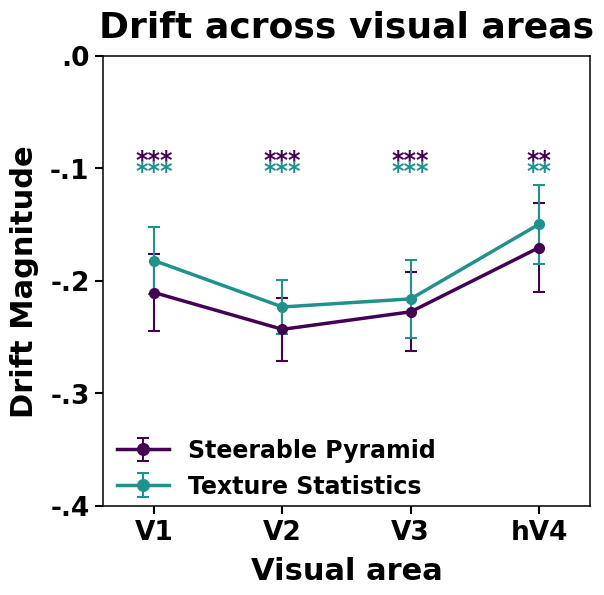


Saved: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/model_comparison/population/SP_vs_TS_population_drift_across_visual_areas_corr.png


In [13]:
# ============================================================
# POPULATION DRIFT
# SP vs TS × ROI
#
# Uses subject-level population drift summaries:
#   subject_corr_metric
#   subject_slope_metric
#
# 8 subjects × 4 ROIs × 2 models
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import pingouin as pg

from matplotlib.ticker import FuncFormatter

# ============================================================
# 1) SETTINGS
# ============================================================

SP_SUMMARY_DIR = (
    "/content/drive/MyDrive/V1_Drift/plots/"
    "drift_summaries/population"
)

TS_PERM_DIR = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_permutations"
)

OUT_DIR = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/model_comparison/population"
)

os.makedirs(OUT_DIR, exist_ok=True)


MODELS = ["SP", "TS"]

ROIS = ["V1", "V2", "V3", "hV4"]

N_SUBJECTS = 8

CORR_METHOD = "spearman"

# ------------------------------------------------------------
# Choose:
#
# "corr"  = Spearman correlation between
#           population similarity and session lag
#
# "slope" = linear slope of population similarity
#           as a function of session lag
# ------------------------------------------------------------

USE_DRIFT_METRIC = "corr"

SAVE_FIG = True


# ============================================================
# 2) CHOOSE DRIFT METRIC
# ============================================================

if USE_DRIFT_METRIC == "corr":

    metric_key = "subject_corr_metric"

    drift_metric_name = (
        "Spearman correlation of population "
        "similarity with session lag"
    )

    y_label = (
        "Spearman correlation\n"
        "population similarity vs. session lag"
    )

elif USE_DRIFT_METRIC == "slope":

    metric_key = "subject_slope_metric"

    drift_metric_name = (
        "Slope of population similarity "
        "with session lag"
    )

    y_label = (
        "Slope of population similarity\n"
        "vs. session lag"
    )

else:

    raise ValueError(
        "USE_DRIFT_METRIC must be 'corr' or 'slope'"
    )


print("Drift metric:")
print(drift_metric_name)


# ============================================================
# 3) LOAD SP SUMMARIES + TS PERMUTATION FILES
# ============================================================

loaded = {
    model: {}
    for model in MODELS
}


# ------------------------------------------------------------
# Helper: calculate drift metric from 29 lag values
# ------------------------------------------------------------

# ------------------------------------------------------------
# Helpers for population drift
#
# IMPORTANT:
# corr  -> calculated from the FULL session × session matrix
# slope -> calculated from the lag-collapsed curve
# ------------------------------------------------------------

def matrix_distance_correlation(mat, method="spearman"):

    mat = np.asarray(mat, dtype=float)

    n_sessions = mat.shape[0]

    dist_matrix = np.abs(
        np.subtract.outer(
            np.arange(n_sessions),
            np.arange(n_sessions)
        )
    )

    # Same logic as SP:
    # use all off-diagonal session pairs
    valid = (
        np.isfinite(mat)
        & (dist_matrix > 0)
    )

    if valid.sum() < 3:
        return np.nan

    x = dist_matrix[valid]
    y = mat[valid]

    if method == "spearman":
        r, _ = stats.spearmanr(x, y)

    elif method == "pearson":
        r, _ = stats.pearsonr(x, y)

    else:
        raise ValueError(method)

    return float(r)


def lag_curve_slope(curve):

    curve = np.asarray(curve, dtype=float)

    lags = np.arange(
        1,
        len(curve) + 1
    )

    valid = np.isfinite(curve)

    if valid.sum() < 3:
        return np.nan

    result = stats.linregress(
        lags[valid],
        curve[valid]
    )

    return float(result.slope)


# ============================================================
# LOAD SP
# ============================================================

print("\n" + "=" * 80)
print("SP")
print("=" * 80)


for roi in ROIS:

    fn = os.path.join(
        SP_SUMMARY_DIR,
        (
            f"population_{roi}_"
            f"rdmCorrDist_cmpSpearman_"
            f"{CORR_METHOD}_corr_and_slope.pkl"
        )
    )

    if not os.path.exists(fn):

        raise FileNotFoundError(
            f"Missing SP file:\n{fn}"
        )


    with open(fn, "rb") as f:
        d = pickle.load(f)


    vals = np.asarray(
        d[metric_key],
        dtype=float
    )


    if vals.shape != (N_SUBJECTS,):

        raise ValueError(
            f"Unexpected SP {roi} shape: "
            f"{vals.shape}"
        )


    loaded["SP"][roi] = {
        metric_key: vals
    }


    print(
        f"{roi:3s} | "
        f"n={len(vals)} | "
        f"mean={np.nanmean(vals): .6f} | "
        f"SD={np.nanstd(vals, ddof=1):.6f}"
    )


# ============================================================
# LOAD TS DIRECTLY FROM POPULATION PERMUTATION FILES
# ============================================================

print("\n" + "=" * 80)
print("TS")
print("=" * 80)


for roi in ROIS:

    vals = np.full(
        N_SUBJECTS,
        np.nan
    )


    for si in range(N_SUBJECTS):

        subject = si + 1


        # ----------------------------------------------------
        # We use the CorrDist + Spearman permutation file.
        #
        # For POPULATION drift:
        #   corr  -> avgImgCorrMat (full session × session matrix)
        #   slope -> betweenSessImg (lag-collapsed curve)
        # ----------------------------------------------------

        fn = os.path.join(
            TS_PERM_DIR,
            (
                f"permPop_TS_pcaHL95_raw_"
                f"N1000_"
                f"S{subject:02d}_"
                f"{roi}_"
                f"rdmCorrDist_cmpSpearman.npz"
            )
        )


        if not os.path.exists(fn):

            raise FileNotFoundError(
                f"Missing TS permutation file:\n{fn}"
            )


        d = np.load(
            fn,
            allow_pickle=True
        )


        # ----------------------------------------------------
        # POPULATION RESPONSE DRIFT
        #
        # Match the SP definitions exactly:
        #
        # corr:
        #   full session × session population similarity matrix
        #
        # slope:
        #   lag-collapsed population similarity curve
        # ----------------------------------------------------

        if USE_DRIFT_METRIC == "corr":

            mat = np.asarray(
                d["avgImgCorrMat"],
                dtype=float
            )

            if mat.ndim != 2 or mat.shape[0] != mat.shape[1]:
                raise ValueError(
                    f"Unexpected avgImgCorrMat shape "
                    f"for S{subject:02d} {roi}: "
                    f"{mat.shape}"
                )

            vals[si] = matrix_distance_correlation(
                mat,
                method=CORR_METHOD
            )


        elif USE_DRIFT_METRIC == "slope":

            curve = np.asarray(
                d["betweenSessImg"],
                dtype=float
            )

            if curve.ndim != 1:
                raise ValueError(
                    f"Unexpected betweenSessImg shape "
                    f"for S{subject:02d} {roi}: "
                    f"{curve.shape}"
                )

            vals[si] = lag_curve_slope(
                curve
            )


        else:

            raise ValueError(
                "USE_DRIFT_METRIC must be 'corr' or 'slope'"
            )


    loaded["TS"][roi] = {
        metric_key: vals
    }


    print(
        f"{roi:3s} | "
        f"n={len(vals)} | "
        f"mean={np.nanmean(vals): .6f} | "
        f"SD={np.nanstd(vals, ddof=1):.6f}"
    )


print(
    "\nAll SP and TS population data loaded successfully."
)


# ============================================================
# 5) BUILD LONG DATAFRAME
#
# 8 subjects × 4 ROIs × 2 models
# = 64 observations
# ============================================================

rows = []


for model in MODELS:

    for roi in ROIS:

        values = np.asarray(
            loaded[model][roi][metric_key],
            dtype=float
        )


        for si, value in enumerate(values):

            rows.append(
                {
                    "subject": f"S{si + 1:02d}",
                    "Model": model,
                    "ROI": roi,
                    "drift": value
                }
            )


df = pd.DataFrame(rows)


print("\n" + "=" * 80)
print("LONG DATAFRAME")
print("=" * 80)

display(df)


print("\nCounts per Model × ROI:")

display(
    df.groupby(
        ["Model", "ROI"]
    ).size()
)


# ============================================================
# 6) CHECK COMPLETE REPEATED-MEASURES DESIGN
# ============================================================

expected_n = (
    len(MODELS)
    *
    len(ROIS)
    *
    N_SUBJECTS
)


print(
    f"\nExpected observations: {expected_n}"
)

print(
    f"Actual observations:   {len(df)}"
)


if len(df) != expected_n:

    raise ValueError(
        "Incomplete Model × ROI × Subject design."
    )


if df["drift"].isna().any():

    print(
        "\nWARNING: NaN drift values detected:"
    )

    display(
        df[df["drift"].isna()]
    )

else:

    print(
        "\nNo NaN drift values."
    )


# ============================================================
# 7) WIDE TABLE
# ============================================================

df_wide = df.pivot(
    index="subject",
    columns=["Model", "ROI"],
    values="drift"
)


print("\n" + "=" * 80)
print("SUBJECT × MODEL × ROI")
print("=" * 80)

display(df_wide)


# ============================================================
# 8) DESCRIPTIVE SUMMARY
# ============================================================

summary_df = (
    df
    .groupby(
        ["Model", "ROI"]
    )["drift"]
    .agg(
        [
            "mean",
            "std",
            "sem",
            "median",
            "min",
            "max"
        ]
    )
    .reset_index()
)


print("\n" + "=" * 80)
print("DESCRIPTIVE STATISTICS")
print("=" * 80)

display(summary_df)


# ============================================================
# 9) TWO-WAY REPEATED-MEASURES ANOVA
#
# Within-subject factors:
#
# Model:
#   SP / TS
#
# ROI:
#   V1 / V2 / V3 / hV4
#
# Tests:
#
# 1. Main effect of Model
# 2. Main effect of ROI
# 3. Model × ROI interaction
# ============================================================

print("\n" + "=" * 80)
print("2 × 4 REPEATED-MEASURES ANOVA")
print("=" * 80)


aov = pg.rm_anova(
    data=df,
    dv="drift",
    within=[
        "Model",
        "ROI"
    ],
    subject="subject",
    detailed=True,
    effsize="np2"
)


display(aov)


# ============================================================
# 10) SP vs TS WITHIN EACH ROI
#
# Paired because the same 8 subjects are represented
# in both models.
# ============================================================

model_comparison_rows = []


for roi in ROIS:

    sp_df = (
        df[
            (df["Model"] == "SP")
            &
            (df["ROI"] == roi)
        ]
        .sort_values("subject")
    )


    ts_df = (
        df[
            (df["Model"] == "TS")
            &
            (df["ROI"] == roi)
        ]
        .sort_values("subject")
    )


    # --------------------------------------------------------
    # Make sure subjects align
    # --------------------------------------------------------

    if not np.array_equal(
        sp_df["subject"].values,
        ts_df["subject"].values
    ):

        raise ValueError(
            f"Subject mismatch between SP and TS in {roi}"
        )


    sp = sp_df[
        "drift"
    ].values.astype(float)


    ts = ts_df[
        "drift"
    ].values.astype(float)


    valid = (
        np.isfinite(sp)
        &
        np.isfinite(ts)
    )


    sp = sp[valid]
    ts = ts[valid]


    # --------------------------------------------------------
    # paired t-test
    # --------------------------------------------------------

    t_stat, p_t = stats.ttest_rel(
        sp,
        ts
    )


    # --------------------------------------------------------
    # Wilcoxon signed-rank test
    # --------------------------------------------------------

    try:

        W, p_w = stats.wilcoxon(
            sp,
            ts
        )

    except ValueError:

        W = np.nan
        p_w = np.nan


    # --------------------------------------------------------
    # paired effect size
    #
    # positive:
    # TS > SP
    #
    # negative:
    # TS < SP
    # --------------------------------------------------------

    diff = ts - sp


    diff_sd = np.std(
        diff,
        ddof=1
    )


    if (
        np.isfinite(diff_sd)
        and
        diff_sd > 0
    ):

        dz = (
            np.mean(diff)
            /
            diff_sd
        )

    else:

        dz = np.nan


    model_comparison_rows.append(
        {
            "ROI": roi,

            "SP_mean":
                np.mean(sp),

            "TS_mean":
                np.mean(ts),

            "TS_minus_SP":
                np.mean(diff),

            "paired_t":
                t_stat,

            "p_paired_t":
                p_t,

            "wilcoxon_W":
                W,

            "p_wilcoxon":
                p_w,

            "cohen_dz_TS_minus_SP":
                dz,

            "n":
                len(sp)
        }
    )


model_comparison_df = pd.DataFrame(
    model_comparison_rows
)


# ============================================================
# 11) FDR CORRECTION
#
# Four SP-vs-TS comparisons:
# V1, V2, V3, hV4
# ============================================================

_, p_t_fdr = pg.multicomp(
    model_comparison_df[
        "p_paired_t"
    ].values,
    method="fdr_bh"
)


_, p_w_fdr = pg.multicomp(
    model_comparison_df[
        "p_wilcoxon"
    ].values,
    method="fdr_bh"
)


model_comparison_df[
    "p_paired_t_fdr"
] = p_t_fdr


model_comparison_df[
    "p_wilcoxon_fdr"
] = p_w_fdr


print("\n" + "=" * 80)
print("SP vs TS WITHIN EACH ROI")
print("=" * 80)

display(
    model_comparison_df
)


# ============================================================
# 12) ROI EFFECT WITHIN EACH MODEL
#
# Useful follow-up:
#
# Does population drift differ across V1-hV4
# separately for SP and TS?
# ============================================================

roi_anovas = {}


for model in MODELS:

    df_model = df[
        df["Model"] == model
    ].copy()


    aov_model = pg.rm_anova(
        data=df_model,
        dv="drift",
        within="ROI",
        subject="subject",
        detailed=True,
        effsize="np2"
    )


    roi_anovas[model] = aov_model


    print(
        "\n" + "=" * 80
    )

    print(
        f"ROI EFFECT WITHIN {model}"
    )

    print(
        "=" * 80
    )


    display(
        aov_model
    )

# ============================================================
# POPULATION SIGNIFICANCE TESTS FOR PLOT
# ============================================================

def p_to_stars(p):

    if not np.isfinite(p):
        return ""

    if p < 0.001:
        return "***"

    elif p < 0.01:
        return "**"

    elif p < 0.05:
        return "*"

    return ""


# ============================================================
# 1) IS DRIFT SIGNIFICANTLY DIFFERENT FROM ZERO?
#
# One-sample tests across the 8 subjects.
# FDR correction across the 4 ROIs separately for each model.
# ============================================================

roi_sig_results = {}


for model in MODELS:

    rows_sig = []

    for roi in ROIS:

        vals = (
            df[
                (df["Model"] == model)
                &
                (df["ROI"] == roi)
            ]
            .sort_values("subject")["drift"]
            .values
            .astype(float)
        )

        vals = vals[
            np.isfinite(vals)
        ]

        t_stat, p = stats.ttest_1samp(
            vals,
            popmean=0
        )

        rows_sig.append(
            {
                "ROI": roi,
                "t": t_stat,
                "p": p,
                "n": len(vals)
            }
        )


    sig_df = pd.DataFrame(
        rows_sig
    )


    # FDR across V1, V2, V3, hV4
    _, p_fdr = pg.multicomp(
        sig_df["p"].values,
        method="fdr_bh"
    )


    sig_df["p_fdr"] = p_fdr

    sig_df["stars"] = (
        sig_df["p_fdr"]
        .apply(p_to_stars)
    )


    roi_sig_results[model] = sig_df


sp_roi_sig = roi_sig_results["SP"]

ts_roi_sig = roi_sig_results["TS"]


print("\nSP drift vs zero:")
display(sp_roi_sig)

print("\nTS drift vs zero:")
display(ts_roi_sig)


# ============================================================
# 2) ROI vs ROI COMPARISONS WITHIN EACH MODEL
#
# Paired tests because the same subjects contribute
# to each visual area.
#
# 6 pairwise comparisons/model.
# FDR correction separately within each model.
# ============================================================

from itertools import combinations


pair_results = {}


for model in MODELS:

    rows_pairs = []

    for roi_a, roi_b in combinations(
        ROIS,
        2
    ):

        a = (
            df[
                (df["Model"] == model)
                &
                (df["ROI"] == roi_a)
            ]
            .sort_values("subject")["drift"]
            .values
            .astype(float)
        )


        b = (
            df[
                (df["Model"] == model)
                &
                (df["ROI"] == roi_b)
            ]
            .sort_values("subject")["drift"]
            .values
            .astype(float)
        )


        valid = (
            np.isfinite(a)
            &
            np.isfinite(b)
        )


        a = a[valid]
        b = b[valid]


        t_stat, p = stats.ttest_rel(
            a,
            b
        )


        rows_pairs.append(
            {
                "ROI_A": roi_a,
                "ROI_B": roi_b,
                "t": t_stat,
                "p": p,
                "n": len(a)
            }
        )


    pair_df = pd.DataFrame(
        rows_pairs
    )


    # FDR across all 6 ROI comparisons
    _, p_fdr = pg.multicomp(
        pair_df["p"].values,
        method="fdr_bh"
    )


    pair_df["p_fdr"] = p_fdr

    pair_df["stars"] = (
        pair_df["p_fdr"]
        .apply(p_to_stars)
    )


    pair_results[model] = pair_df


sp_pairs = pair_results["SP"]

ts_pairs = pair_results["TS"]


# Keep only significant comparisons for plotting

sp_sig_pairs = sp_pairs[
    sp_pairs["p_fdr"] < 0.05
].copy()


ts_sig_pairs = ts_pairs[
    ts_pairs["p_fdr"] < 0.05
].copy()


print("\nSP ROI pairwise comparisons:")
display(sp_pairs)

print("\nTS ROI pairwise comparisons:")
display(ts_pairs)

print("\nSignificant SP pairs:")
display(sp_sig_pairs)

print("\nSignificant TS pairs:")
display(ts_sig_pairs)


# ============================================================
# 13) PLOT
# ============================================================
# POPULATION PLOT
# Same visual style as single-voxel plot
# ============================================================

xpos = np.arange(len(ROIS))

roi_x = {
    roi: i
    for i, roi in enumerate(ROIS)
}


# ============================================================
# CALCULATE MODEL MEANS + SEM
# ============================================================

sp_mean = []
sp_sem = []

ts_mean = []
ts_sem = []


for roi in ROIS:

    # SP
    vals = df[
        (df["Model"] == "SP")
        &
        (df["ROI"] == roi)
    ]["drift"].values.astype(float)

    sp_mean.append(
        np.nanmean(vals)
    )

    sp_sem.append(
        stats.sem(
            vals,
            nan_policy="omit"
        )
    )


    # TS
    vals = df[
        (df["Model"] == "TS")
        &
        (df["ROI"] == roi)
    ]["drift"].values.astype(float)

    ts_mean.append(
        np.nanmean(vals)
    )

    ts_sem.append(
        stats.sem(
            vals,
            nan_policy="omit"
        )
    )


sp_mean = np.asarray(sp_mean)
sp_sem = np.asarray(sp_sem)

ts_mean = np.asarray(ts_mean)
ts_sem = np.asarray(ts_sem)


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 6.0)
)

# Exact same plotting-box position in both figures
ax.set_position([
    0.21,   # left
    0.15,   # bottom
    0.75,   # width
    0.75    # height
])


# ============================================================
# COLORS
# ============================================================

SP_COLOR = "#440154"   # purple
TS_COLOR = "#21918c"   # teal


# ============================================================
# SP LINE
# ============================================================

sp_plot = ax.errorbar(
    xpos,
    sp_mean,
    yerr=sp_sem,

    marker="o",
    markersize=7,

    linewidth=2.5,

    capsize=4,
    capthick=1.5,
    elinewidth=1.5,

    color=SP_COLOR,

    label="Steerable Pyramid",

    zorder=4
)


# ============================================================
# TS LINE
# ============================================================

ts_plot = ax.errorbar(
    xpos,
    ts_mean,
    yerr=ts_sem,

    marker="o",
    markersize=7,

    linewidth=2.5,

    capsize=4,
    capthick=1.5,
    elinewidth=1.5,

    color=TS_COLOR,

    label="Texture Statistics",

    zorder=4
)


sp_color = SP_COLOR
ts_color = TS_COLOR


# ============================================================
# DATA RANGE
# ============================================================

all_lower = np.concatenate([
    sp_mean - sp_sem,
    ts_mean - ts_sem
])

all_upper = np.concatenate([
    sp_mean + sp_sem,
    ts_mean + ts_sem
])

data_min = np.nanmin(all_lower)
data_max = np.nanmax(all_upper)

data_range = data_max - data_min

if data_range == 0:
    data_range = 1.0


# ============================================================
# ROI DRIFT STARS
#
# Drift significantly different from zero
# SP = upper row
# TS = lower row
# ============================================================

sp_star_y = (
    data_max
    + 0.07 * data_range
)

ts_star_y = (
    data_max
    + 0.01 * data_range
)


for i, roi in enumerate(ROIS):

    # SP
    stars = sp_roi_sig.loc[
        sp_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            sp_star_y,
            stars,
            ha="center",
            va="bottom",
            fontsize=17,
            fontweight="bold",
            color=sp_color
        )


    # TS
    stars = ts_roi_sig.loc[
        ts_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            ts_star_y,
            stars,
            ha="center",
            va="bottom",
            fontsize=17,
            fontweight="bold",
            color=ts_color
        )


# ============================================================
# BRACKET FUNCTION
# ============================================================

def draw_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    stars,
    color
):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color=color,
        linewidth=1.5,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h,
        stars,
        ha="center",
        va="bottom",
        fontsize=17,
        fontweight="bold",
        color=color
    )


# ============================================================
# SIGNIFICANT ROI DIFFERENCE BRACKETS
# ============================================================

bracket_base = (
    data_max
    + 0.18 * data_range
)

bracket_step = (
    0.09 * data_range
)

bracket_h = (
    0.025 * data_range
)

bracket_number = 0


# SP brackets
for _, row in sp_sig_pairs.iterrows():

    x1 = roi_x[row["ROI_A"]]
    x2 = roi_x[row["ROI_B"]]

    y = (
        bracket_base
        + bracket_number * bracket_step
    )

    draw_bracket(
        ax,
        x1,
        x2,
        y,
        bracket_h,
        row["stars"],
        sp_color
    )

    bracket_number += 1


# TS brackets
for _, row in ts_sig_pairs.iterrows():

    x1 = roi_x[row["ROI_A"]]
    x2 = roi_x[row["ROI_B"]]

    y = (
        bracket_base
        + bracket_number * bracket_step
    )

    draw_bracket(
        ax,
        x1,
        x2,
        y,
        bracket_h,
        row["stars"],
        ts_color
    )

    bracket_number += 1


# ============================================================
# Y-AXIS LIMITS
# ============================================================

n_sig_pairs = (
    len(sp_sig_pairs)
    +
    len(ts_sig_pairs)
)


# ============================================================
# Y-AXIS LIMITS / TICKS
# ============================================================

if USE_DRIFT_METRIC == "corr":

    ymin = -0.4
    ymax = 0

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_yticks([
        -0.4,
        -0.3,
        -0.2,
        -0.1,
        0
    ])


elif USE_DRIFT_METRIC == "slope":

    ymin = (
        data_min
        - 0.55 * data_range
    )

    ymax = (
        data_max
        + 0.32 * data_range
        + max(n_sig_pairs - 1, 0)
        * 0.12 * data_range
    )

    ax.set_ylim(
        ymin,
        ymax
    )


# ============================================================
# Y-AXIS NUMBER FORMAT
# ============================================================

def no_leading_zero(x, pos):

    # --------------------------------------------------------
    # Correlation:
    # e.g. -0.8 -> -.8
    # --------------------------------------------------------

    if USE_DRIFT_METRIC == "corr":

        s = f"{x:.1f}"


    # --------------------------------------------------------
    # Slope:
    # e.g. -0.0008 -> -.0008
    # --------------------------------------------------------

    else:

        s = f"{x:.4f}"


    if s.startswith("-0."):

        s = "-." + s[3:]

    elif s.startswith("0."):

        s = "." + s[2:]

    elif s == "-0.0":

        s = ".0"

    elif s == "-0.0000":

        s = ".0000"

    return s


ax.yaxis.set_major_formatter(
    FuncFormatter(no_leading_zero)
)


# ============================================================
# AXES
# ============================================================

ax.set_xticks(xpos)

ax.set_xticklabels(
    ROIS,
    fontsize=20,
    fontweight="bold"
)

ax.set_xlim(
    -0.4,
    len(ROIS) - 0.6
)

ax.set_xlabel(
    "Visual area",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_ylabel(
    "Drift Magnitude",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_title(
    "Drift across visual areas",
    fontsize=26,
    fontweight="bold",
    pad=14
)


# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="both",
    labelsize=19,
    width=1.5,
    length=6
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")


# ============================================================
# MODEL LEGEND
# ============================================================

legend = ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.01, -0.005),
    frameon=False,
    fontsize=17,
    borderaxespad=0,
    handlelength=2.2,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")

# ============================================================
# SPINES
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        1.1
    )


# ============================================================
# LAYOUT
# ============================================================

fig.subplots_adjust(
    top=0.90,
    bottom=0.15,
    left=0.21,
    right=0.96
)


# ============================================================
# SAVE
# ============================================================

fig_path = os.path.join(
    OUT_DIR,
    f"SP_vs_TS_population_"
    f"drift_across_visual_areas_"
    f"{USE_DRIFT_METRIC}.png"
)

fig.savefig(
    fig_path,
    dpi=300,
    pad_inches=0.20
)

plt.show()

print(
    "\nSaved:",
    fig_path
)

## relative to lag 1

LOADING STEERABLE PYRAMID
V1: (8, 29)
V2: (8, 29)
V3: (8, 29)
hV4: (8, 29)

LOADING TEXTURE STATISTICS
V1: (8, 29)
V2: (8, 29)
V3: (8, 29)
hV4: (8, 29)


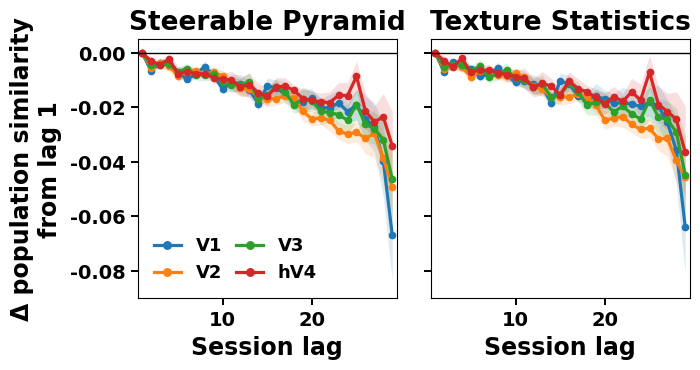

In [33]:
# ============================================================
# POPULATION SIMILARITY DECLINE FROM LAG 1
# Steerable Pyramid vs Texture Statistics
#
# Standalone figure for poster
# ============================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# SETTINGS
# ============================================================

SP_SUMMARY_DIR = (
    "/content/drive/MyDrive/V1_Drift/plots/drift_summaries/population"
)

TS_PERM_DIR = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/population_permutations"
)

OUT_DIR = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/model_comparison/population"
)

os.makedirs(OUT_DIR, exist_ok=True)

ROIS = ["V1", "V2", "V3", "hV4"]
N_SUBJECTS = 8

# Must match the SP summary files
TO_ZSCORE = 0
CORR_METHOD = "pearson"

RDM_BUILD_METRIC = "correlation"
RDM_COMPARE_METRIC = "spearman"

SAVE_FIG = True


# ============================================================
# HELPERS
# ============================================================

def _zstr(z):
    return ["", "_zscore", "_zeroMean",
            "_equalStd", "_zeroROImean"][z]


def metric_tag(rdm_build_metric, rdm_compare_metric):

    build_tag = {
        "correlation": "rdmCorrDist",
        "euclidean": "rdmEuclidean"
    }[rdm_build_metric]

    compare_tag = {
        "spearman": "cmpSpearman",
        "rmse": "cmpRMSE"
    }[rdm_compare_metric]

    return f"{build_tag}_{compare_tag}"


tag = metric_tag(
    RDM_BUILD_METRIC,
    RDM_COMPARE_METRIC
)


# ============================================================
# LOAD SP SUBJECT-LEVEL LAG CURVES
# ============================================================

sp_curves = {}

print("=" * 70)
print("LOADING STEERABLE PYRAMID")
print("=" * 70)

for roi in ROIS:

    fn = os.path.join(
        SP_SUMMARY_DIR,
        f"population_{roi}"
        f"{_zstr(TO_ZSCORE)}"
        f"_{tag}"
        f"_{CORR_METHOD}"
        f"_corr_and_slope.pkl"
    )

    if not os.path.exists(fn):
        raise FileNotFoundError(
            f"Missing SP file:\n{fn}"
        )

    with open(fn, "rb") as f:
        d = pickle.load(f)

    curves = np.asarray(
        d["subject_curves"],
        dtype=float
    )

    sp_curves[roi] = curves

    print(
        f"{roi}: {curves.shape}"
    )


# ============================================================
# LOAD TS SUBJECT-LEVEL LAG CURVES
# ============================================================

ts_curves = {}

print("\n" + "=" * 70)
print("LOADING TEXTURE STATISTICS")
print("=" * 70)

for roi in ROIS:

    roi_curves = []

    for subject in range(1, N_SUBJECTS + 1):

        fn = os.path.join(
            TS_PERM_DIR,
            (
                f"permPop_TS_pcaHL95_raw_"
                f"N1000_"
                f"S{subject:02d}_"
                f"{roi}_"
                f"rdmCorrDist_cmpSpearman.npz"
            )
        )

        if not os.path.exists(fn):
            raise FileNotFoundError(
                f"Missing TS file:\n{fn}"
            )

        d = np.load(
            fn,
            allow_pickle=True
        )

        curve = np.asarray(
            d["betweenSessImg"],
            dtype=float
        )

        if curve.ndim != 1:
            raise ValueError(
                f"Unexpected TS curve shape "
                f"S{subject:02d} {roi}: "
                f"{curve.shape}"
            )

        roi_curves.append(curve)

    # subjects × lags
    roi_curves = np.vstack(
        roi_curves
    )

    ts_curves[roi] = roi_curves

    print(
        f"{roi}: {roi_curves.shape}"
    )


# ============================================================
# SANITY CHECK
# ============================================================

for roi in ROIS:

    if sp_curves[roi].shape != ts_curves[roi].shape:

        print(
            f"WARNING: {roi} shapes differ: "
            f"SP={sp_curves[roi].shape}, "
            f"TS={ts_curves[roi].shape}"
        )


# ============================================================
# ROI COLORS
# ============================================================

# Matplotlib default colors = same as your current figures

ROI_COLORS = {
    "V1": "C0",
    "V2": "C1",
    "V3": "C2",
    "hV4": "C3"
}


# ============================================================
# FIGURE — POSTER STYLE
# ============================================================

from matplotlib.ticker import FormatStrFormatter

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.6, 3.7),
    sharex=True,
    sharey=True
)

model_data = [
    ("Steerable Pyramid", sp_curves),
    ("Texture Statistics", ts_curves)
]


for ax, (model_name, curves_dict) in zip(axes, model_data):

    for roi in ROIS:

        curves = curves_dict[roi]

        # Subject-wise change relative to lag 1
        delta = curves - curves[:, [0]]

        mean_curve = np.nanmean(
            delta,
            axis=0
        )

        sem_curve = stats.sem(
            delta,
            axis=0,
            nan_policy="omit"
        )

        lags = np.arange(
            1,
            delta.shape[1] + 1
        )

        line, = ax.plot(
            lags,
            mean_curve,
            marker="o",
            markersize=4.5,
            linewidth=2.3,
            label=roi
        )

        ax.fill_between(
            lags,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            color=line.get_color(),
            alpha=0.15,
            linewidth=0
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1.0
    )

    # PANEL TITLE
    ax.set_title(
        model_name,
        fontsize=19,
        fontweight="bold",
        pad=7
    )

    # X AXIS TITLE
    ax.set_xlabel(
        "Session lag",
        fontsize=17,
        fontweight="bold",
        labelpad=5
    )

    # TICK LABELS
    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.4,
        length=5
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    ax.set_box_aspect(1)

    ax.set_xlim(
        0.5,
        29.5
    )


# ============================================================
# Y AXIS
# ============================================================

axes[0].set_ylabel(
    "Δ population similarity\nfrom lag 1",
    fontsize=17,
    fontweight="bold",
    labelpad=6
)

axes[0].set_ylim(
    -0.09,
    0.005
)

# Two decimal places, same as single-voxel figure
axes[0].yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)


# ============================================================
# LEGEND
# ============================================================

legend = axes[0].legend(
    frameon=False,
    fontsize=13,
    loc="lower left",
    ncol=2,
    handlelength=1.5,
    columnspacing=0.8,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ============================================================
# COMPACT LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.14,
    right=0.995,
    bottom=0.21,
    top=0.91,
    wspace=0.08
)


# ============================================================
# SAVE
# ============================================================

if SAVE_FIG:

    png_path = os.path.join(
        OUT_DIR,
        "SP_vs_TS_delta_population_similarity_COMPACT.png"
    )

    pdf_path = os.path.join(
        OUT_DIR,
        "SP_vs_TS_delta_population_similarity_COMPACT.pdf"
    )

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.03
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.03
    )

plt.show()

# RDM


## GOF PLOT

Mounted at /content/drive
ROIs to run: ['V1']

TS RDM poster figure: V1 | rdmCorrDist_cmpSpearman
TS V1: r=-0.029, p=0.2388, sig subjects=1/8
Subjects: [1 2 3 4 5 6 7 8]
Subject r: [-0.031   0.0214 -0.0875 -0.0426  0.0341  0.015   0.0155 -0.1579]


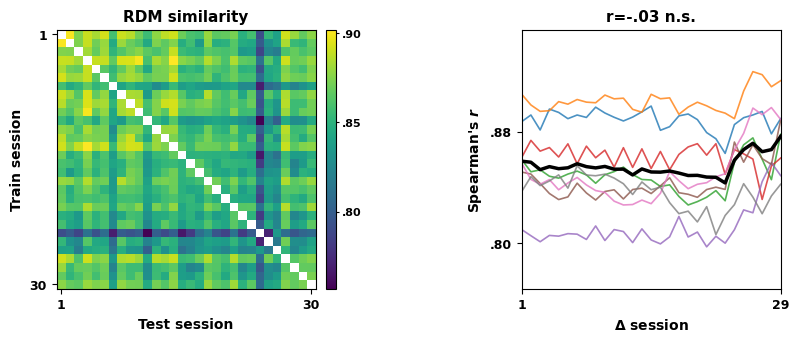

Saved figure to: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/model_comparison/TS_poster_figures/TS_rdm_V1_poster_pcaHL95_raw_rdmCorrDist_cmpSpearman_spearman_clean_square.png

TS RDM poster figure: V1 | rdmCorrDist_cmpRMSE
TS V1: r=-0.007, p=0.5255, sig subjects=1/8
Subjects: [1 2 3 4 5 6 7 8]
Subject r: [-0.0944 -0.0471 -0.0873  0.0323  0.0449 -0.0336 -0.0548  0.1848]


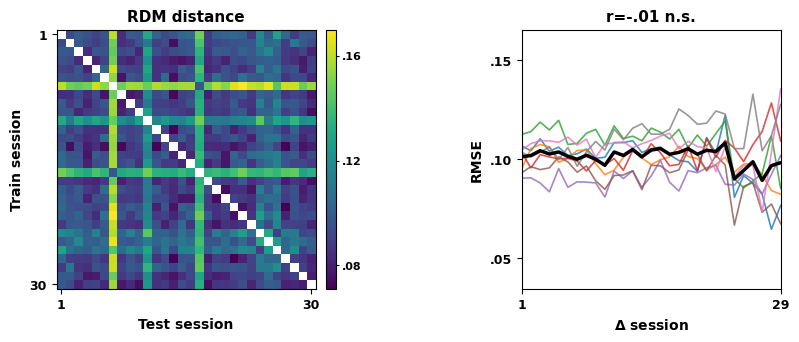

Saved figure to: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/model_comparison/TS_poster_figures/TS_rdm_V1_poster_pcaHL95_raw_rdmCorrDist_cmpRMSE_spearman_clean_square.png

TS RDM poster figure: V1 | rdmEuclidean_cmpSpearman
TS V1: r=-0.025, p=0.2767, sig subjects=1/8
Subjects: [1 2 3 4 5 6 7 8]
Subject r: [-0.0123  0.0322 -0.1046 -0.007   0.0136  0.0086  0.0146 -0.1462]


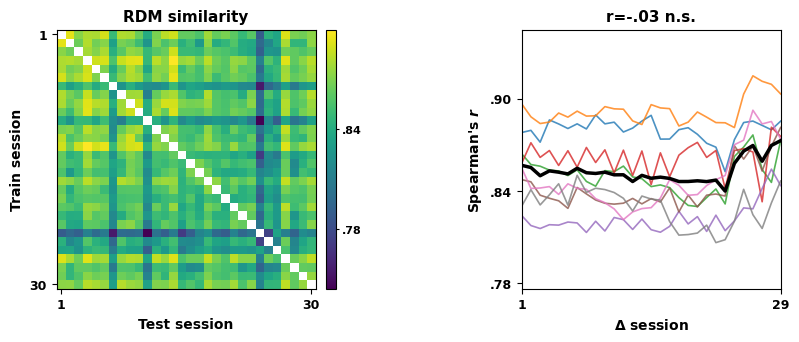

Saved figure to: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/model_comparison/TS_poster_figures/TS_rdm_V1_poster_pcaHL95_raw_rdmEuclidean_cmpSpearman_spearman_clean_square.png

TS RDM poster figure: V1 | rdmEuclidean_cmpRMSE
TS V1: r=0.002, p=0.4286, sig subjects=0/8
Subjects: [1 2 3 4 5 6 7 8]
Subject r: [ 0.0129  0.0138  0.0384  0.0788 -0.0191 -0.0749 -0.0508  0.0155]


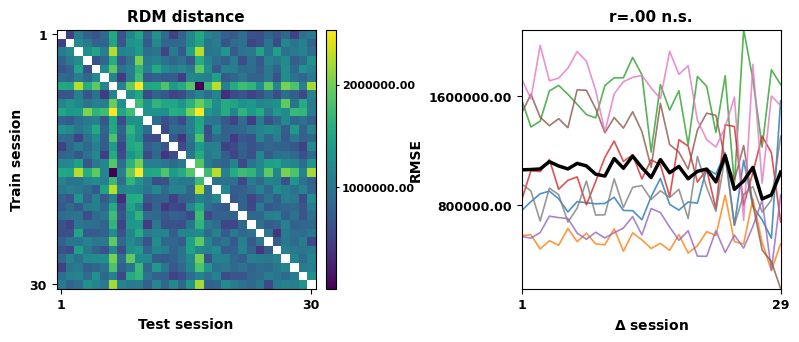

Saved figure to: /content/drive/MyDrive/V2_drift/texturemodel/drift_results/model_comparison/TS_poster_figures/TS_rdm_V1_poster_pcaHL95_raw_rdmEuclidean_cmpRMSE_spearman_clean_square.png


In [74]:
# ============================================================
# TS RDM drift poster figure — V1 only
# pcaHL95 | raw
#
# Clean square 2-panel version:
#   LEFT  = group session × session RDM comparison matrix
#   RIGHT = RDM comparison metric as a function of session lag
#
# IMPORTANT:
#   The r value and permutation significance are calculated
#   from the FULL session × session matrix.
#
#   The lag curve is shown for visualization only.
# ============================================================


import os

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from google.colab import drive
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.ticker import FuncFormatter, MaxNLocator


# ============================================================
# MOUNT DRIVE
# ============================================================

drive.mount(
    "/content/drive",
    force_remount=True
)


# ============================================================
# USER SETTINGS
# ============================================================

BASE_FOLDER = (
    "/content/drive/MyDrive/V2_drift/"
    "texturemodel/drift_results/"
    "population_permutations"
)


OUT_DIR = (
    "/content/drive/MyDrive/V2_drift/"
    "texturemodel/drift_results/"
    "model_comparison/TS_poster_figures"
)


os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# MODEL SETTINGS
# ------------------------------------------------------------

PCA_TYPE = "pcaHL"

PCA_PCT_VAR = 95

NORMALIZATION = "raw"


# ------------------------------------------------------------
# Correlation used to quantify drift:
#
# temporal session distance
#        vs
# RDM similarity / distance
#
# This matches the comparison analysis:
# Spearman correlation across all off-diagonal
# entries of the full 30 × 30 matrix.
# ------------------------------------------------------------

CORR_METHOD = "spearman"


NPERMS_WANT = 1000


SUBJECTS = list(
    range(1, 9)
)

# ============================================================
# ROI SETTINGS
# ============================================================

# Choose:
#   "one" -> run only SELECTED_ROI
#   "all" -> run V1, V2, V3, hV4

ROI_MODE = "one"

SELECTED_ROI = "V1"


ALL_ROIS = [
    "V1",
    "V2",
    "V3",
    "hV4"
]


if ROI_MODE == "one":

    if SELECTED_ROI not in ALL_ROIS:
        raise ValueError(
            f"SELECTED_ROI must be one of {ALL_ROIS}"
        )

    ROIS_TO_RUN = [
        SELECTED_ROI
    ]


elif ROI_MODE == "all":

    ROIS_TO_RUN = ALL_ROIS


else:

    raise ValueError(
        "ROI_MODE must be 'one' or 'all'"
    )


print(
    "ROIs to run:",
    ROIS_TO_RUN
)

# ============================================================
# RDM COMBINATIONS
# ============================================================

RDM_COMBOS = [

    (
        "correlation",
        "spearman"
    ),

    (
        "correlation",
        "rmse"
    ),

    (
        "euclidean",
        "spearman"
    ),

    (
        "euclidean",
        "rmse"
    )

]


# ============================================================
# POSTER STYLE
# ============================================================

FIG_W = 8.5

FIG_H = 3.7


SUBTITLE_FS = 11

LABEL_FS = 10

TICK_FS = 9

CBAR_FS = 8


LINEWIDTH_MEAN = 2.5

LINEWIDTH_SUBJ = 1.2

ALPHA_SUBJ = 0.8


plt.rcParams[
    "font.weight"
] = "bold"

plt.rcParams[
    "axes.labelweight"
] = "bold"

plt.rcParams[
    "axes.titleweight"
] = "bold"


# ============================================================
# NUMBER FORMATTER
#
#  0.85 -> .85
# -0.05 -> -.05
# ============================================================

def no_leading_zero(
    x,
    pos
):

    s = f"{x:.2f}"

    if s.startswith(
        "0."
    ):

        return s[1:]


    if s.startswith(
        "-0."
    ):

        return (
            "-"
            + s[2:]
        )


    return s


# ============================================================
# HELPERS
# ============================================================

def metric_tag(
    rdm_build_metric,
    rdm_compare_metric
):

    build_tag = {

        "correlation":
            "rdmCorrDist",

        "euclidean":
            "rdmEuclidean"

    }[
        rdm_build_metric
    ]


    compare_tag = {

        "spearman":
            "cmpSpearman",

        "rmse":
            "cmpRMSE"

    }[
        rdm_compare_metric
    ]


    return (
        f"{build_tag}_{compare_tag}"
    )


# ============================================================
# TS PERMUTATION FILE PATH
#
# Example:
#
# permPop_TS_pcaHL95_raw_N1000_
# S01_V1_rdmCorrDist_cmpSpearman.npz
# ============================================================

def perm_pop_path(
    base_folder,
    roi,
    subject,
    nperms,
    rdm_build_metric,
    rdm_compare_metric
):

    tag = metric_tag(
        rdm_build_metric,
        rdm_compare_metric
    )


    filename = (

        f"permPop_TS_"
        f"{PCA_TYPE}{PCA_PCT_VAR}_"
        f"{NORMALIZATION}_"
        f"N{nperms}_"
        f"S{subject:02d}_"
        f"{roi}_"
        f"{tag}.npz"

    )


    return os.path.join(
        base_folder,
        filename
    )


# ============================================================
# SAFE CORRELATION
# ============================================================

def safe_corr(
    x,
    y,
    method=CORR_METHOD
):

    x = np.asarray(
        x
    ).ravel()


    y = np.asarray(
        y
    ).ravel()


    mask = (

        np.isfinite(x)

        &

        np.isfinite(y)

    )


    if np.sum(
        mask
    ) < 3:

        return np.nan


    x = x[
        mask
    ]

    y = y[
        mask
    ]


    if method == "pearson":

        return pearsonr(
            x,
            y
        )[0]


    if method == "spearman":

        return spearmanr(
            x,
            y
        )[0]


    raise ValueError(
        f"Unknown correlation method: {method}"
    )


# ============================================================
# CORRELATION BETWEEN
# TEMPORAL DISTANCE AND FULL RDM-COMPARISON MATRIX
#
# IMPORTANT:
# Uses ALL off-diagonal session pairs.
# ============================================================

def matrix_distance_correlation(
    mat,
    dist_matrix
):

    mat = np.asarray(
        mat,
        dtype=float
    )


    dist_matrix = np.asarray(
        dist_matrix,
        dtype=float
    )


    mask = (

        np.isfinite(
            mat
        )

        &

        (
            dist_matrix
            > 0
        )

    )


    if np.sum(
        mask
    ) < 3:

        return np.nan


    return safe_corr(

        dist_matrix[
            mask
        ],

        mat[
            mask
        ],

        method=
            CORR_METHOD

    )


# ============================================================
# SIGNIFICANCE STARS
# ============================================================

def significance_stars(
    p
):

    if p < 0.001:

        return "***"


    if p < 0.01:

        return "**"


    if p < 0.05:

        return "*"


    return "n.s."


# ============================================================
# LABELS + DIRECTION OF PERMUTATION TEST
#
# SPEARMAN RDM COMPARISON:
#   RDM similarity should DECREASE with temporal distance.
#   Therefore raw drift correlation is negative.
#
# RMSE RDM COMPARISON:
#   RDM distance should INCREASE with temporal distance.
#   Therefore raw drift correlation is positive.
# ============================================================

def get_axis_labels_and_tail(
    rdm_compare_metric
):

    if (
        rdm_compare_metric
        == "spearman"
    ):

        return {

            "matrix_title":
                "RDM similarity",

            "matrix_label":
                "Spearman's r",

            "curve_label":
                "Spearman's r",

            "p_tail":
                "negative"

        }


    if (
        rdm_compare_metric
        == "rmse"
    ):

        return {

            "matrix_title":
                "RDM distance",

            "matrix_label":
                "RMSE",

            "curve_label":
                "RMSE",

            "p_tail":
                "positive"

        }


    raise ValueError(

        "rdm_compare_metric must be "
        "'spearman' or 'rmse'"

    )


# ============================================================
# LOAD TS RDM DATA
# ============================================================

def load_rdm_region_group(

    roi,

    rdm_build_metric,

    rdm_compare_metric,

    subjects=SUBJECTS,

    base_folder=BASE_FOLDER,

    nperms=NPERMS_WANT

):


    mats = []

    lag_curves = []

    perm_mats = []

    found_subjects = []

    min_sessions = None


    # ========================================================
    # LOAD EACH SUBJECT
    # ========================================================

    for subject in subjects:


        path = perm_pop_path(

            base_folder=
                base_folder,

            roi=
                roi,

            subject=
                subject,

            nperms=
                nperms,

            rdm_build_metric=
                rdm_build_metric,

            rdm_compare_metric=
                rdm_compare_metric

        )


        if not os.path.exists(
            path
        ):

            print(
                f"[WARN] Missing: {path}"
            )

            continue


        d = np.load(
            path,
            allow_pickle=True
        )


        # ----------------------------------------------------
        # Validate metadata when available
        # ----------------------------------------------------

        if (
            "rdmBuildMetric"
            in d.files
        ):

            actual_build = str(
                d[
                    "rdmBuildMetric"
                ]
            )

            if (
                actual_build
                != rdm_build_metric
            ):

                raise ValueError(

                    f"{path}\n"
                    f"Expected build metric "
                    f"{rdm_build_metric}, "
                    f"found {actual_build}"

                )


        if (
            "rdmCompareMetric"
            in d.files
        ):

            actual_compare = str(
                d[
                    "rdmCompareMetric"
                ]
            )

            if (
                actual_compare
                != rdm_compare_metric
            ):

                raise ValueError(

                    f"{path}\n"
                    f"Expected comparison metric "
                    f"{rdm_compare_metric}, "
                    f"found {actual_compare}"

                )


        # ====================================================
        # TS ARRAY NAMES
        #
        # SP used:
        #   betweenSessCorrOri
        #   betweenSessDistOri
        #   betweenSessCorrOriPerm
        #
        # TS uses:
        #   betweenSessCorr
        #   betweenSessDist
        #   betweenSessCorrPerm
        # ====================================================

        # Full session × session RDM comparison matrix
        mat = np.asarray(

            d[
                "betweenSessCorr"
            ],

            dtype=float

        )


        # Lag-collapsed RDM curve
        lag = np.asarray(

            d[
                "betweenSessDist"
            ],

            dtype=float

        )


        # Permuted full matrices
        pmat = np.asarray(

            d[
                "betweenSessCorrPerm"
            ],

            dtype=float

        )


        # ----------------------------------------------------
        # Session count
        # ----------------------------------------------------

        if (
            "minSessions"
            in d.files
        ):

            ns = int(
                d[
                    "minSessions"
                ]
            )

        else:

            ns = int(
                mat.shape[0]
            )


        # ----------------------------------------------------
        # Basic checks
        # ----------------------------------------------------

        if (
            mat.ndim != 2
            or
            mat.shape[0]
            != mat.shape[1]
        ):

            raise ValueError(

                f"Unexpected matrix shape "
                f"for {path}: "
                f"{mat.shape}"

            )


        if (
            pmat.ndim != 3
        ):

            raise ValueError(

                f"Unexpected permutation "
                f"matrix shape for {path}: "
                f"{pmat.shape}"

            )


        if (
            min_sessions
            is None
        ):

            min_sessions = ns

        else:

            min_sessions = min(
                min_sessions,
                ns
            )


        mats.append(
            mat
        )


        lag_curves.append(
            lag
        )


        perm_mats.append(
            pmat
        )


        found_subjects.append(
            subject
        )


    # ========================================================
    # MAKE SURE FILES WERE FOUND
    # ========================================================

    if (
        len(
            found_subjects
        )
        == 0
    ):

        raise RuntimeError(

            f"No TS RDM files found "
            f"for ROI {roi}, "
            f"build={rdm_build_metric}, "
            f"compare={rdm_compare_metric}"

        )


    # ========================================================
    # CROP TO COMMON SESSION COUNT
    # ========================================================

    mats = [

        m[
            :min_sessions,
            :min_sessions
        ]

        for m in mats

    ]


    lag_curves = [

        l[
            :min_sessions - 1
        ]

        for l in lag_curves

    ]


    perm_mats = [

        p[
            :,
            :min_sessions,
            :min_sessions
        ]

        for p in perm_mats

    ]


    # ========================================================
    # STACK SUBJECTS
    # ========================================================

    mats = np.stack(
        mats,
        axis=0
    )


    lag_curves = np.stack(
        lag_curves,
        axis=0
    )


    perm_mats = np.stack(
        perm_mats,
        axis=0
    )


    # ========================================================
    # TEMPORAL DISTANCE MATRIX
    # ========================================================

    dist_matrix = np.abs(

        np.subtract.outer(

            np.arange(
                min_sessions
            ),

            np.arange(
                min_sessions
            )

        )

    )


    return {

        "subjects":
            np.asarray(
                found_subjects
            ),

        "S":
            min_sessions,

        "dist_matrix":
            dist_matrix,

        "matrix_sub":
            mats,

        "curve_sub":
            lag_curves,

        "perm_matrix_sub":
            perm_mats

    }


# ============================================================
# COMPUTE TS RDM STATISTICS
# ============================================================

def compute_rdm_stats(
    agg,
    p_tail
):


    subjects = agg[
        "subjects"
    ]


    mats = agg[
        "matrix_sub"
    ]


    curves = agg[
        "curve_sub"
    ]


    perm_mats = agg[
        "perm_matrix_sub"
    ]


    dist_matrix = agg[
        "dist_matrix"
    ]


    nsub = (
        mats.shape[0]
    )


    nperms = (
        perm_mats.shape[1]
    )


    # ========================================================
    # SUBJECT-LEVEL DRIFT
    #
    # IMPORTANT:
    # Calculated from the FULL session × session matrix.
    # ========================================================

    sub_r = np.array([

        matrix_distance_correlation(

            mats[
                si
            ],

            dist_matrix

        )

        for si
        in range(
            nsub
        )

    ])


    r_real = np.nanmean(
        sub_r
    )


    # ========================================================
    # PERMUTATION NULL
    # ========================================================

    sub_rperm = np.full(

        (
            nsub,
            nperms
        ),

        np.nan

    )


    for si in range(
        nsub
    ):

        for ip in range(
            nperms
        ):

            sub_rperm[
                si,
                ip
            ] = matrix_distance_correlation(

                perm_mats[
                    si,
                    ip
                ],

                dist_matrix

            )


    # Group null distribution
    r_perm = np.nanmean(

        sub_rperm,

        axis=0

    )


    # ========================================================
    # DIRECTIONAL PERMUTATION TEST
    # ========================================================

    if (
        p_tail
        == "negative"
    ):

        # Spearman RDM similarity:
        # stronger drift = more negative correlation

        k = np.sum(
            r_perm
            <= r_real
        )


        sub_p = np.array([

            (

                np.sum(

                    sub_rperm[
                        si
                    ]

                    <=

                    sub_r[
                        si
                    ]

                )

                + 1

            )

            /

            (
                nperms
                + 1
            )

            for si
            in range(
                nsub
            )

        ])


    elif (
        p_tail
        == "positive"
    ):

        # RMSE:
        # stronger drift = more positive correlation

        k = np.sum(
            r_perm
            >= r_real
        )


        sub_p = np.array([

            (

                np.sum(

                    sub_rperm[
                        si
                    ]

                    >=

                    sub_r[
                        si
                    ]

                )

                + 1

            )

            /

            (
                nperms
                + 1
            )

            for si
            in range(
                nsub
            )

        ])


    else:

        raise ValueError(
            f"Unknown p_tail: {p_tail}"
        )


    p_perm = (

        k + 1

    ) / (

        nperms + 1

    )


    # ========================================================
    # GROUP MATRIX
    # ========================================================

    matrix_group = np.nanmean(

        mats,

        axis=0

    ).copy()


    np.fill_diagonal(

        matrix_group,

        np.nan

    )


    # ========================================================
    # GROUP LAG CURVE
    # ========================================================

    curve_mean = np.nanmean(

        curves,

        axis=0

    )


    return {

        "S":
            agg[
                "S"
            ],

        "subjects":
            subjects,

        "nsub":
            nsub,

        "nperms":
            nperms,

        "matrix":
            matrix_group,

        "curve_sub":
            curves,

        "curve_mean":
            curve_mean,

        "r_real":
            r_real,

        "r_perm":
            r_perm,

        "p_perm":
            p_perm,

        "sub_r":
            sub_r,

        "sub_p":
            sub_p,

        "n_sig_subjects":
            int(

                np.sum(
                    sub_p
                    < 0.05
                )

            )

    }


# ============================================================
# MAIN PLOT LOOP
# ============================================================

for ROI in ROIS_TO_RUN:

    for (
        rdm_build_metric,
        rdm_compare_metric
    ) in RDM_COMBOS:


        # ----------------------------------------------------
        # File tag
        # ----------------------------------------------------

        tag = metric_tag(
            rdm_build_metric,
            rdm_compare_metric
        )


        labels = get_axis_labels_and_tail(
            rdm_compare_metric
        )


        print(
            "\n"
            + "=" * 80
        )


        print(
            f"TS RDM poster figure: "
            f"{ROI} | {tag}"
        )


        print(
            "=" * 80
        )


        # ====================================================
        # LOAD CURRENT ROI
        # ====================================================

        agg = load_rdm_region_group(

            roi=ROI,

            rdm_build_metric=
                rdm_build_metric,

            rdm_compare_metric=
                rdm_compare_metric

        )


        # ====================================================
        # COMPUTE STATISTICS
        # ====================================================

        stats_out = compute_rdm_stats(

            agg=agg,

            p_tail=
                labels[
                    "p_tail"
                ]

        )


        print(

            f"TS {ROI}: "

            f"r="
            f"{stats_out['r_real']:.3f}, "

            f"p="
            f"{stats_out['p_perm']:.4f}, "

            f"sig subjects="
            f"{stats_out['n_sig_subjects']}/"
            f"{stats_out['nsub']}"

        )


        print(
            "Subjects:",
            stats_out[
                "subjects"
            ]
        )


        print(
            "Subject r:",
            np.round(
                stats_out[
                    "sub_r"
                ],
                4
            )
        )


        # ====================================================
        # DATA / AXIS LIMITS
        # ====================================================

        S = stats_out[
            "S"
        ]


        x = np.arange(
            1,
            S
        )


        M = stats_out[
            "matrix"
        ]


        global_vmin = np.nanmin(
            M
        )


        global_vmax = np.nanmax(
            M
        )


        curve_vals = (
            stats_out[
                "curve_sub"
            ].ravel()
        )


        curve_ymin = (
            np.nanmin(
                curve_vals
            )
            - 0.03
        )


        curve_ymax = (
            np.nanmax(
                curve_vals
            )
            + 0.03
        )


        # ====================================================
        # FIGURE
        # ====================================================

        fig = plt.figure(

            figsize=(
                FIG_W,
                FIG_H
            ),

            constrained_layout=False

        )


        gs = fig.add_gridspec(

            nrows=1,

            ncols=2,

            width_ratios=[
                1,
                1
            ],

            wspace=0.55

        )


        ax_mat = fig.add_subplot(
            gs[
                0,
                0
            ]
        )


        ax_curve = fig.add_subplot(
            gs[
                0,
                1
            ]
        )


        # Square panels
        ax_mat.set_box_aspect(
            1
        )


        ax_curve.set_box_aspect(
            1
        )


        # ====================================================
        # LEFT PANEL — GROUP RDM MATRIX
        # ====================================================

        im = ax_mat.imshow(

            M,

            origin=
                "upper",

            aspect=
                "auto",

            vmin=
                global_vmin,

            vmax=
                global_vmax

        )


        ax_mat.set_title(

            labels[
                "matrix_title"
            ],

            fontsize=
                SUBTITLE_FS,

            fontweight=
                "bold"

        )


        ax_mat.set_xlabel(

            "Test session",

            fontsize=
                LABEL_FS,

            fontweight=
                "bold"

        )


        ax_mat.set_ylabel(

            "Train session",

            fontsize=
                LABEL_FS,

            fontweight=
                "bold"

        )


        # ----------------------------------------------------
        # Only first and last session
        # ----------------------------------------------------

        ax_mat.set_xticks([
            0,
            S - 1
        ])


        ax_mat.set_xticklabels(

            [
                1,
                S
            ],

            fontsize=
                TICK_FS,

            fontweight=
                "bold"

        )


        ax_mat.set_yticks([
            0,
            S - 1
        ])


        ax_mat.set_yticklabels(

            [
                1,
                S
            ],

            fontsize=
                TICK_FS,

            fontweight=
                "bold"

        )


        # ====================================================
        # COLORBAR
        # ====================================================

        ax_cbar = inset_axes(

            ax_mat,

            width=
                "4%",

            height=
                "100%",

            loc=
                "lower left",

            bbox_to_anchor=(

                1.04,
                0,
                1,
                1

            ),

            bbox_transform=
                ax_mat.transAxes,

            borderpad=
                0

        )


        cbar = fig.colorbar(

            im,

            cax=
                ax_cbar

        )


        cbar.ax.yaxis.set_major_locator(

            MaxNLocator(
                nbins=3
            )

        )


        cbar.ax.yaxis.set_major_formatter(

            FuncFormatter(
                no_leading_zero
            )

        )


        cbar.ax.tick_params(

            labelsize=
                CBAR_FS,

            length=
                2,

            pad=
                2

        )


        for tick in (
            cbar.ax.get_yticklabels()
        ):

            tick.set_fontweight(
                "bold"
            )


        # ====================================================
        # RIGHT PANEL — RDM METRIC ACROSS SESSION LAG
        # ====================================================

        # Individual subjects
        for si in range(

            stats_out[
                "curve_sub"
            ].shape[0]

        ):

            ax_curve.plot(

                x,

                stats_out[
                    "curve_sub"
                ][si],

                linewidth=
                    LINEWIDTH_SUBJ,

                alpha=
                    ALPHA_SUBJ

            )


        # Group mean
        ax_curve.plot(

            x,

            stats_out[
                "curve_mean"
            ],

            color=
                "k",

            linewidth=
                LINEWIDTH_MEAN

        )


        # ====================================================
        # TITLE STATISTIC
        # ====================================================

        sig_txt = significance_stars(

            stats_out[
                "p_perm"
            ]

        )


        r_string = (
            f"{stats_out['r_real']:.2f}"
        )


        if r_string.startswith(
            "-0."
        ):

            r_string = (
                "-"
                + r_string[
                    2:
                ]
            )


        elif r_string.startswith(
            "0."
        ):

            r_string = (
                r_string[
                    1:
                ]
            )


        ax_curve.set_title(

            f"r={r_string} {sig_txt}",

            fontsize=
                SUBTITLE_FS,

            fontweight=
                "bold"

        )


        # ====================================================
        # AXES
        # ====================================================

        ax_curve.set_xlabel(

            r"$\Delta$ session",

            fontsize=
                LABEL_FS,

            fontweight=
                "bold"

        )


        if (
            rdm_compare_metric
            == "spearman"
        ):

            ylabel = (
                "Spearman's $r$"
            )


        elif (
            rdm_compare_metric
            == "rmse"
        ):

            ylabel = (
                "RMSE"
            )


        ax_curve.set_ylabel(

            ylabel,

            fontsize=
                LABEL_FS,

            fontweight=
                "bold"

        )


        ax_curve.set_xlim(
            1,
            S - 1
        )


        ax_curve.set_ylim(

            curve_ymin,

            curve_ymax

        )


        # ----------------------------------------------------
        # Only first and last lag
        # ----------------------------------------------------

        ax_curve.set_xticks([
            1,
            S - 1
        ])


        ax_curve.set_xticklabels(

            [
                1,
                S - 1
            ],

            fontsize=
                TICK_FS,

            fontweight=
                "bold"

        )


        # ----------------------------------------------------
        # Y ticks
        # ----------------------------------------------------

        ax_curve.yaxis.set_major_locator(

            MaxNLocator(
                nbins=3
            )

        )


        ax_curve.yaxis.set_major_formatter(

            FuncFormatter(
                no_leading_zero
            )

        )


        ax_curve.tick_params(

            axis=
                "y",

            labelsize=
                TICK_FS

        )


        for tick in (
            ax_curve.get_yticklabels()
        ):

            tick.set_fontweight(
                "bold"
            )


        # ====================================================
        # FINAL LAYOUT
        # ====================================================

        fig.subplots_adjust(

            left=
                0.08,

            right=
                0.98,

            bottom=
                0.18,

            top=
                0.88

        )


        # ====================================================
        # SAVE
        # ====================================================

        out_fig = os.path.join(

            OUT_DIR,

            f"TS_rdm_{ROI}_poster_"
            f"{PCA_TYPE}{PCA_PCT_VAR}_"
            f"{NORMALIZATION}_"
            f"{tag}_"
            f"{CORR_METHOD}_"
            f"clean_square.png"

        )


        plt.savefig(

            out_fig,

            dpi=
                300,

            bbox_inches=
                "tight"

        )


        plt.show()


        plt.close(
            fig
        )


        print(
            "Saved figure to:",
            out_fig
        )

## COMPRE DRIFT BETWEEN ROIS


SP RDM — 4-level model
V1  | n=8 | mean drift=0.1830
V2  | n=8 | mean drift=0.1793
V3  | n=8 | mean drift=0.1393
hV4 | n=8 | mean drift=0.1391

TS RDM — pcaHL95
V1  | n=8 | mean drift=-0.0069
V2  | n=8 | mean drift=-0.0028
V3  | n=8 | mean drift=-0.0206
hV4 | n=8 | mean drift=-0.0039

Subject counts:
V1: SP=8, TS=8
V2: SP=8, TS=8
V3: SP=8, TS=8
hV4: SP=8, TS=8

SP ROI-level RDM drift:


,ROI,mean,sem,p_raw,p_fdr,stars
0,V1,0.183046,0.046439,0.000999,0.000999,***
1,V2,0.179313,0.044145,0.000999,0.000999,***
2,V3,0.139276,0.039971,0.000999,0.000999,***
3,hV4,0.139076,0.031314,0.000999,0.000999,***



TS ROI-level RDM drift:


,ROI,mean,sem,p_raw,p_fdr,stars
0,V1,-0.006914,0.032653,0.525475,0.644356,
1,V2,-0.002784,0.016790,0.503497,0.644356,
2,V3,-0.020625,0.020545,0.644356,0.644356,
3,hV4,-0.003944,0.011404,0.523477,0.644356,



SP ROI pairwise:


,ROI_A,ROI_B,paired_t,p_paired_t,wilcoxon_W,p_wilcoxon,n,p_paired_t_fdr,p_wilcoxon_fdr,stars_paired_t_fdr,stars_wilcoxon_fdr
0,V1,V2,0.083604,0.935712,17.0,0.945312,8,0.994224,1.000000,,
1,V1,V3,1.040526,0.332695,9.0,0.250000,8,0.591840,0.468750,,
2,V1,hV4,0.906993,0.394560,10.0,0.312500,8,0.591840,0.468750,,
3,V2,V3,2.176154,0.066015,5.0,0.078125,8,0.329612,0.234375,,
4,V2,hV4,1.830464,0.109871,5.0,0.078125,8,0.329612,0.234375,,
5,V3,hV4,0.007501,0.994224,18.0,1.000000,8,0.994224,1.000000,,



TS ROI pairwise:


,ROI_A,ROI_B,paired_t,p_paired_t,wilcoxon_W,p_wilcoxon,n,p_paired_t_fdr,p_wilcoxon_fdr,stars_paired_t_fdr,stars_wilcoxon_fdr
0,V1,V2,-0.160921,0.876701,15.0,0.742188,8,0.952393,0.890625,,
1,V1,V3,0.648596,0.537288,14.0,0.640625,8,0.952393,0.890625,,
2,V1,hV4,-0.098609,0.924213,14.0,0.640625,8,0.952393,0.890625,,
3,V2,V3,1.306103,0.232797,9.0,0.250000,8,0.952393,0.890625,,
4,V2,hV4,0.061873,0.952393,17.0,0.945312,8,0.952393,0.945312,,
5,V3,hV4,-0.727849,0.490329,12.0,0.460938,8,0.952393,0.890625,,



SP hierarchy
Mean hierarchy slope = -0.017195
Wilcoxon one-sided p = 0.875
Permutation one-sided p = 0.892108

TS hierarchy
Mean hierarchy slope = -0.000893
Wilcoxon one-sided p = 0.421875
Permutation one-sided p = 0.548452


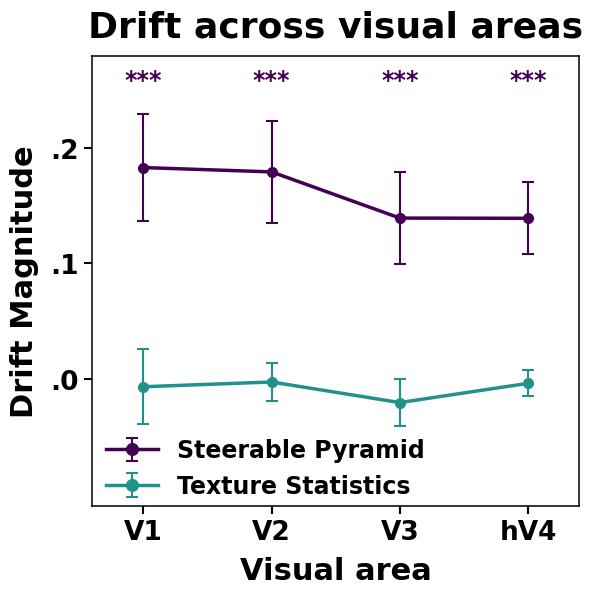


Saved: /content/drive/MyDrive/V1_Drift/plots/Gonda_Conf_figures/SP_vs_TS_RDM_rdmCorrDist_cmpRMSE_spearman_corr_drift_across_visual_areas.png


In [20]:
# ============================================================
# RDM DRIFT — SP vs TS
#
# RDM construction = correlation distance
# RDM comparison   = Spearman
#
# Drift magnitude:
#   raw Spearman correlation becomes more negative with drift
#   -> multiply by -1
#   -> larger positive value = stronger drift
#
# Plot:
#   SP mean ± SEM
#   TS mean ± SEM
#   NO subject lines
# ============================================================

import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from itertools import combinations
from statsmodels.stats.multitest import multipletests
from matplotlib.ticker import FuncFormatter


# ============================================================
# SETTINGS
# ============================================================

ROIS = ["V1", "V2", "V3", "hV4"]
N_SUBJECTS = 8

CORR_METHOD = "spearman"

RDM_BUILD_METRIC = "correlation"
RDM_COMPARE_METRIC = "rmse"

# "corr" or "slope"
USE_DRIFT_METRIC = "corr"

# Same as original pipeline
N_PERM = 1000
SEED = 1

# Larger positive value = stronger drift
CONVERT_TO_DRIFT_STRENGTH = True

POSTHOC_FOR_PLOT = "wilcoxon"


# ============================================================
# PATHS
# ============================================================

# ------------------------------------------------------------
# SP — 4-level model
# ------------------------------------------------------------

SP_SUMMARY_DIR = (
    "/content/drive/MyDrive/V1_Drift/"
    "plots/drift_summaries/rdm"
)


# ------------------------------------------------------------
# TS — pcaHL95, 4 ori × 4 SF
# ------------------------------------------------------------

TS_PERM_DIR = (
    "/content/drive/MyDrive/V2_drift/"
    "texturemodel/drift_results/"
    "population_permutations"
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/V1_Drift/"
    "plots/Gonda_Conf_figures"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ============================================================
# HELPERS
# ============================================================

TO_ZSCORE = 0


def _zstr(z):

    return [
        "",
        "_zscore",
        "_zeroMean",
        "_equalStd",
        "_zeroROImean"
    ][z]


def metric_tag(
    rdm_build_metric,
    rdm_compare_metric
):

    build_tag = {
        "correlation": "rdmCorrDist",
        "euclidean": "rdmEuclidean"
    }[rdm_build_metric]

    compare_tag = {
        "spearman": "cmpSpearman",
        "rmse": "cmpRMSE"
    }[rdm_compare_metric]

    return f"{build_tag}_{compare_tag}"


TAG = metric_tag(
    RDM_BUILD_METRIC,
    RDM_COMPARE_METRIC
)


def p_to_stars(p):

    if not np.isfinite(p):
        return ""

    if p < 0.001:
        return "***"

    if p < 0.01:
        return "**"

    if p < 0.05:
        return "*"

    return ""


def mean_sem(x):

    x = np.asarray(
        x,
        dtype=float
    )

    x = x[np.isfinite(x)]

    return (
        np.mean(x),
        stats.sem(x)
    )


# ============================================================
# CONVERT RAW METRIC -> DRIFT MAGNITUDE
# ============================================================

def convert_metric_to_drift_strength(
    values,
    compare_metric
):

    values = np.asarray(
        values,
        dtype=float
    )

    if not CONVERT_TO_DRIFT_STRENGTH:
        return values

    # Spearman RDM similarity decreases with lag.
    # Therefore stronger drift = more negative raw value.
    # Flip sign so larger positive = stronger drift.
    if compare_metric == "spearman":
        return -values

    # RMSE increases with drift, so direction already correct.
    if compare_metric == "rmse":
        return values

    raise ValueError(
        "RDM_COMPARE_METRIC must be "
        "'spearman' or 'rmse'"
    )


# ============================================================
# CALCULATE SUBJECT RDM DRIFT FROM FULL SESSION MATRIX
#
# Matches the SP subject_corr_metric calculation:
# correlation across all off-diagonal session pairs
# ============================================================

# ============================================================
# CALCULATE SUBJECT RDM DRIFT FROM FULL SESSION MATRIX
#
# Spearman:
#   correlation between session distance and
#   all off-diagonal RDM-similarity values
#
# RMSE:
#   RMSE values already represent dissimilarity between
#   session RDMs, so drift is quantified as the correlation
#   between session distance and all off-diagonal RMSE values.
#
# This matches the SP subject_corr_metric calculation.
# ============================================================

def matrix_distance_drift(
    mat,
    dist_matrix,
    compare_metric
):

    mat = np.asarray(
        mat,
        dtype=float
    )

    dist_matrix = np.asarray(
        dist_matrix,
        dtype=float
    )

    mask = (
        np.isfinite(mat)
        &
        (dist_matrix > 0)
    )

    if mask.sum() < 3:
        return np.nan

    x = dist_matrix[mask]
    y = mat[mask]

    # subject_corr_metric:
    # correlation of the session-pair metric with temporal distance
    if CORR_METHOD == "spearman":

        r, _ = stats.spearmanr(
            x,
            y
        )

    elif CORR_METHOD == "pearson":

        r, _ = stats.pearsonr(
            x,
            y
        )

    else:

        raise ValueError(
            CORR_METHOD
        )

    return float(r)

# ============================================================
# SELECT SP METRIC
# ============================================================

if USE_DRIFT_METRIC == "corr":

    metric_key = (
        "subject_corr_metric"
    )

elif USE_DRIFT_METRIC == "slope":

    metric_key = (
        "subject_slope_metric"
    )

else:

    raise ValueError(
        "USE_DRIFT_METRIC must be "
        "'corr' or 'slope'"
    )


# ============================================================
# LOAD SP — 4 LEVELS
# ============================================================

sp_subject = {}
sp_group_perm_p = {}

print(
    "\n"
    + "=" * 80
)

print(
    "SP RDM — 4-level model"
)

print(
    "=" * 80
)


for roi in ROIS:

    fn = os.path.join(
        SP_SUMMARY_DIR,
        (
            f"rdm_{roi}"
            f"{_zstr(TO_ZSCORE)}"
            f"_{TAG}"
            f"_{CORR_METHOD}"
            f"_corr_and_slope.pkl"
        )
    )

    if not os.path.exists(fn):

        raise FileNotFoundError(
            f"Missing SP summary:\n{fn}"
        )

    with open(fn, "rb") as f:

        d = pickle.load(f)

    raw_vals = np.asarray(
        d[metric_key],
        dtype=float
    )

    if raw_vals.shape != (
        N_SUBJECTS,
    ):

        raise ValueError(
            f"Unexpected SP {roi} "
            f"shape: {raw_vals.shape}"
        )

    # Convert to positive drift magnitude
    vals = convert_metric_to_drift_strength(
        raw_vals,
        RDM_COMPARE_METRIC
    )

    sp_subject[roi] = vals
    # Saved group permutation p-value from the SP pipeline
    if USE_DRIFT_METRIC == "corr":

        sp_group_perm_p[roi] = float(
            d["group_corr_p"]
        )

    elif USE_DRIFT_METRIC == "slope":

        sp_group_perm_p[roi] = float(
            d["group_slope_p"]
        )

    print(
        f"{roi:3s} | "
        f"n={len(vals)} | "
        f"mean drift={np.nanmean(vals):.4f}"
    )


# ============================================================
# LOAD TS
#
# Match SP exactly:
# observed drift = correlation between session distance
# and ALL off-diagonal RDM-similarity values
#
# permutation null = same calculation after each of the
# 1000 stored session-order permutations
# ============================================================

ts_subject = {}
ts_subject_perm = {}


print(
    "\n"
    + "=" * 80
)

print(
    "TS RDM — pcaHL95"
)

print(
    "=" * 80
)


for roi in ROIS:

    vals = np.full(
        N_SUBJECTS,
        np.nan
    )

    perm_vals = np.full(
        (N_SUBJECTS, N_PERM),
        np.nan
    )

    for si in range(N_SUBJECTS):

        subject = si + 1

        fn = os.path.join(
            TS_PERM_DIR,
            (
                f"permPop_TS_pcaHL95_raw_"
                f"N1000_"
                f"S{subject:02d}_"
                f"{roi}_"
                f"{TAG}.npz"
            )
        )

        if not os.path.exists(fn):

            raise FileNotFoundError(
                f"Missing TS RDM file:\n{fn}"
            )

        d = np.load(
            fn,
            allow_pickle=True
        )


        # ====================================================
        # OBSERVED MATRIX
        # ====================================================

        mat = np.asarray(
            d["betweenSessCorr"],
            dtype=float
        )

        if mat.shape != (30, 30):

            raise ValueError(
                f"Unexpected observed matrix shape "
                f"for S{subject:02d} {roi}: "
                f"{mat.shape}"
            )


        ns = mat.shape[0]

        dist_matrix = np.abs(
            np.subtract.outer(
                np.arange(ns),
                np.arange(ns)
            )
        )


        raw_drift = (
            matrix_distance_drift(
                mat,
                dist_matrix,
                RDM_COMPARE_METRIC
            )
        )

        vals[si] = (
            convert_metric_to_drift_strength(
                [raw_drift],
                RDM_COMPARE_METRIC
            )[0]
        )


        # ====================================================
        # PERMUTED MATRICES
        # ====================================================

        perm_mats = np.asarray(
            d["betweenSessCorrPerm"],
            dtype=float
        )


        if perm_mats.shape != (
            N_PERM,
            30,
            30
        ):

            raise ValueError(
                f"Unexpected permutation matrix shape "
                f"for S{subject:02d} {roi}: "
                f"{perm_mats.shape}"
            )


        for pi in range(N_PERM):

            raw_perm = (
                matrix_distance_drift(
                    perm_mats[pi],
                    dist_matrix,
                    RDM_COMPARE_METRIC
                )
            )

            perm_vals[
                si,
                pi
            ] = (
                convert_metric_to_drift_strength(
                    [raw_perm],
                    RDM_COMPARE_METRIC
                )[0]
            )


    ts_subject[roi] = vals

    ts_subject_perm[roi] = (
        perm_vals
    )


    print(
        f"{roi:3s} | "
        f"n={np.sum(np.isfinite(vals))} | "
        f"mean drift={np.nanmean(vals):.4f}"
    )


# ============================================================
# SUBJECT COUNTS
# ============================================================

print(
    "\nSubject counts:"
)

for roi in ROIS:

    print(
        f"{roi}: "
        f"SP={np.sum(np.isfinite(sp_subject[roi]))}, "
        f"TS={np.sum(np.isfinite(ts_subject[roi]))}"
    )


# ============================================================
# MEAN ± SEM
# ============================================================

sp_mean = []
sp_sem = []

ts_mean = []
ts_sem = []


for roi in ROIS:

    m, se = mean_sem(
        sp_subject[roi]
    )

    sp_mean.append(m)
    sp_sem.append(se)

    m, se = mean_sem(
        ts_subject[roi]
    )

    ts_mean.append(m)
    ts_sem.append(se)


sp_mean = np.asarray(
    sp_mean
)

sp_sem = np.asarray(
    sp_sem
)

ts_mean = np.asarray(
    ts_mean
)

ts_sem = np.asarray(
    ts_sem
)

# ============================================================
# SP ROI-LEVEL DRIFT SIGNIFICANCE
#
# Uses the group session-order permutation p-values
# already calculated and saved by the original SP pipeline.
# ============================================================

sp_rows = []

for roi in ROIS:

    vals = np.asarray(
        sp_subject[roi],
        dtype=float
    )

    sp_rows.append({

        "ROI": roi,

        "mean": np.nanmean(vals),

        "sem": stats.sem(
            vals,
            nan_policy="omit"
        ),

        "p_raw": sp_group_perm_p[roi]

    })


sp_roi_sig = pd.DataFrame(
    sp_rows
)


# FDR-BH across the four ROIs
sp_roi_sig["p_fdr"] = (
    multipletests(
        sp_roi_sig["p_raw"].values,
        alpha=0.05,
        method="fdr_bh"
    )[1]
)


sp_roi_sig["stars"] = (
    sp_roi_sig["p_fdr"]
    .apply(p_to_stars)
)


print(
    "\nSP ROI-level RDM drift:"
)

display(
    sp_roi_sig
)

# ============================================================
# TS ROI-LEVEL DRIFT SIGNIFICANCE
#
# Reproduce the SP session-order permutation procedure
# using the 1000 stored TS betweenSessCorrPerm matrices.
#
# FDR-BH across the four ROIs.
# ============================================================
# ============================================================


# ------------------------------------------------------------
# TS — GROUP SESSION-ORDER PERMUTATION TEST
# ------------------------------------------------------------

def ts_roi_permutation_tests(
    subject_dict,
    perm_dict
):

    rows = []

    for roi in ROIS:

        observed = np.asarray(
            subject_dict[roi],
            dtype=float
        )

        permuted = np.asarray(
            perm_dict[roi],
            dtype=float
        )

        # Observed group statistic:
        # mean drift across subjects
        observed_group = np.nanmean(
            observed
        )

        # Null group statistic:
        # mean across subjects for each permutation
        #
        # shape:
        # subjects × permutations
        # -> permutations
        perm_group = np.nanmean(
            permuted,
            axis=0
        )

        # We converted the metric so that
        # larger positive values = stronger drift.
        #
        # Therefore this is an upper-tail test.
        p = (
            np.sum(
                perm_group >= observed_group
            )
            + 1
        ) / (
            len(perm_group)
            + 1
        )

        rows.append({

            "ROI": roi,

            "mean": observed_group,

            "sem": stats.sem(
                observed,
                nan_policy="omit"
            ),

            "p_raw": p

        })


    df_sig = pd.DataFrame(
        rows
    )

    # FDR across four ROIs
    df_sig["p_fdr"] = (
        multipletests(
            df_sig["p_raw"].values,
            alpha=0.05,
            method="fdr_bh"
        )[1]
    )

    df_sig["stars"] = (
        df_sig["p_fdr"]
        .apply(p_to_stars)
    )

    return df_sig


ts_roi_sig = (
    ts_roi_permutation_tests(
        ts_subject,
        ts_subject_perm
    )
)


print(
    "\nTS ROI-level RDM drift:"
)

display(
    ts_roi_sig
)

# ============================================================
# ROI PAIRWISE DIFFERENCES WITHIN EACH MODEL
#
# Same approach as original RDM analysis:
# paired Wilcoxon
# FDR-BH across six ROI comparisons
# ============================================================

def roi_pairwise_tests(
    subject_dict
):

    rows = []

    for roi_a, roi_b in combinations(
        ROIS,
        2
    ):

        x = np.asarray(
            subject_dict[roi_a],
            dtype=float
        )

        y = np.asarray(
            subject_dict[roi_b],
            dtype=float
        )

        valid = (
            np.isfinite(x)
            &
            np.isfinite(y)
        )

        x = x[valid]
        y = y[valid]

        # Paired t-test
        t_stat, p_t = stats.ttest_rel(
            x,
            y
        )

        # Wilcoxon
        try:

            w_stat, p_w = stats.wilcoxon(
                x,
                y
            )

        except ValueError:

            w_stat = np.nan
            p_w = np.nan

        rows.append({

            "ROI_A": roi_a,
            "ROI_B": roi_b,

            "paired_t": t_stat,
            "p_paired_t": p_t,

            "wilcoxon_W": w_stat,
            "p_wilcoxon": p_w,

            "n": len(x)
        })

    df_pair = pd.DataFrame(
        rows
    )

    df_pair[
        "p_paired_t_fdr"
    ] = multipletests(
        df_pair["p_paired_t"],
        method="fdr_bh"
    )[1]

    df_pair[
        "p_wilcoxon_fdr"
    ] = multipletests(
        df_pair["p_wilcoxon"],
        method="fdr_bh"
    )[1]

    df_pair[
        "stars_paired_t_fdr"
    ] = (
        df_pair["p_paired_t_fdr"]
        .apply(p_to_stars)
    )

    df_pair[
        "stars_wilcoxon_fdr"
    ] = (
        df_pair["p_wilcoxon_fdr"]
        .apply(p_to_stars)
    )

    return df_pair


sp_pairwise = roi_pairwise_tests(
    sp_subject
)

ts_pairwise = roi_pairwise_tests(
    ts_subject
)


print(
    "\nSP ROI pairwise:"
)

display(
    sp_pairwise
)


print(
    "\nTS ROI pairwise:"
)

display(
    ts_pairwise
)


# ============================================================
# CHOOSE POST-HOC FOR PLOT
# ============================================================

if POSTHOC_FOR_PLOT == "wilcoxon":

    sig_col = "p_wilcoxon_fdr"
    stars_col = "stars_wilcoxon_fdr"

elif POSTHOC_FOR_PLOT == "paired_t":

    sig_col = "p_paired_t_fdr"
    stars_col = "stars_paired_t_fdr"

else:

    raise ValueError(
        POSTHOC_FOR_PLOT
    )


sp_sig_pairs = sp_pairwise[
    sp_pairwise[sig_col] < 0.05
].copy()


ts_sig_pairs = ts_pairwise[
    ts_pairwise[sig_col] < 0.05
].copy()


# ============================================================
# OPTIONAL: HIERARCHY TREND FOR EACH MODEL
#
# Same concept as original SP RDM analysis.
# Positive slope = drift magnitude increases V1 -> hV4
# ============================================================

roi_levels = np.arange(
    1,
    len(ROIS) + 1,
    dtype=float
)


def hierarchy_analysis(
    subject_dict,
    model_name
):

    slopes = []

    for si in range(
        N_SUBJECTS
    ):

        y = np.array([
            subject_dict[roi][si]
            for roi in ROIS
        ])

        valid = np.isfinite(y)

        if valid.sum() >= 3:

            result = stats.linregress(
                roi_levels[valid],
                y[valid]
            )

            slopes.append(
                result.slope
            )

        else:

            slopes.append(
                np.nan
            )

    slopes = np.asarray(
        slopes,
        dtype=float
    )

    valid_slopes = slopes[
        np.isfinite(slopes)
    ]

    # Wilcoxon, one-sided positive hierarchy
    try:

        W, p_w = stats.wilcoxon(
            valid_slopes,
            alternative="greater"
        )

    except ValueError:

        W = np.nan
        p_w = np.nan

    # Sign-flip permutation
    rng = np.random.default_rng(
        SEED
    )

    real_mean = np.mean(
        valid_slopes
    )

    perm_means = np.zeros(
        N_PERM
    )

    for i in range(
        N_PERM
    ):

        signs = rng.choice(
            [-1, 1],
            size=len(valid_slopes)
        )

        perm_means[i] = np.mean(
            valid_slopes * signs
        )

    p_perm = (
        np.sum(
            perm_means >= real_mean
        )
        + 1
    ) / (
        N_PERM + 1
    )

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"{model_name} hierarchy"
    )

    print(
        "=" * 80
    )

    print(
        f"Mean hierarchy slope = "
        f"{real_mean:.6f}"
    )

    print(
        f"Wilcoxon one-sided p = "
        f"{p_w:.6g}"
    )

    print(
        f"Permutation one-sided p = "
        f"{p_perm:.6g}"
    )

    return slopes


sp_hierarchy_slopes = hierarchy_analysis(
    sp_subject,
    "SP"
)


ts_hierarchy_slopes = hierarchy_analysis(
    ts_subject,
    "TS"
)


# ============================================================
# PLOT
# ============================================================

xpos = np.arange(
    len(ROIS)
)

roi_x = {
    roi: i
    for i, roi in enumerate(ROIS)
}


# ============================================================
# FIGURE
#
# Same physical size/alignment as the other figures
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 6.0)
)


ax.set_position([
    0.21,   # left
    0.15,   # bottom
    0.75,   # width
    0.75    # height
])


# ============================================================
# COLORS
# ============================================================

SP_COLOR = "#440154"
TS_COLOR = "#21918c"


# ============================================================
# MEAN ± SEM ONLY
#
# NO SUBJECT LINES
# ============================================================

ax.errorbar(
    xpos,
    sp_mean,
    yerr=sp_sem,

    marker="o",
    markersize=7,

    linewidth=2.5,

    capsize=4,
    capthick=1.5,
    elinewidth=1.5,

    color=SP_COLOR,

    label="Steerable Pyramid",

    zorder=4
)


ax.errorbar(
    xpos,
    ts_mean,
    yerr=ts_sem,

    marker="o",
    markersize=7,

    linewidth=2.5,

    capsize=4,
    capthick=1.5,
    elinewidth=1.5,

    color=TS_COLOR,

    label="Texture Statistics",

    zorder=4
)


# ============================================================
# DATA RANGE
# ============================================================

all_lower = np.concatenate([
    sp_mean - sp_sem,
    ts_mean - ts_sem
])


all_upper = np.concatenate([
    sp_mean + sp_sem,
    ts_mean + ts_sem
])


data_min = np.nanmin(
    all_lower
)

data_max = np.nanmax(
    all_upper
)

data_range = (
    data_max
    - data_min
)


if data_range == 0:

    data_range = (
        abs(data_max)
        if data_max != 0
        else 1.0
    )


# ============================================================
# ROI DRIFT STARS
#
# SP = upper row
# TS = lower row
# ============================================================

sp_star_y = (
    data_max
    + 0.07 * data_range
)

ts_star_y = (
    data_max
    + 0.01 * data_range
)


for i, roi in enumerate(
    ROIS
):

    # SP
    stars = sp_roi_sig.loc[
        sp_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            sp_star_y,
            stars,

            ha="center",
            va="bottom",

            fontsize=17,
            fontweight="bold",

            color=SP_COLOR
        )


    # TS
    stars = ts_roi_sig.loc[
        ts_roi_sig["ROI"] == roi,
        "stars"
    ].values[0]

    if stars != "":

        ax.text(
            xpos[i],
            ts_star_y,
            stars,

            ha="center",
            va="bottom",

            fontsize=17,
            fontweight="bold",

            color=TS_COLOR
        )


# ============================================================
# BRACKET FUNCTION
# ============================================================

def draw_bracket(
    ax,
    x1,
    x2,
    y,
    h,
    stars,
    color
):

    ax.plot(
        [
            x1,
            x1,
            x2,
            x2
        ],

        [
            y,
            y + h,
            y + h,
            y
        ],

        color=color,
        linewidth=1.5,
        clip_on=False
    )

    ax.text(
        (x1 + x2) / 2,
        y + h,
        stars,

        ha="center",
        va="bottom",

        fontsize=17,
        fontweight="bold",

        color=color
    )


# ============================================================
# SIGNIFICANT WITHIN-MODEL ROI DIFFERENCES
# ============================================================

bracket_base = (
    data_max
    + 0.18 * data_range
)

bracket_step = (
    0.09 * data_range
)

bracket_h = (
    0.025 * data_range
)


bracket_number = 0


# SP brackets
for _, row in sp_sig_pairs.iterrows():

    x1 = roi_x[
        row["ROI_A"]
    ]

    x2 = roi_x[
        row["ROI_B"]
    ]

    y = (
        bracket_base
        + bracket_number
        * bracket_step
    )

    draw_bracket(
        ax,
        x1,
        x2,
        y,
        bracket_h,
        row[stars_col],
        SP_COLOR
    )

    bracket_number += 1


# TS brackets
for _, row in ts_sig_pairs.iterrows():

    x1 = roi_x[
        row["ROI_A"]
    ]

    x2 = roi_x[
        row["ROI_B"]
    ]

    y = (
        bracket_base
        + bracket_number
        * bracket_step
    )

    draw_bracket(
        ax,
        x1,
        x2,
        y,
        bracket_h,
        row[stars_col],
        TS_COLOR
    )

    bracket_number += 1


# ============================================================
# Y LIMITS / TICKS
# ============================================================

if RDM_COMPARE_METRIC == "spearman":

    ymin = -0.05
    ymax = 0.20

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_yticks([
         0.0,
         0.1,
         0.2
    ])

elif RDM_COMPARE_METRIC == "rmse":

    ymin = -0.11
    ymax = 0.28

    ax.set_ylim(
        ymin,
        ymax
    )

    ax.set_yticks([
        0.0,
        0.1,
        0.2
    ])


# ============================================================
# Y TICK FORMAT
# ============================================================

def no_leading_zero(x, pos):

    if np.isclose(x, 0):
        return ".0"

    s = f"{x:.1f}"

    return (
        s.replace("-0.", "-.")
         .replace("0.", ".")
    )


ax.yaxis.set_major_formatter(
    FuncFormatter(no_leading_zero)
)

# ============================================================
# AXES
# ============================================================

ax.set_xticks(xpos)

ax.set_xticklabels(
    ROIS,
    fontsize=20,
    fontweight="bold"
)

ax.set_xlim(
    -0.4,
    len(ROIS) - 0.6
)

ax.set_xlabel(
    "Visual area",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_ylabel(
    "Drift Magnitude",
    fontsize=22,
    fontweight="bold",
    labelpad=8
)

ax.set_title(
    "Drift across visual areas",
    fontsize=26,
    fontweight="bold",
    pad=14
)


# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="both",
    labelsize=19,
    width=1.5,
    length=6
)

for tick in ax.get_yticklabels():
    tick.set_fontweight("bold")

for tick in ax.get_xticklabels():
    tick.set_fontweight("bold")


# ============================================================
# MODEL LEGEND
# ============================================================

legend = ax.legend(
    loc="lower left",
    bbox_to_anchor=(0.01, -0.005),
    frameon=False,
    fontsize=17,
    borderaxespad=0,
    handlelength=2.2,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")

# ============================================================
# SPINES
# ============================================================

for spine in [
    "top",
    "right",
    "bottom",
    "left"
]:

    ax.spines[
        spine
    ].set_visible(
        True
    )

    ax.spines[
        spine
    ].set_linewidth(
        1.1
    )


# ============================================================
# SAVE
# ============================================================

fig_path = os.path.join(
    OUT_DIR,
    (
        f"SP_vs_TS_RDM_"
        f"{TAG}_"
        f"{CORR_METHOD}_"
        f"{USE_DRIFT_METRIC}_"
        f"drift_across_visual_areas.png"
    )
)


plt.savefig(
    fig_path,
    dpi=300,
    pad_inches=0.20
)


plt.show()


print(
    "\nSaved:",
    fig_path
)

## relative to lag 1

LOADING SP RDM
V1: (8, 29)
V2: (8, 29)
V3: (8, 29)
hV4: (8, 29)

LOADING TS RDM
V1: (8, 29)
V2: (8, 29)
V3: (8, 29)
hV4: (8, 29)

CHECK
V1  | SP=(8, 29) | TS=(8, 29)
V2  | SP=(8, 29) | TS=(8, 29)
V3  | SP=(8, 29) | TS=(8, 29)
hV4 | SP=(8, 29) | TS=(8, 29)


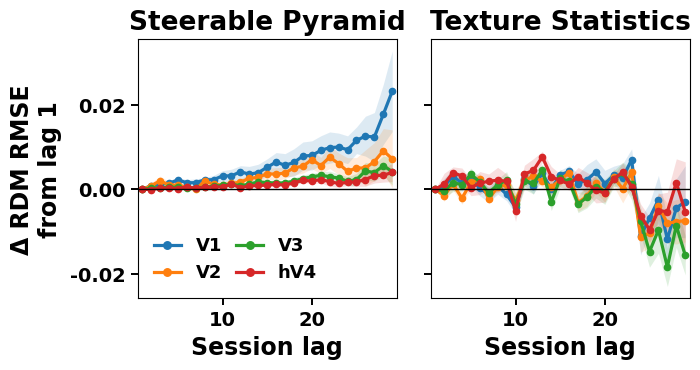


Saved:
/content/drive/MyDrive/V1_Drift/plots/Gonda_Conf_figures/SP_vs_TS_delta_RDM_similarity_relative_to_lag1_COMPACT.png
/content/drive/MyDrive/V1_Drift/plots/Gonda_Conf_figures/SP_vs_TS_delta_RDM_similarity_relative_to_lag1_COMPACT.pdf


In [37]:
# ============================================================
# RDM SIMILARITY DECLINE FROM LAG 1
# Steerable Pyramid vs Texture Statistics
#
# Standalone poster figure
# ============================================================

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


# ============================================================
# SETTINGS
# ============================================================

ROIS = ["V1", "V2", "V3", "hV4"]
N_SUBJECTS = 8

# ------------------------------------------------------------
# SP
# ------------------------------------------------------------

SP_SUMMARY_DIR = (
    "/content/drive/MyDrive/V1_Drift/"
    "plots/drift_summaries/rdm"
)

TO_ZSCORE = 0
CORR_METHOD = "pearson"

RDM_BUILD_METRIC = "correlation"
RDM_COMPARE_METRIC = "rmse"


# ------------------------------------------------------------
# TS
# ------------------------------------------------------------

TS_PERM_DIR = (
    "/content/drive/MyDrive/V2_drift/"
    "texturemodel/drift_results/"
    "population_permutations"
)


# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------

OUT_DIR = (
    "/content/drive/MyDrive/V1_Drift/"
    "plots/Gonda_Conf_figures"
)

os.makedirs(
    OUT_DIR,
    exist_ok=True
)


# ============================================================
# HELPERS
# ============================================================

def _zstr(z):

    return [
        "",
        "_zscore",
        "_zeroMean",
        "_equalStd",
        "_zeroROImean"
    ][z]


def metric_tag(
    rdm_build_metric,
    rdm_compare_metric
):

    build_tag = {
        "correlation": "rdmCorrDist",
        "euclidean": "rdmEuclidean"
    }[rdm_build_metric]

    compare_tag = {
        "spearman": "cmpSpearman",
        "rmse": "cmpRMSE"
    }[rdm_compare_metric]

    return f"{build_tag}_{compare_tag}"


TAG = metric_tag(
    RDM_BUILD_METRIC,
    RDM_COMPARE_METRIC
)


# ============================================================
# HELPER:
# session × session matrix -> lag curve
#
# Average BOTH upper and lower diagonals,
# exactly like the other lag analyses.
# ============================================================

def lag_curve_from_matrix(M):

    M = np.asarray(
        M,
        dtype=float
    )

    S = M.shape[0]

    curve = np.full(
        S - 1,
        np.nan
    )

    for lag in range(1, S):

        upper = np.diag(
            M,
            k=lag
        )

        lower = np.diag(
            M,
            k=-lag
        )

        values = np.concatenate(
            [upper, lower]
        )

        curve[lag - 1] = np.nanmean(
            values
        )

    return curve


# ============================================================
# LOAD SP SUBJECT-LEVEL RDM LAG CURVES
# ============================================================

sp_curves = {}

print("=" * 70)
print("LOADING SP RDM")
print("=" * 70)


for roi in ROIS:

    fn = os.path.join(
        SP_SUMMARY_DIR,
        (
            f"rdm_{roi}"
            f"{_zstr(TO_ZSCORE)}"
            f"_{TAG}"
            f"_{CORR_METHOD}"
            f"_corr_and_slope.pkl"
        )
    )

    if not os.path.exists(fn):

        raise FileNotFoundError(
            f"Missing SP RDM summary:\n{fn}"
        )

    with open(fn, "rb") as f:

        d = pickle.load(f)

    curves = np.asarray(
        d["subject_curves"],
        dtype=float
    )

    sp_curves[roi] = curves

    print(
        f"{roi}: {curves.shape}"
    )


# ============================================================
# LOAD TS RDM SUBJECT-LEVEL LAG CURVES
# ============================================================

ts_curves = {}

print("\n" + "=" * 70)
print("LOADING TS RDM")
print("=" * 70)


for roi in ROIS:

    roi_curves = []

    for si in range(N_SUBJECTS):

        subject = si + 1

        fn = os.path.join(
            TS_PERM_DIR,
            (
                f"permPop_TS_pcaHL95_raw_"
                f"N1000_"
                f"S{subject:02d}_"
                f"{roi}_"
                f"{TAG}.npz"
            )
        )

        if not os.path.exists(fn):

            raise FileNotFoundError(
                f"Missing TS RDM file:\n{fn}"
            )

        d = np.load(
            fn,
            allow_pickle=True
        )

        # ----------------------------------------
        # Already-computed RDM comparison by lag
        #
        # betweenSessDist contains 29 values:
        # one value for each session lag (1–29).
        #
        # Its meaning depends on TAG:
        #   cmpSpearman -> RDM similarity
        #   cmpRMSE     -> RDM RMSE
        # ----------------------------------------

        curve = np.asarray(
            d["betweenSessDist"],
            dtype=float
        )

        if curve.ndim != 1:

            raise ValueError(
                f"Unexpected TS lag-curve shape "
                f"S{subject:02d} {roi}: "
                f"{curve.shape}"
            )

        if curve.shape[0] != 29:

            raise ValueError(
                f"Expected 29 session lags, "
                f"got {curve.shape[0]} "
                f"for S{subject:02d} {roi}"
            )

        roi_curves.append(
            curve
        )

    # subjects × lags
    roi_curves = np.vstack(
        roi_curves
    )

    ts_curves[roi] = roi_curves

    print(
        f"{roi}: {roi_curves.shape}"
    )

# ============================================================
# SANITY CHECK
# ============================================================

print("\n" + "=" * 70)
print("CHECK")
print("=" * 70)


for roi in ROIS:

    print(
        f"{roi:3s} | "
        f"SP={sp_curves[roi].shape} | "
        f"TS={ts_curves[roi].shape}"
    )

    if sp_curves[roi].shape != ts_curves[roi].shape:

        print(
            "   WARNING: SP and TS shapes differ"
        )


# ============================================================
# FIGURE — POSTER STYLE
# ============================================================

from matplotlib.ticker import FormatStrFormatter

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.6, 3.7),
    sharex=True,
    sharey=True
)

model_data = [
    ("Steerable Pyramid", sp_curves),
    ("Texture Statistics", ts_curves)
]


for ax, (model_name, curves_dict) in zip(
    axes,
    model_data
):

    for roi in ROIS:

        curves = curves_dict[roi]

        # Each subject relative to own lag 1
        delta = (
            curves
            - curves[:, [0]]
        )

        mean_curve = np.nanmean(
            delta,
            axis=0
        )

        sem_curve = stats.sem(
            delta,
            axis=0,
            nan_policy="omit"
        )

        lags = np.arange(
            1,
            delta.shape[1] + 1
        )

        line, = ax.plot(
            lags,
            mean_curve,
            marker="o",
            markersize=4.5,
            linewidth=2.3,
            label=roi
        )

        ax.fill_between(
            lags,
            mean_curve - sem_curve,
            mean_curve + sem_curve,
            color=line.get_color(),
            alpha=0.15,
            linewidth=0
        )

    # Zero reference
    ax.axhline(
        0,
        color="black",
        linewidth=1.0
    )

    # PANEL TITLE
    ax.set_title(
        model_name,
        fontsize=19,
        fontweight="bold",
        pad=7
    )

    # X AXIS TITLE
    ax.set_xlabel(
        "Session lag",
        fontsize=17,
        fontweight="bold",
        labelpad=5
    )

    # TICK LABELS
    ax.tick_params(
        axis="both",
        labelsize=14,
        width=1.4,
        length=5
    )

    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")

    for tick in ax.get_yticklabels():
        tick.set_fontweight("bold")

    # Square plotting region
    ax.set_box_aspect(1)

    ax.set_xlim(
        0.5,
        29.5
    )


# ============================================================
# Y AXIS
# ============================================================

if RDM_COMPARE_METRIC == "spearman":
    ylabel = "Δ RDM similarity\nfrom lag 1"

elif RDM_COMPARE_METRIC == "rmse":
    ylabel = "Δ RDM RMSE\nfrom lag 1"

else:
    raise ValueError(
        f"Unknown RDM_COMPARE_METRIC: {RDM_COMPARE_METRIC}"
    )


axes[0].set_ylabel(
    ylabel,
    fontsize=17,
    fontweight="bold",
    labelpad=6
)

axes[0].yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)
# ============================================================
# LEGEND
# ============================================================

legend = axes[0].legend(
    frameon=False,
    fontsize=13,
    loc="lower left",
    ncol=2,
    handlelength=1.5,
    columnspacing=0.8,
    markerscale=1.2
)

for text in legend.get_texts():
    text.set_fontweight("bold")


# ============================================================
# COMPACT LAYOUT
# ============================================================

fig.subplots_adjust(
    left=0.14,
    right=0.995,
    bottom=0.21,
    top=0.91,
    wspace=0.08
)

# ============================================================
# SAVE
# ============================================================

png_path = os.path.join(
    OUT_DIR,
    "SP_vs_TS_delta_RDM_similarity_relative_to_lag1_COMPACT.png"
)

pdf_path = os.path.join(
    OUT_DIR,
    "SP_vs_TS_delta_RDM_similarity_relative_to_lag1_COMPACT.pdf"
)


fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()


print("\nSaved:")
print(png_path)
print(pdf_path)